# Tema 2 IA — Cerinta 3.1: Vizualizarea augmentarilor

In [1]:
import os

# PASUL 1: ce e in /kaggle/input/?
print("/kaggle/input/ contine:", os.listdir('/kaggle/input'))

# PASUL 2: merge recursiv pana gaseste train.csv si kaggle_test.csv
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f in ['train.csv', 'kaggle_test.csv', 'norm_stats.json']:
            print(os.path.join(root, f))

/kaggle/input/ contine: ['datasets']
/kaggle/input/datasets/biancapetrea/tema-2-ia/vai-de-pielea-mea/kaggle_test.csv
/kaggle/input/datasets/biancapetrea/tema-2-ia/vai-de-pielea-mea/train.csv
/kaggle/input/datasets/biancapetrea/tema-2-ia/you-re-on-candid-camera/splits/norm_stats.json
/kaggle/input/datasets/biancapetrea/tema-2-ia/you-re-on-candid-camera/splits/train.csv


## Montare drive si instalare librarii

In [2]:
# ca sa pot accesa arhivele si sa salvez rezultatele
# from google.colab import drive
# drive.mount('/content/drive')

# # calea unde am pus arhivele in drive
# DRIVE_BASE = '/content/drive/MyDrive/Tema2-IA'

In [3]:
!pip install albumentations --quiet

In [4]:
import os
# import zipfile

# extrag arhivele din drive in /content
DATA_DIR = '/kaggle/working/data'
os.makedirs(DATA_DIR, exist_ok=True)

# # arhiva 1: expresii faciale
# zip1 = os.path.join(DRIVE_BASE, 'you-re-on-candid-camera.zip')
# with zipfile.ZipFile(zip1, 'r') as z:
#     z.extractall(os.path.join(DATA_DIR, 'candid'))

# # arhiva 2: leziuni
# zip2 = os.path.join(DRIVE_BASE, 'vai-de-pielea-mea.zip')
# with zipfile.ZipFile(zip2, 'r') as z:
#     z.extractall(os.path.join(DATA_DIR, 'piele'))

In [7]:
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

import torch
from torchvision import transforms

import albumentations as A
from albumentations.pytorch import ToTensorV2

# augmentarile sunt aleatoare, dar cu seed fix vor fi mereu aceleasi rez vizuale
np.random.seed(42)
torch.manual_seed(42)

## Dataset 1: "You're on Candid Camera" — Expresii Faciale

Structura: imagini 100×100 RGB în DATASET/train/{clasa}/, referite prin splits/train.csv  
Clase: 1=Surprise, 2=Fear, 3=Disgust, 4=Happiness, 5=Sadness, 6=Anger, 7=Neutral

## 2. Incarcarea unui exemplu per clasa (Candid Camera)

In [8]:
# INCARCAREA DATASET-ULUI
CANDID_ROOT = '/kaggle/input/datasets/biancapetrea/tema-2-ia/you-re-on-candid-camera'
CANDID_TRAIN_CSV = os.path.join(CANDID_ROOT, 'splits/train.csv')

# maparea numerelor la numele emotilor
CANDID_CLASSES = {
    1: 'Surprise',
    2: 'Fear',
    3: 'Disgust',
    4: 'Happiness',
    5: 'Sadness',
    6: 'Anger',
    7: 'Neutral'
}

# citesc CSV-ul de train
# df_candid va fi un DataFrame cu coloanele "path" si "label"
# fiecare rand = o imagine din setul de train
df_candid = pd.read_csv(CANDID_TRAIN_CSV)
print(f'- total imagini train: {len(df_candid)}')
print(df_candid.head(3))
print()
print('- numar imagini per clasa:')
counts = df_candid['label'].value_counts().sort_index()
for cls_id, count in counts.items():
    print(f'   clasa {cls_id} ({CANDID_CLASSES[cls_id]:10s}): {count:5d} imagini')

- total imagini train: 10434
                                      path  label
0  DATASET/train/1/train_03315_aligned.jpg      1
1  DATASET/train/1/train_02647_aligned.jpg      1
2  DATASET/train/1/train_05697_aligned.jpg      1

- numar imagini per clasa:
   clasa 1 (Surprise  ):  1097 imagini
   clasa 2 (Fear      ):   239 imagini
   clasa 3 (Disgust   ):   610 imagini
   clasa 4 (Happiness ):  4057 imagini
   clasa 5 (Sadness   ):  1685 imagini
   clasa 6 (Anger     ):   600 imagini
   clasa 7 (Neutral   ):  2146 imagini


In [9]:
# SELECTAREA UNEI IMAGINI REPREZENTATIVE DIN FIECARE CLASA
# pentru vizualizarea augmentarilor am nevoie de exact o imagine per clasa
def get_one_image_per_class_candid(df, root, class_map):
    # returneaza un dict {clasa_int: PIL.Image} cu cate o imagine per clasa
    # aleg primul exemplu din fiecare clasa
    images = {}
    # iterez prin dictionarul CANDID_CLASSES (cls_id = 1,2..7)
    for cls_id, cls_name in class_map.items():
        # pentru fiecare cls_id, filtrez dataframe-ul
        # selectez doar randurile unde coloana label are val cls_di
        rows = df[df['label'] == cls_id]
        if len(rows) == 0:
            print(f'nicio imagine pentru clasa {cls_id} ({cls_name})')
            continue
        # iau primul rand din lista filtrata,
        # pentru care extrag calea relativa si construiesc calea completa pe disc
        rel_path = rows.iloc[0]['path']
        full_path = os.path.join(root, rel_path)
        # deschid imaginea cu PIL si o convertesc la RGB (3 canale)
        # necesar pt Albumetations si PyTorch
        images[cls_id] = Image.open(full_path).convert('RGB')
    return images

# apelez functia si obtin un dict cu 7 imagini PIL (una per clasa)
candid_examples = get_one_image_per_class_candid(df_candid, CANDID_ROOT, CANDID_CLASSES)
print(f'am incarcat {len(candid_examples)} imagini (cate una per clasa)')

am incarcat 7 imagini (cate una per clasa)


## 3. Definirea augmentarilor pentru Candid Camera

In [10]:
# DEFINIREA AUGMENTARILOR PENTRU EXPRESII FACIALE - pe TRAIN
candid_train_aug = A.Compose([
    A.Resize(108, 108),
    A.RandomCrop(96, 96),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=10, p=0.5),
    A.RandomBrightnessContrast(
        brightness_limit=0.25,
        contrast_limit=0.25,
        p=0.7
    ),
    A.HueSaturationValue(
        hue_shift_limit=10,
        sat_shift_limit=20,
        val_shift_limit=15,
        p=0.5
    ),
    A.GaussianBlur(blur_limit=(3, 3), p=0.3),
    A.CoarseDropout(
        num_holes_range=(1, 2),
        hole_height_range=(1, 12),
        hole_width_range=(1, 12),
        p=0.3
    ),
    A.Normalize(
        mean=[0.5752, 0.4497, 0.4013],
        std=[0.2653, 0.2423, 0.2407]
    ),
    ToTensorV2(),
])

# pipeline pentru VALIDARE si TEST — fara nicio augmentare aleatoare
# e esential ca val/test sa primeasca mereu exact aceeasi transformare
# — altfel masor performanta pe date modificate aleator, nu pe date "reale"
candid_val_transform = A.Compose([
    A.Resize(96, 96),
    A.Normalize(
        mean=[0.5752, 0.4497, 0.4013],
        std=[0.2653, 0.2423, 0.2407]
    ),
    ToTensorV2(),
])

print('Pipeline-uri de augmentare definite pentru Candid Camera.')
print(f'  Train: {len(candid_train_aug)} transformari')
print(f'  Val/Test: {len(candid_val_transform)} transformari (fixe)')

Pipeline-uri de augmentare definite pentru Candid Camera.
  Train: 10 transformari
  Val/Test: 3 transformari (fixe)


## 4. Vizualizarea augmentarilor (Candid Camera)

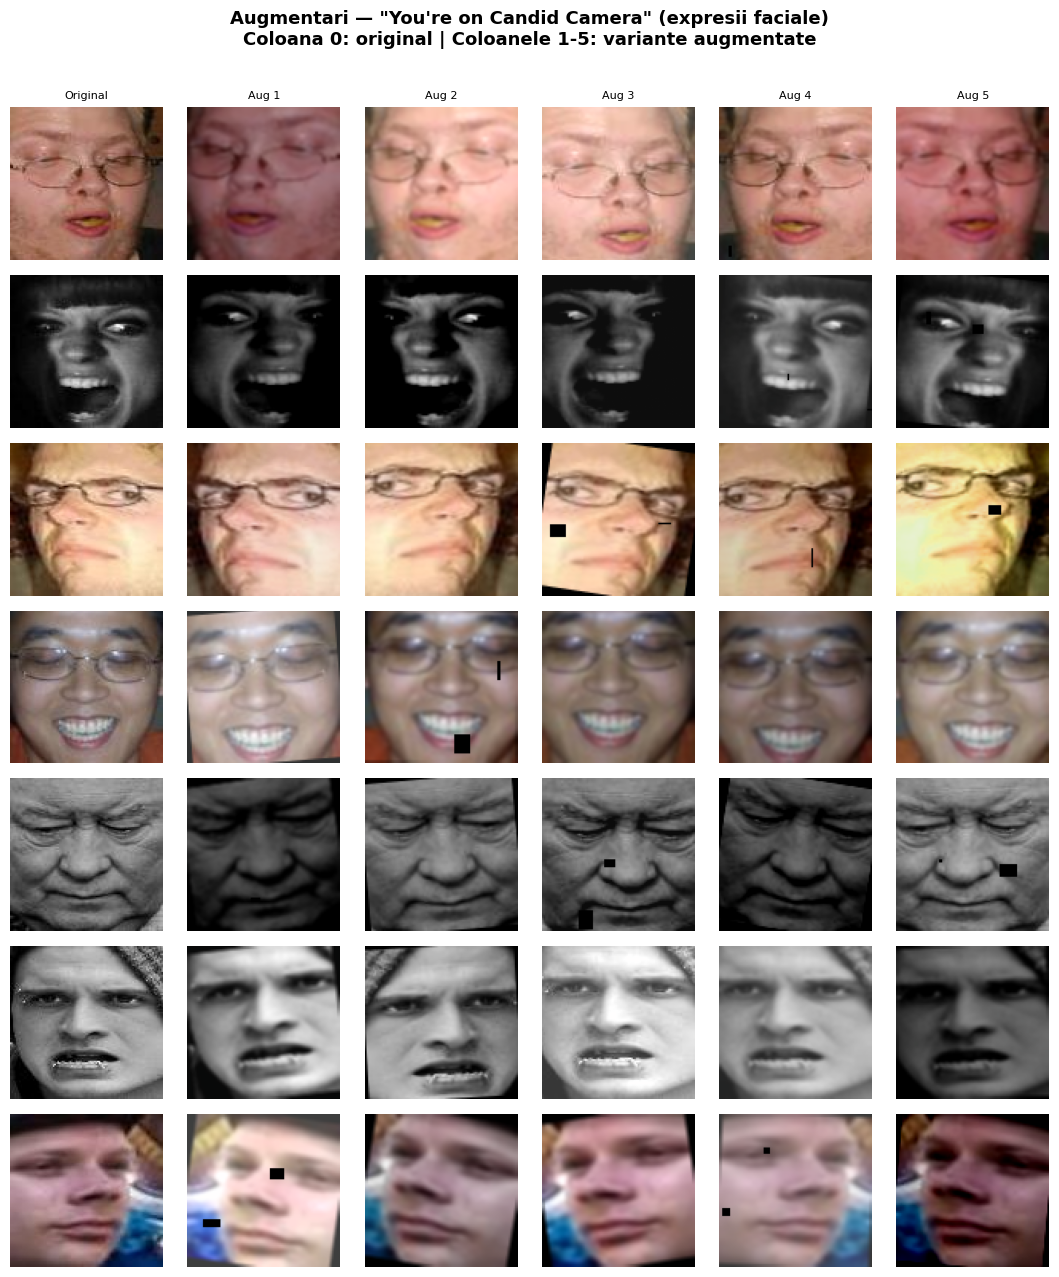

salvata in /kaggle/working/results/augmentari_candid.png


In [11]:
def denormalize(tensor, mean, std):
    # parametri:
    # tensor : tensor PyTorch de forma (C, H, W), normalizat
    # mean   : lista cu media per canal, ex: [0.5752, 0.4497, 0.4013]
    # std    : lista cu deviatia standard per canal
    mean = torch.tensor(mean).view(3, 1, 1)
    std  = torch.tensor(std).view(3, 1, 1)
    return torch.clamp(tensor * std + mean, 0, 1)


def visualize_augmentations(examples, augmentation, class_map,
                             mean, std, n_aug=5, title=''):
    n_classes = len(examples)
    n_cols    = 1 + n_aug
    fig, axes = plt.subplots(
        n_classes, n_cols,
        figsize=(n_cols * 1.8, n_classes * 1.8)
    )
    fig.suptitle(title, fontsize=13, fontweight='bold', y=1.01)

    if n_classes == 1:
        axes = axes[np.newaxis, :]

    for row_idx, (cls_id, pil_img) in enumerate(examples.items()):
        img_np = np.array(pil_img)

        # col 0: imaginea originala (fara nicio transformare)
        ax = axes[row_idx, 0]
        ax.imshow(img_np)
        ax.axis('off')
        # eticheta clasei pe prima coloana
        ax.set_ylabel(
            f"{cls_id}: {class_map[cls_id]}",
            rotation=0, labelpad=65,
            fontsize=8, va='center', ha='right'
        )
        if row_idx == 0:
            ax.set_title('Original', fontsize=8)

        # col 1..n_aug: variante augmentate
        for aug_idx in range(n_aug):
            ax = axes[row_idx, aug_idx + 1]

            # aplic augmentarea — fiecare apel produce o varianta diferita
            # deoarece transformarile sunt aleatoare (random seed diferit la fiecare apel)
            augmented = augmentation(image=img_np)
            tensor    = augmented['image']
            img_vis   = denormalize(tensor, mean, std)
            img_vis   = img_vis.permute(1, 2, 0).numpy()

            ax.imshow(img_vis)
            ax.axis('off')
            if row_idx == 0:
                ax.set_title(f'Aug {aug_idx + 1}', fontsize=8)

    plt.tight_layout()
    return fig


# generez si salvez iamginea pt expr faciale
CANDID_MEAN = [0.5752, 0.4497, 0.4013]
CANDID_STD  = [0.2653, 0.2423, 0.2407]

fig_candid = visualize_augmentations(
    candid_examples,
    candid_train_aug,
    CANDID_CLASSES,
    CANDID_MEAN, CANDID_STD,
    n_aug=5,
    title='Augmentari — "You\'re on Candid Camera" (expresii faciale)\n'
          'Coloana 0: original | Coloanele 1-5: variante augmentate'
)
# salvez img
os.makedirs('/kaggle/working/results', exist_ok=True)
fig_candid.savefig('/kaggle/working/results/augmentari_candid.png',
                   dpi=150, bbox_inches='tight')
plt.show()
print('salvata in /kaggle/working/results/augmentari_candid.png')

## Dataset 2: "Vai de Pielea Mea" — Leziuni Cutanate

Structura: imagini 130×100 RGB în train/, referite prin train.csv (imagine, diagnostic)  
Clase: akiec, bcc, bkl, df, mel, nv, vasc

## Incarcarea unui exemplu per clasa (Piele)

In [12]:
PIELE_ROOT = '/kaggle/input/datasets/biancapetrea/tema-2-ia/vai-de-pielea-mea'
PIELE_TRAIN_CSV = os.path.join(PIELE_ROOT, 'train.csv')

# maparea codurilor la descrieri
PIELE_CLASSES = {
    'akiec': 'Bowel disease',
    'bcc':   'Carcinom bazocelular',
    'bkl':   'Keratoză benignă',
    'df':    'Dermatofibrom',
    'mel':   'Melanom',
    'nv':    'Nevi melanocitari',
    'vasc':  'Leziuni vasculare'
}

df_piele = pd.read_csv(PIELE_TRAIN_CSV)
print(f'- total imagini train: {len(df_piele)}')
print(df_piele.head(3))
print()
print('- distributie clase:')
print(df_piele['diagnostic'].value_counts())

- total imagini train: 6009
            imagine diagnostic
0  ISIC_0026655.jpg         nv
1  ISIC_0031765.jpg         nv
2  ISIC_0033335.jpg         nv

- distributie clase:
diagnostic
nv       4023
mel       668
bkl       660
bcc       308
akiec     196
vasc       85
df         69
Name: count, dtype: int64


In [13]:
def get_one_image_per_class_piele(df, root, class_map):
    # returneaza un dict {clasa_int: PIL.Image} cu cate o imagine per clasa
    # aleg primul exemplu din fiecare clasa
    images = {}
    for cls_code in class_map.keys():
        rows = df[df['diagnostic'] == cls_code]
        if len(rows) == 0:
            print(f'nicio imagine pentru clasa {cls_code}')
            continue
        fname     = rows.iloc[0]['imagine']
        full_path = os.path.join(root, 'train', fname)
        images[cls_code] = Image.open(full_path).convert('RGB')
    return images

piele_examples = get_one_image_per_class_piele(df_piele, PIELE_ROOT, PIELE_CLASSES)
print(f'am incarcat {len(piele_examples)} imagini (câte una per clasă)')

am incarcat 7 imagini (câte una per clasă)


## Definirea augmentarilor pentru Vai de Pielea Mea

In [14]:
# augmentari pentru antrenare (vai de pielea mea)
piele_train_aug = A.Compose([
    A.Resize(128, 128),
    # flip orizontal — leziunile nu au orientare stanga-dreapta
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    # rotatie la multipli de 90 grade (0, 90, 180, 270)
    A.RandomRotate90(p=0.5),
    # rotatie fina (+-30 grade) pentru unghiuri intermediare
    A.Rotate(limit=30, p=0.5),
    # variatii de luminozitate si contrast — limite mici (importanta clinica)
    A.RandomBrightnessContrast(
        brightness_limit=0.15,
        contrast_limit=0.15,
        p=0.5
    ),
    # variatii minore de nuanta/saturatie — limite foarte mici (diagnostic medical)
    A.HueSaturationValue(
        hue_shift_limit=8,
        sat_shift_limit=15,
        val_shift_limit=10,
        p=0.4
    ),
    # blur gaussian foarte usor — simuleaza mici imperfectiuni optice
    A.GaussianBlur(blur_limit=(3, 3), p=0.2),
    # normalizare cu statisticile din enunt (rgb)
    A.Normalize(
        mean=[0.7646, 0.5464, 0.5712],
        std=[0.1410, 0.1532, 0.1706]
    ),
    ToTensorV2(),
])

# transformare pentru validare/test (fara augmentari aleatoare)
piele_val_transform = A.Compose([
    A.Resize(128, 128),
    A.Normalize(
        mean=[0.7646, 0.5464, 0.5712],
        std=[0.1410, 0.1532, 0.1706]
    ),
    ToTensorV2(),
])

## 7. Vizualizarea augmentărilor (Piele)

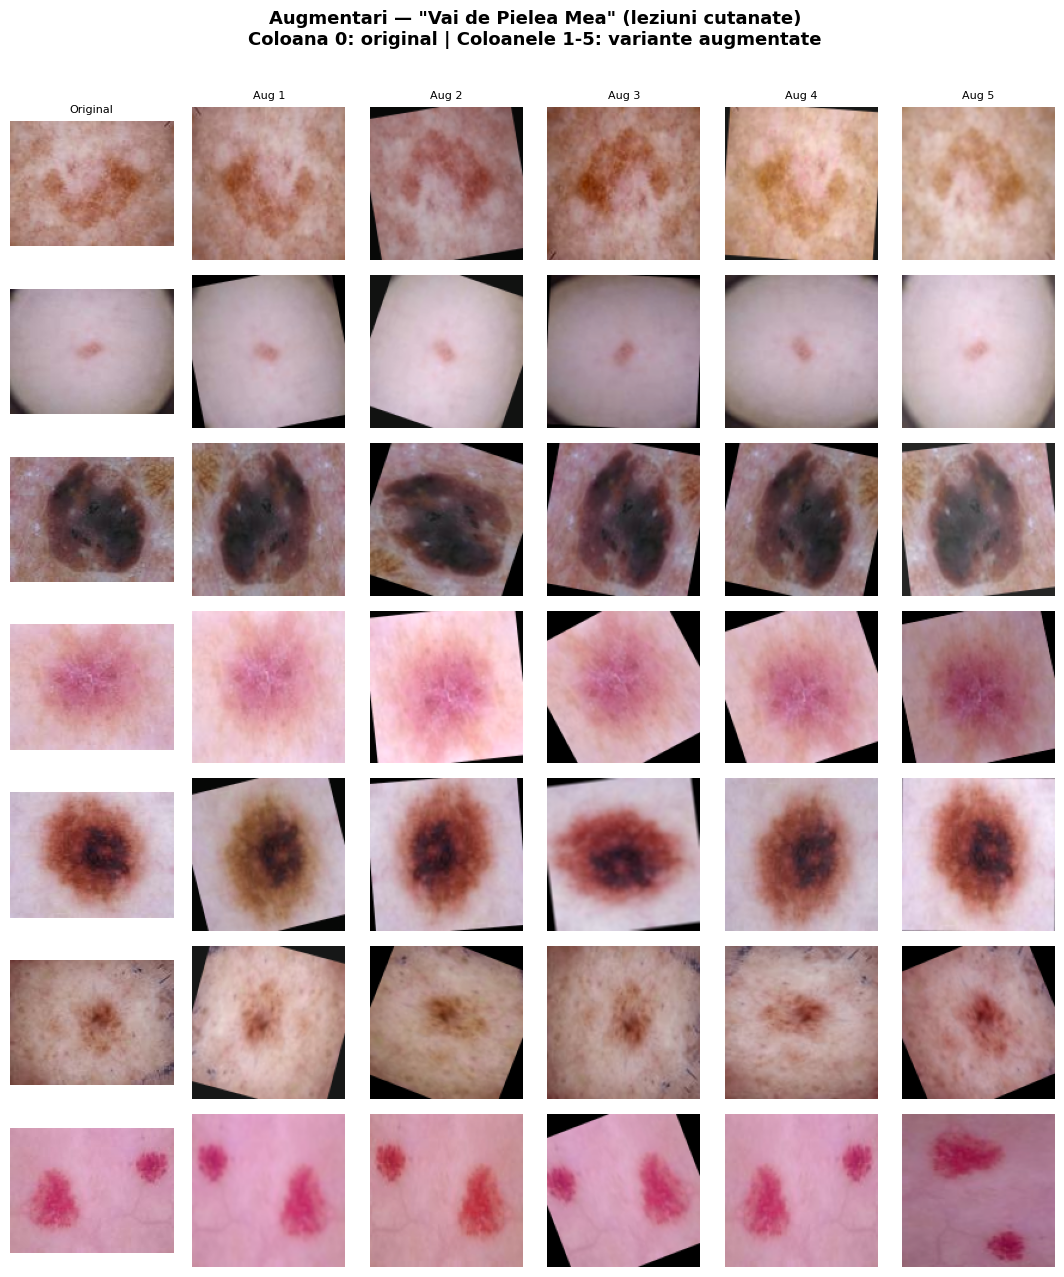

salvata in /kaggle/working/results/augmentari_piele.png


In [15]:
PIELE_MEAN = [0.7646, 0.5464, 0.5712]
PIELE_STD  = [0.1410, 0.1532, 0.1706]

fig_piele = visualize_augmentations(
    piele_examples,
    piele_train_aug,
    PIELE_CLASSES,
    PIELE_MEAN, PIELE_STD,
    n_aug=5,
    title='Augmentari — "Vai de Pielea Mea" (leziuni cutanate)\n'
          'Coloana 0: original | Coloanele 1-5: variante augmentate'
)

fig_piele.savefig('/kaggle/working/results/augmentari_piele.png',
                  dpi=150, bbox_inches='tight')
plt.show()
print('salvata in /kaggle/working/results/augmentari_piele.png')

## 8. Dataset-uri PyTorch cu augmentari integrate

Clasele de mai jos sunt gata de folosit in cerintele 3.2–3.5.

In [16]:
from torch.utils.data import Dataset, DataLoader

class CandidCameraDataset(Dataset):
    # dataset pentru 'you're on candid camera'.
    # citeste din csv-ul cu coloanele (path, label).
    def __init__(self, csv_path, root, transform=None):
        self.df        = pd.read_csv(csv_path)
        self.root      = root
        self.transform = transform

        # etichetele din csv sunt 1-indexed (1..7), le fac 0-indexed (0..6)
        # pentru crossentropyloss care asteapta clase de la 0
        self.df['label_0idx'] = self.df['label'] - 1

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        path  = os.path.join(self.root, row['path'])
        label = int(row['label_0idx'])

        img = Image.open(path).convert('RGB')
        img_np = np.array(img)  # albumentations lucreaza cu numpy, nu pil

        if self.transform is not None:
            img_np = self.transform(image=img_np)['image']

        return img_np, label


class PieleDataset(Dataset):
    # maparea codurilor text la indici numerici (0-indexed)
    CLASS_TO_IDX = {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3,
                    'mel': 4, 'nv': 5, 'vasc': 6}
    IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}

    def __init__(self, csv_path, img_dir, transform=None):
        self.df        = pd.read_csv(csv_path)
        self.img_dir   = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        fname = row['imagine']
        label = self.CLASS_TO_IDX[row['diagnostic']]  # 0..6

        path   = os.path.join(self.img_dir, fname)
        img    = Image.open(path).convert('RGB')
        img_np = np.array(img)

        if self.transform is not None:
            img_np = self.transform(image=img_np)['image']

        return img_np, label


# verific daca dataset-urile functioneaza
ds_candid_train = CandidCameraDataset(
    csv_path = os.path.join(CANDID_ROOT, 'splits/train.csv'),
    root     = CANDID_ROOT,
    transform= candid_train_aug
)

ds_piele_train = PieleDataset(
    csv_path = PIELE_TRAIN_CSV,
    img_dir  = os.path.join(PIELE_ROOT, 'train'),
    transform= piele_train_aug
)

img, label = ds_candid_train[0]
print(f'Candid — shape tensor: {img.shape}, label: {label} ({CANDID_CLASSES[label+1]})')

img, label = ds_piele_train[0]
print(f'Piele  — shape tensor: {img.shape}, label: {label} ({PieleDataset.IDX_TO_CLASS[label]})')

Candid — shape tensor: torch.Size([3, 96, 96]), label: 0 (Surprise)
Piele  — shape tensor: torch.Size([3, 128, 128]), label: 5 (nv)


## 9. Copiem rezultatele pe Drive (pentru a nu le pierde la restart)

In [15]:
import shutil

# # folderul de rezultate pe Drive
# RESULTS_DRIVE = os.path.join(DRIVE_BASE, 'results')
# os.makedirs(RESULTS_DRIVE, exist_ok=True)

# # copiez figurile
# shutil.copy('/content/results/augmentari_candid.png', RESULTS_DRIVE)
# shutil.copy('/content/results/augmentari_piele.png', RESULTS_DRIVE)

# print('salvat pe drive in:', RESULTS_DRIVE)

---
---
# Cerinta 3.2 — Arhitectura MLP

In [24]:
import torch.nn as nn
import torch.optim as optim
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score
import seaborn as sns
import numpy as np
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Ascunde mesajele de info/warning TensorFlow

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'dispozitiv folosit: {device}')

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if device == 'cuda':
    torch.cuda.manual_seed(SEED)

RESULTS_DIR = '/kaggle/working/results/mlp'
os.makedirs(RESULTS_DIR, exist_ok=True)

dispozitiv folosit: cuda


## 2. dataloader-uri

In [25]:
# creez dataset-urile de validare
# (train-urile au fost create deja la cerinta 3.1 — reutilizez ds_candid_train
# si ds_piele_train care sunt deja in memorie)

# LOCAL TEST = setul pe care il evaluez, cu etichete cunoscute
# REMOTE TEST = setul de pe Kaggle, fara etichete
ds_candid_val = CandidCameraDataset(
    csv_path  = os.path.join(CANDID_ROOT, 'splits/local_test.csv'),
    root      = CANDID_ROOT,
    transform = candid_val_transform
)

# validare piele: citeste din test.csv
ds_piele_val = PieleDataset(
    csv_path  = os.path.join(PIELE_ROOT, 'test.csv'),
    img_dir   = os.path.join(PIELE_ROOT, 'test'),
    transform = piele_val_transform
)

# DataLoader-uri

BATCH_SIZE = 64

dl_candid_train = DataLoader(
    ds_candid_train,
    batch_size  = BATCH_SIZE,
    shuffle     = True,
    num_workers = 2,
    drop_last   = True
)
dl_candid_val = DataLoader(
    ds_candid_val,
    batch_size  = BATCH_SIZE,
    shuffle     = False,
    num_workers = 2
)

dl_piele_train = DataLoader(
    ds_piele_train,
    batch_size  = BATCH_SIZE,
    shuffle     = True,
    num_workers = 2,
    drop_last   = True
)
dl_piele_val = DataLoader(
    ds_piele_val,
    batch_size  = BATCH_SIZE,
    shuffle     = False,
    num_workers = 2
)

print(f'candid: {len(ds_candid_train)} train, {len(ds_candid_val)} val')
print(f'piele:  {len(ds_piele_train)} train, {len(ds_piele_val)} val')

# verificare: iau un singur batch si verific dimensiunile
imgs, labels = next(iter(dl_candid_train))
print(f'\nforma batch candid: imagini={imgs.shape}, etichete={labels.shape}')


candid: 10434 train, 1837 val
piele:  6009 train, 2003 val

forma batch candid: imagini=torch.Size([64, 3, 96, 96]), etichete=torch.Size([64])


## 3. definirea arhitecturii MLP

In [26]:
class MLP(nn.Module):
    def __init__(self, input_size, num_classes, use_dropout=True):
        super().__init__()

        # ratele de dropout — daca use_dropout=False, p = 0.0
        p1 = 0.4 if use_dropout else 0.0  # primele doua straturi: mai agresiv
        p2 = 0.4 if use_dropout else 0.0
        p3 = 0.3 if use_dropout else 0.0  # al treilea strat: mai bland

        # nn.Sequential: aplica straturile in rodine, unul dupa altul
        # este echivalentul unui pipeline — iesirea unui strat e intrarea urmatorului
        self.net = nn.Sequential(
            nn.Flatten(),

            # BLOC 1: intrare -> 1024 neuroni
            nn.Linear(input_size, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(inplace=True),
            nn.Dropout(p=p1),

            # BLOC 2: 1024 -> 512 neuroni
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=p2),

            # BLOC 3: 512 -> 256 neuroni
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=p3),

            # STRAT DE IESIRE: 256 -> 7 (num_classes)
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        # forward defineste cum circula datele prin retea
        return self.net(x)


# verif arhitectura
test_model   = MLP(input_size=3*96*96, num_classes=7).to(device)
dummy_input  = torch.randn(4, 3, 96, 96).to(device)  # 4 imagini fictive
dummy_output = test_model(dummy_input)
print(f'forma iesire model candid: {dummy_output.shape}')

# numaram parametrii antrenabili
# requires_grad=True: parametrii care se invata prin backpropagation
n_params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)
print(f'numar parametri antrenabili: {n_params:,}')

print('\narhitectura detaliata:')
print(test_model)
del test_model, dummy_input, dummy_output


forma iesire model candid: torch.Size([4, 7])
numar parametri antrenabili: 28,974,087

arhitectura detaliata:
MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=27648, out_features=1024, bias=True)
    (2): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU(inplace=True)
    (4): Dropout(p=0.4, inplace=False)
    (5): Linear(in_features=1024, out_features=512, bias=True)
    (6): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): Dropout(p=0.4, inplace=False)
    (9): Linear(in_features=512, out_features=256, bias=True)
    (10): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): Dropout(p=0.3, inplace=False)
    (13): Linear(in_features=256, out_features=7, bias=True)
  )
)


## 4. bucla de antrenare

In [38]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct    = 0
    total      = 0

    for images, labels in loader:
        # mutam datele pe dispozitivul tinta (CPU sau GPU)
        images = images.to(device)
        labels = labels.to(device)

        # resatare gradienti
        optimizer.zero_grad()
        # forward pass
        logits = model(images)
        # calcul loss
        loss = criterion(logits, labels)
        # backword pass
        loss.backward()
        # pas de optimizare
        optimizer.step()

        # statistici logging
        total_loss += loss.item() * images.size(0)
        preds    = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total   += labels.size(0)

    # returnez loss mediu per exemplu si acuratete pe epoca
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct    = 0
    total      = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss   = criterion(logits, labels)

        total_loss += loss.item() * images.size(0)
        preds       = logits.argmax(dim=1)
        correct    += (preds == labels).sum().item()
        total      += labels.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def get_predictions(model, loader, device):
    # colecteaza toate predictiile si etichetele reale de pe un intreg loader,
    # folosit pt calculul matricei de confuzie si F1-score
    model.eval()
    all_labels, all_preds = [], []

    for images, labels in loader:
        images = images.to(device)
        preds  = model(images).argmax(dim=1).cpu().numpy()
        # .cpu(): muta tensorul de pe GPU pe CPU (necesar pentru conversie numpy)
        # .numpy(): din tensor PyTorch in numpy array
        all_labels.extend(labels.numpy())
        all_preds.extend(preds)

    return np.array(all_labels), np.array(all_preds)

In [39]:
def train_mlp(dataset_name, model, train_loader, val_loader,
              num_epochs=40, lr=1e-3, weight_decay=1e-4,
              save_dir=RESULTS_DIR):

    # antrenarea completa a unui MLP.
    os.makedirs(save_dir, exist_ok=True)

    optimizer = optim.Adam(
        model.parameters(),    # optimizeaza toti parametrii modelului
        lr           = lr,
        weight_decay = weight_decay
    )

    # scheduler - ReduceLROnPlateau - monitorizeaza val_loss dupa fiecare epoca.
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode    = 'min',   # vrem ca val_loss sa SCADA
        factor  = 0.5,     # noul lr = lr * 0.5 (jumatate)
        patience= 5        # asteptam 5 epoci fara imbunatatire inainte de reducere
    )

    criterion = nn.CrossEntropyLoss()

    # tensorboard - jurnalizare vizuala a antrenarii
    # SummaryWriter scrie date pe disc in format special pe care TensorBoard le citeste.
    writer = SummaryWriter(log_dir=f'/kaggle/working/runs/mlp_{dataset_name}')

    # in history retin val per epoca pt graficele din raport
    history = {
        'train_loss': [],   # loss-ul mediu pe setul de train, per epoca
        'train_acc':  [],   # acuratete pe setul de train, per epoca
        'val_loss':   [],   # loss-ul mediu pe setul de validare, per epoca
        'val_acc':    [],   # acuratete pe setul de validare, per epoca
    }

    best_val_loss   = float('inf')  # cel mai mic val_loss vazut pana acum
    best_model_path = os.path.join(save_dir, f'mlp_{dataset_name}_best.pt')

    print(f'\n=== antrenare MLP pe {dataset_name} ===')
    print(f'epoci={num_epochs} | lr={lr} | weight_decay={weight_decay} | device={device}\n')

    for epoch in range(num_epochs):

        # TRAIN (actualizeaza parametrii)
        tr_loss, tr_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )

        # EVALUARE (nu actualizeaza parametrii)
        va_loss, va_acc = evaluate(
            model, val_loader, criterion, device
        )

        # SCHEDULER
        # ReduceLROnPlateau primeste val_loss si decide daca reduce lr-ul
        scheduler.step(va_loss)

        # salvare in history
        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)

        # TENSORBOARD
        # add_scalar(tag, valoare, pas) — grupeaza 'Loss/train' si 'Loss/val'
        # pe acelasi grafic in TensorBoard (acelasi prefix 'Loss/')
        writer.add_scalar(f'{dataset_name}/Loss/train', tr_loss, epoch)
        writer.add_scalar(f'{dataset_name}/Loss/val',   va_loss, epoch)
        writer.add_scalar(f'{dataset_name}/Acc/train',  tr_acc,  epoch)
        writer.add_scalar(f'{dataset_name}/Acc/val',    va_acc,  epoch)
        writer.add_scalar(f'{dataset_name}/LR', optimizer.param_groups[0]['lr'], epoch)

        # cel mai bun model
        if va_loss < best_val_loss:
            best_val_loss = va_loss
            torch.save(model.state_dict(), best_model_path)

        # afisam progresul la fiecare 5 epoci
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'epoca {epoch+1:3d}/{num_epochs} | '
                  f'train loss={tr_loss:.4f} acc={tr_acc:.3f} | '
                  f'val   loss={va_loss:.4f} acc={va_acc:.3f}')

    writer.close()
    print(f'\ncel mai bun model salvat: {best_model_path}')
    print(f'cel mai bun val_loss: {best_val_loss:.4f}')
    return history, best_model_path


## 5. functii de vizualizare si metrici

### curbele de antrenare:

In [27]:
def plot_training_curves(history, title, save_path=None):
    # afiseaza doua grafice: curba de loss si curba de acuratete.
    # pe fiecare grafic: linia albastra = train, linia rosie = val

    epochs = range(1, len(history['train_loss']) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(title, fontsize=13, fontweight='bold')

    # curba de loss
    ax1.plot(epochs, history['train_loss'], 'b-o', markersize=3, label='train loss')
    ax1.plot(epochs, history['val_loss'],   'r-o', markersize=3, label='val loss')
    ax1.set_xlabel('epoca')
    ax1.set_ylabel('cross-entropy loss')
    ax1.set_title('curba de loss\n(vreau ca ambele sa scada impreuna)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # curba de acuratete
    ax2.plot(epochs, [a*100 for a in history['train_acc']], 'b-o', markersize=3, label='train acc')
    ax2.plot(epochs, [a*100 for a in history['val_acc']],   'r-o', markersize=3, label='val acc')
    ax2.set_xlabel('epoca')
    ax2.set_ylabel('acuratete (%)')
    ax2.set_title('curba de acuratete\n(vreau ca val acc sa creasca stabil)')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'figura salvata: {save_path}')
    plt.show()
    return fig


def plot_confusion_matrix(y_true, y_pred, class_names, title, save_path=None):
    # afiseaza matricea de confuzie normalizata pe linii.
    cm = confusion_matrix(y_true, y_pred)
    # cm[i,j] = proportia din clasa i clasificata ca j (nu numarul absolut)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(
        cm_norm,
        annot       = True,
        fmt         = '.2f',
        cmap        = 'RdPu',       # paleta de culori: albastru mai inchis = mai mare
        xticklabels = class_names,
        yticklabels = class_names,
        ax          = ax
    )
    ax.set_xlabel('clasa prezisa')
    ax.set_ylabel('clasa reala')
    ax.set_title(title)
    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'figura salvata: {save_path}')
    plt.show()
    return fig

def print_metrics(y_true, y_pred, class_names):
    # calculeaza si afiseaza: accuracy, f1-macro, f1-micro, si f1 per clasa.
    acc      = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average='macro',  zero_division=0)
    f1_micro = f1_score(y_true, y_pred, average='micro',  zero_division=0)

    print(f'  accuracy : {acc:.4f} ({acc*100:.2f}%)')
    print(f'  f1-macro : {f1_macro:.4f}   <- metrica principala Kaggle')
    print(f'  f1-micro : {f1_micro:.4f}')

    # f1 per clasa: arata care clase au performanta slaba
    f1_per_class = f1_score(y_true, y_pred, average=None, zero_division=0)
    print('  f1 per clasa:')
    for i, (name, score) in enumerate(zip(class_names, f1_per_class)):
        print(f'    {i}: {name:15s} -> f1={score:.4f}')

    return acc, f1_macro, f1_micro


## 6. antrenare MLP — Candid Camera

In [22]:
# input_size = 3 canale * 96 * 96 pixeli = 27648 valori per imagine
# num_classes = 7 (Surprise, Fear, Disgust, Happiness, Sadness, Anger, Neutral)
CANDID_INPUT_SIZE = 3 * 96 * 96
NUM_CLASSES       = 7

mlp_candid = MLP(
    input_size  = CANDID_INPUT_SIZE,
    num_classes = NUM_CLASSES,
    use_dropout = True
).to(device)            # .to(device): muta modelul pe GPU daca e disponibil

n_params = sum(p.numel() for p in mlp_candid.parameters() if p.requires_grad)
print(f'total parametri antrenabili (candid): {n_params:,}')
print(mlp_candid)


total parametri antrenabili (candid): 28,974,087
MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=27648, out_features=1024, bias=True)
    (2): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU(inplace=True)
    (4): Dropout(p=0.4, inplace=False)
    (5): Linear(in_features=1024, out_features=512, bias=True)
    (6): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): Dropout(p=0.4, inplace=False)
    (9): Linear(in_features=512, out_features=256, bias=True)
    (10): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): Dropout(p=0.3, inplace=False)
    (13): Linear(in_features=256, out_features=7, bias=True)
  )
)


In [67]:
# antrenare completa
history_candid, best_path_candid = train_mlp(
    dataset_name = 'candid',
    model        = mlp_candid,
    train_loader = dl_candid_train,
    val_loader   = dl_candid_val,
    num_epochs   = 40,
    lr           = 1e-3,
    weight_decay = 1e-4
)



=== antrenare MLP pe candid ===
epoci=40 | lr=0.001 | weight_decay=0.0001 | device=cuda

epoca   1/40 | train loss=1.3422 acc=0.509 | val   loss=1.3275 acc=0.508
epoca   5/40 | train loss=1.3362 acc=0.507 | val   loss=1.3292 acc=0.521
epoca  10/40 | train loss=1.2836 acc=0.535 | val   loss=1.3288 acc=0.518
epoca  15/40 | train loss=1.2690 acc=0.536 | val   loss=1.2945 acc=0.518
epoca  20/40 | train loss=1.2645 acc=0.539 | val   loss=1.3328 acc=0.513
epoca  25/40 | train loss=1.2535 acc=0.545 | val   loss=1.2904 acc=0.530
epoca  30/40 | train loss=1.2445 acc=0.544 | val   loss=1.2862 acc=0.535
epoca  35/40 | train loss=1.2500 acc=0.545 | val   loss=1.3017 acc=0.522
epoca  40/40 | train loss=1.2402 acc=0.542 | val   loss=1.2880 acc=0.534

cel mai bun model salvat: /kaggle/working/results/mlp/mlp_candid_best.pt
cel mai bun val_loss: 1.2739


figura salvata: /kaggle/working/results/mlp/curves_mlp_candid.png


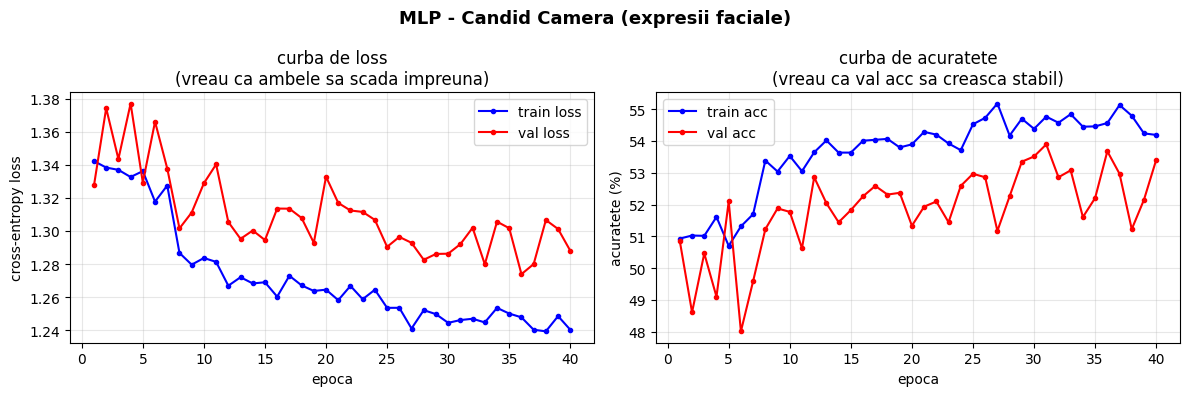

In [68]:
# plotez curbele de antrenare
plot_training_curves(
    history_candid,
    title     = 'MLP - Candid Camera (expresii faciale)',
    save_path = os.path.join(RESULTS_DIR, 'curves_mlp_candid.png')
);


metrici finale MLP - Candid Camera (pe val):
  accuracy : 0.5367 (53.67%)
  f1-macro : 0.3889   <- metrica principala Kaggle
  f1-micro : 0.5367
  f1 per clasa:
    0: Surprise        -> f1=0.4415
    1: Fear            -> f1=0.1754
    2: Disgust         -> f1=0.0945
    3: Happiness       -> f1=0.7273
    4: Sadness         -> f1=0.4022
    5: Anger           -> f1=0.3629
    6: Neutral         -> f1=0.5185
figura salvata: /kaggle/working/results/mlp/cm_mlp_candid.png


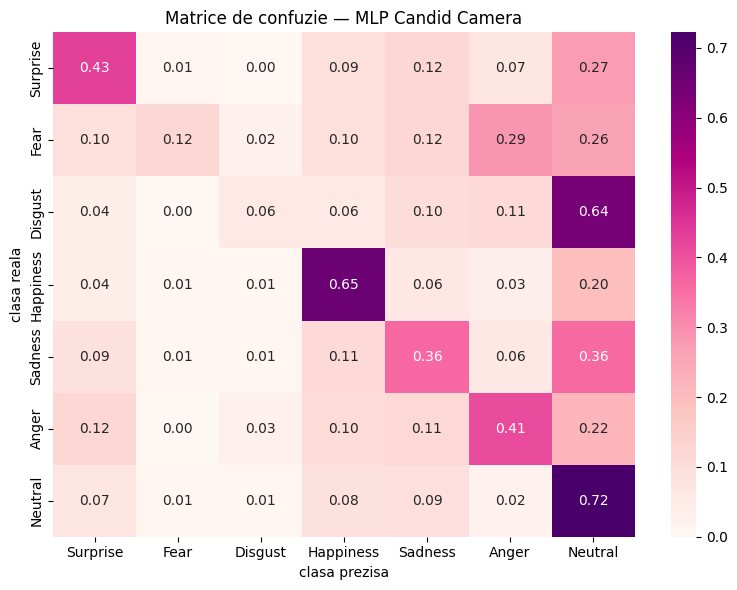

In [69]:
CANDID_CLASS_NAMES = ['Surprise', 'Fear', 'Disgust', 'Happiness',
                      'Sadness', 'Anger', 'Neutral']

# incarc CEL MAI BUN model (nu neaparat cel de la ultima epoca)
mlp_candid.load_state_dict(torch.load(best_path_candid))

y_true_candid, y_pred_candid = get_predictions(mlp_candid, dl_candid_val, device)

print('metrici finale MLP - Candid Camera (pe val):')
print_metrics(y_true_candid, y_pred_candid, CANDID_CLASS_NAMES)

# matricea de confuzie
plot_confusion_matrix(
    y_true_candid, y_pred_candid,
    class_names = CANDID_CLASS_NAMES,
    title       = 'Matrice de confuzie — MLP Candid Camera',
    save_path   = os.path.join(RESULTS_DIR, 'cm_mlp_candid.png')
);


## 7. antrenare MLP — Vai de Pielea Mea

In [70]:
# input_size = 3 canale * 128 * 128 pixeli = 49152 valori per imagine
# mai mult decat candid (27648) — implicit mai multi parametri la primul strat
PIELE_INPUT_SIZE = 3 * 128 * 128

mlp_piele = MLP(
    input_size  = PIELE_INPUT_SIZE,
    num_classes = NUM_CLASSES,
    use_dropout = True
).to(device)

n_params = sum(p.numel() for p in mlp_piele.parameters() if p.requires_grad)
print(f'total parametri antrenabili (piele): {n_params:,}')


total parametri antrenabili (piele): 50,994,183


In [71]:
history_piele, best_path_piele = train_mlp(
    dataset_name = 'piele',
    model        = mlp_piele,
    train_loader = dl_piele_train,
    val_loader   = dl_piele_val,
    num_epochs   = 40,
    lr           = 1e-3,
    weight_decay = 1e-4
)



=== antrenare MLP pe piele ===
epoci=40 | lr=0.001 | weight_decay=0.0001 | device=cuda

epoca   1/40 | train loss=1.0821 acc=0.637 | val   loss=0.9089 acc=0.672
epoca   5/40 | train loss=0.9098 acc=0.678 | val   loss=0.8659 acc=0.692
epoca  10/40 | train loss=0.8919 acc=0.686 | val   loss=0.8392 acc=0.706
epoca  15/40 | train loss=0.8886 acc=0.683 | val   loss=0.8227 acc=0.700
epoca  20/40 | train loss=0.8735 acc=0.689 | val   loss=0.8220 acc=0.714
epoca  25/40 | train loss=0.8508 acc=0.693 | val   loss=0.7987 acc=0.706
epoca  30/40 | train loss=0.8450 acc=0.695 | val   loss=0.7945 acc=0.720
epoca  35/40 | train loss=0.8310 acc=0.700 | val   loss=0.7889 acc=0.720
epoca  40/40 | train loss=0.8251 acc=0.701 | val   loss=0.7742 acc=0.727

cel mai bun model salvat: /kaggle/working/results/mlp/mlp_piele_best.pt
cel mai bun val_loss: 0.7673


figura salvata: /kaggle/working/results/mlp/curves_mlp_piele.png


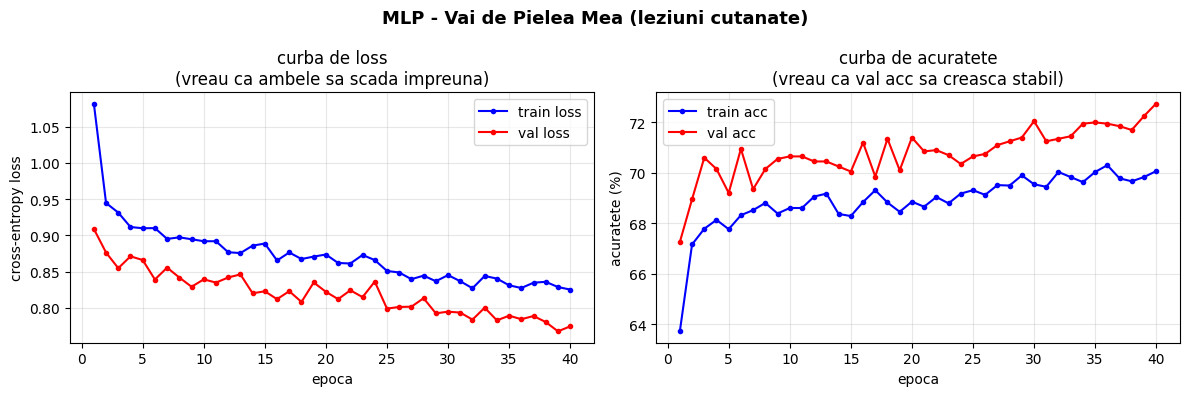

In [72]:
plot_training_curves(
    history_piele,
    title     = 'MLP - Vai de Pielea Mea (leziuni cutanate)',
    save_path = os.path.join(RESULTS_DIR, 'curves_mlp_piele.png')
);


metrici finale MLP - Vai de Pielea Mea (pe val):
  accuracy : 0.7224 (72.24%)
  f1-macro : 0.3535   <- metrica principala Kaggle
  f1-micro : 0.7224
  f1 per clasa:
    0: akiec           -> f1=0.2381
    1: bcc             -> f1=0.4492
    2: bkl             -> f1=0.4050
    3: df              -> f1=0.0000
    4: mel             -> f1=0.0813
    5: nv              -> f1=0.8567
    6: vasc            -> f1=0.4444
figura salvata: /kaggle/working/results/mlp/cm_mlp_piele.png


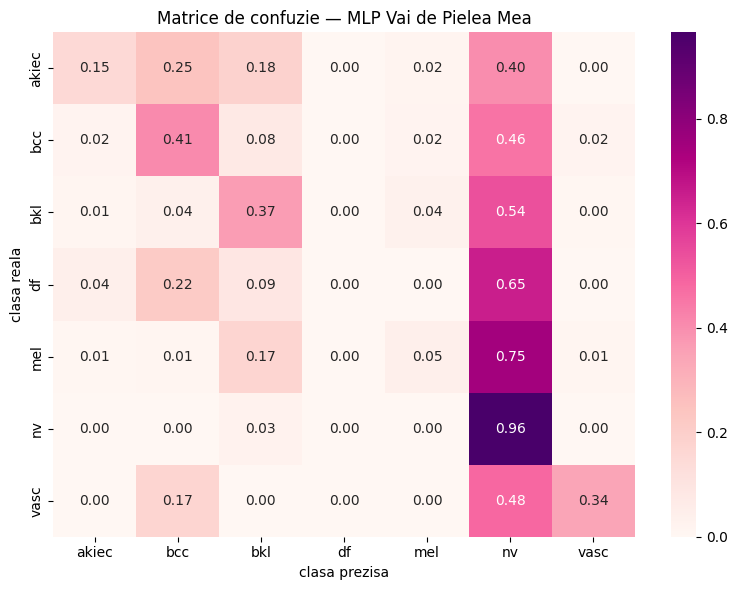

In [73]:
PIELE_CLASS_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

mlp_piele.load_state_dict(torch.load(best_path_piele))
y_true_piele, y_pred_piele = get_predictions(mlp_piele, dl_piele_val, device)

print('metrici finale MLP - Vai de Pielea Mea (pe val):')
print_metrics(y_true_piele, y_pred_piele, PIELE_CLASS_NAMES)

plot_confusion_matrix(
    y_true_piele, y_pred_piele,
    class_names = PIELE_CLASS_NAMES,
    title       = 'Matrice de confuzie — MLP Vai de Pielea Mea',
    save_path   = os.path.join(RESULTS_DIR, 'cm_mlp_piele.png')
);


## 8. ablatie: MLP cu dropout vs fara dropout (cerinta 3.5)


In [74]:
print('antrenare varianta FARA dropout (candid)')
mlp_candid_nodrop = MLP(
    input_size  = CANDID_INPUT_SIZE,
    num_classes = NUM_CLASSES,
    use_dropout = False
).to(device)

history_nodrop, best_path_nodrop = train_mlp(
    dataset_name = 'candid_nodropout',
    model        = mlp_candid_nodrop,
    train_loader = dl_candid_train,
    val_loader   = dl_candid_val,
    num_epochs   = 40,
    lr           = 1e-3,
    weight_decay = 1e-4
)


antrenare varianta FARA dropout (candid)

=== antrenare MLP pe candid_nodropout ===
epoci=40 | lr=0.001 | weight_decay=0.0001 | device=cuda

epoca   1/40 | train loss=1.5286 acc=0.435 | val   loss=1.4524 acc=0.462
epoca   5/40 | train loss=1.3183 acc=0.520 | val   loss=1.3679 acc=0.498
epoca  10/40 | train loss=1.2669 acc=0.538 | val   loss=1.3359 acc=0.502
epoca  15/40 | train loss=1.2301 acc=0.556 | val   loss=1.3318 acc=0.507
epoca  20/40 | train loss=1.1579 acc=0.580 | val   loss=1.3381 acc=0.516
epoca  25/40 | train loss=1.1311 acc=0.595 | val   loss=1.2763 acc=0.539
epoca  30/40 | train loss=1.1246 acc=0.592 | val   loss=1.3351 acc=0.520
epoca  35/40 | train loss=1.0758 acc=0.611 | val   loss=1.3404 acc=0.517
epoca  40/40 | train loss=1.0573 acc=0.619 | val   loss=1.3009 acc=0.533

cel mai bun model salvat: /kaggle/working/results/mlp/mlp_candid_nodropout_best.pt
cel mai bun val_loss: 1.2635


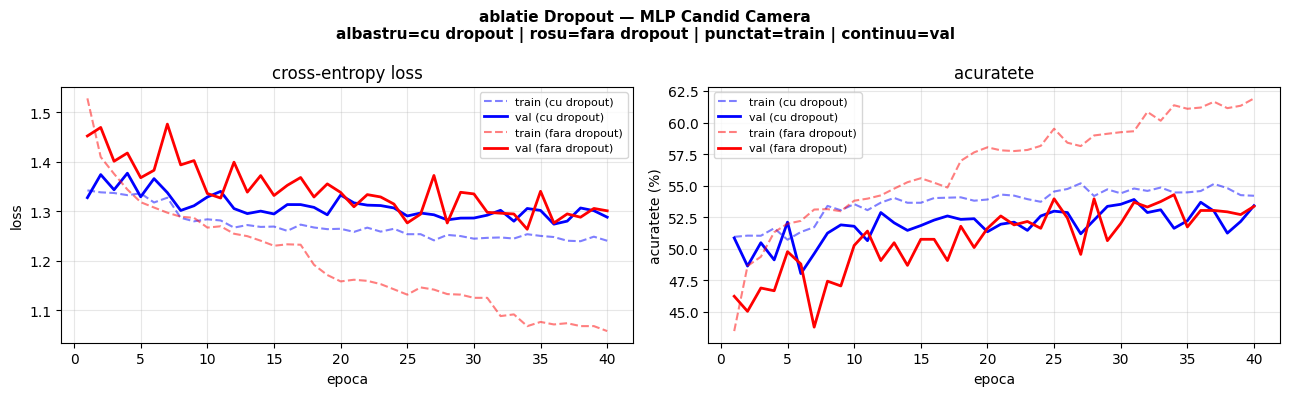

In [75]:
# grafic comparativ: cu dropout (albastru) vs fara dropout (rosu)
epochs_all = range(1, len(history_candid['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('ablatie Dropout — MLP Candid Camera\n'
             'albastru=cu dropout | rosu=fara dropout | '
             'punctat=train | continuu=val',
             fontsize=11, fontweight='bold')

axes[0].plot(epochs_all, history_candid['train_loss'],  'b--', alpha=0.5, label='train (cu dropout)')
axes[0].plot(epochs_all, history_candid['val_loss'],    'b-',  linewidth=2, label='val (cu dropout)')
axes[0].plot(epochs_all, history_nodrop['train_loss'],  'r--', alpha=0.5, label='train (fara dropout)')
axes[0].plot(epochs_all, history_nodrop['val_loss'],    'r-',  linewidth=2, label='val (fara dropout)')
axes[0].set_xlabel('epoca'); axes[0].set_ylabel('loss')
axes[0].set_title('cross-entropy loss')
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_all, [a*100 for a in history_candid['train_acc']], 'b--', alpha=0.5, label='train (cu dropout)')
axes[1].plot(epochs_all, [a*100 for a in history_candid['val_acc']],   'b-',  linewidth=2, label='val (cu dropout)')
axes[1].plot(epochs_all, [a*100 for a in history_nodrop['train_acc']], 'r--', alpha=0.5, label='train (fara dropout)')
axes[1].plot(epochs_all, [a*100 for a in history_nodrop['val_acc']],   'r-',  linewidth=2, label='val (fara dropout)')
axes[1].set_xlabel('epoca'); axes[1].set_ylabel('acuratete (%)')
axes[1].set_title('acuratete')
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, 'ablatie_dropout_candid.png'), dpi=150, bbox_inches='tight')
plt.show()


In [90]:
# tabel comparativ metrici finale cu f1-micro inclus
mlp_candid.load_state_dict(torch.load(best_path_candid))
mlp_candid_nodrop.load_state_dict(torch.load(best_path_nodrop))

y_true_c,  y_pred_cu   = get_predictions(mlp_candid,        dl_candid_val, device)
_,         y_pred_fara = get_predictions(mlp_candid_nodrop, dl_candid_val, device)

# Calcul metrici pentru varianta CU dropout
acc_cu    = accuracy_score(y_true_c, y_pred_cu)
f1m_cu    = f1_score(y_true_c, y_pred_cu,   average='macro', zero_division=0)
f1mic_cu  = f1_score(y_true_c, y_pred_cu,   average='micro', zero_division=0) # Linie noua

# Calcul metrici pentru varianta FARA dropout
acc_fara  = accuracy_score(y_true_c, y_pred_fara)
f1m_fara  = f1_score(y_true_c, y_pred_fara, average='macro', zero_division=0)
f1mic_fara = f1_score(y_true_c, y_pred_fara, average='micro', zero_division=0) # Linie noua

# Afisare tabel actualizat
print('tabel comparativ ablatie dropout — candid camera:')
print(f'{"varianta":25s} {"accuracy":>10s} {"f1-macro":>10s} {"f1-micro":>10s}') # Cap de tabel extins
print('-' * 59) # Linie de separare extinsa de la 47 la 59 caractere
print(f'{"MLP cu dropout":25s} {acc_cu:>10.4f} {f1m_cu:>10.4f} {f1mic_cu:>10.4f}')
print(f'{"MLP fara dropout":25s} {acc_fara:>10.4f} {f1m_fara:>10.4f} {f1mic_fara:>10.4f}')

tabel comparativ ablatie dropout — candid camera:
varianta                    accuracy   f1-macro   f1-micro
-----------------------------------------------------------
MLP cu dropout                0.5367     0.3889     0.5367
MLP fara dropout              0.5427     0.4401     0.5427


antrenare varianta FARA dropout (piele)

=== antrenare MLP pe piele_nodropout ===
epoci=40 | lr=0.001 | weight_decay=0.0001 | device=cuda

epoca   1/40 | train loss=1.0200 acc=0.643 | val   loss=0.8890 acc=0.685
epoca   5/40 | train loss=0.8890 acc=0.688 | val   loss=0.8461 acc=0.707
epoca  10/40 | train loss=0.8529 acc=0.695 | val   loss=0.8111 acc=0.714
epoca  15/40 | train loss=0.8320 acc=0.700 | val   loss=0.8122 acc=0.712
epoca  20/40 | train loss=0.8159 acc=0.701 | val   loss=0.7846 acc=0.719
epoca  25/40 | train loss=0.8200 acc=0.699 | val   loss=0.7957 acc=0.716
epoca  30/40 | train loss=0.7721 acc=0.716 | val   loss=0.7801 acc=0.727
epoca  35/40 | train loss=0.7552 acc=0.719 | val   loss=0.7761 acc=0.724
epoca  40/40 | train loss=0.7367 acc=0.729 | val   loss=0.7437 acc=0.727

cel mai bun model salvat: /kaggle/working/results/mlp/mlp_piele_nodropout_best.pt
cel mai bun val_loss: 0.7437


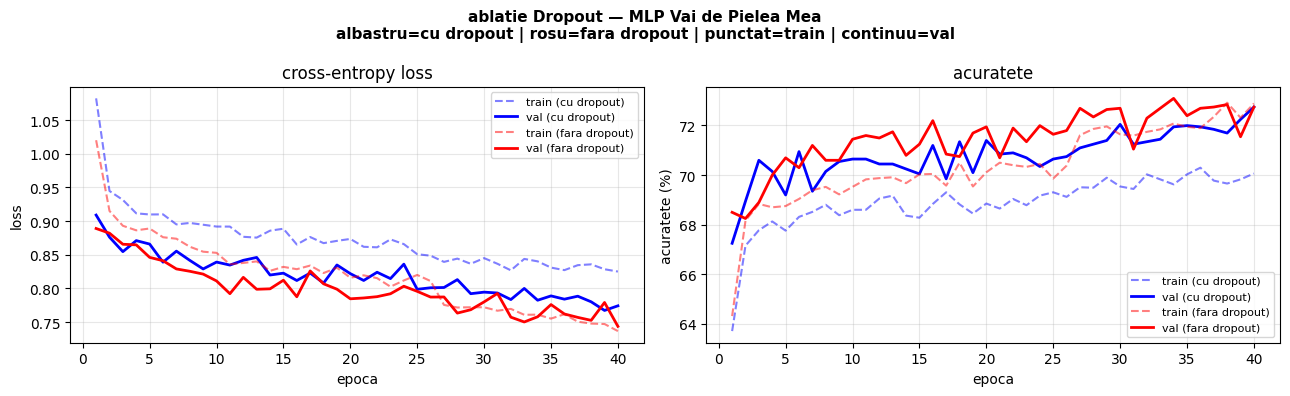

tabel comparativ ablatie dropout — vai de pielea mea:
varianta                    accuracy   f1-macro
-----------------------------------------------
MLP cu dropout                0.7224     0.3535
MLP fara dropout              0.7274     0.4116


In [86]:
print('antrenare varianta FARA dropout (piele)')
mlp_piele_nodrop = MLP(
    input_size  = PIELE_INPUT_SIZE,
    num_classes = 7,
    use_dropout = False
).to(device)

history_nodrop_piele, best_path_nodrop_piele = train_mlp(
    dataset_name = 'piele_nodropout',
    model        = mlp_piele_nodrop,
    train_loader = dl_piele_train,
    val_loader   = dl_piele_val,
    num_epochs   = 40,
    lr           = 1e-3,
    weight_decay = 1e-4
)

# grafic comparativ: cu dropout (albastru) vs fara dropout (rosu)
epochs_all_p = range(1, len(history_piele['train_loss']) + 1) # foloseste history-ul tau de la mlp piele normal

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('ablatie Dropout — MLP Vai de Pielea Mea\n'
             'albastru=cu dropout | rosu=fara dropout | '
             'punctat=train | continuu=val',
             fontsize=11, fontweight='bold')

axes[0].plot(epochs_all_p, history_piele['train_loss'],        'b--', alpha=0.5, label='train (cu dropout)')
axes[0].plot(epochs_all_p, history_piele['val_loss'],          'b-',  linewidth=2, label='val (cu dropout)')
axes[0].plot(epochs_all_p, history_nodrop_piele['train_loss'], 'r--', alpha=0.5, label='train (fara dropout)')
axes[0].plot(epochs_all_p, history_nodrop_piele['val_loss'],   'r-',  linewidth=2, label='val (fara dropout)')
axes[0].set_xlabel('epoca'); axes[0].set_ylabel('loss')
axes[0].set_title('cross-entropy loss')
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_all_p, [a*100 for a in history_piele['train_acc']],        'b--', alpha=0.5, label='train (cu dropout)')
axes[1].plot(epochs_all_p, [a*100 for a in history_piele['val_acc']],          'b-',  linewidth=2, label='val (cu dropout)')
axes[1].plot(epochs_all_p, [a*100 for a in history_nodrop_piele['train_acc']], 'r--', alpha=0.5, label='train (fara dropout)')
axes[1].plot(epochs_all_p, [a*100 for a in history_nodrop_piele['val_acc']],   'r-',  linewidth=2, label='val (fara dropout)')
axes[1].set_xlabel('epoca'); axes[1].set_ylabel('acuratete (%)')
axes[1].set_title('acuratete')
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, 'ablatie_dropout_piele.png'), dpi=150, bbox_inches='tight')
plt.show() 

# tabel comparativ metrici finale
mlp_piele.load_state_dict(torch.load(best_path_piele)) # incarca modelul MLP piele cu dropout
mlp_piele_nodrop.load_state_dict(torch.load(best_path_nodrop_piele))

y_true_p,  y_pred_cu_p   = get_predictions(mlp_piele,        dl_piele_val, device)
_,         y_pred_fara_p = get_predictions(mlp_piele_nodrop, dl_piele_val, device)

acc_cu_p   = accuracy_score(y_true_p, y_pred_cu_p)
f1m_cu_p   = f1_score(y_true_p, y_pred_cu_p,   average='macro', zero_division=0)
acc_fara_p = accuracy_score(y_true_p, y_pred_fara_p)
f1m_fara_p = f1_score(y_true_p, y_pred_fara_p, average='macro', zero_division=0)

print('tabel comparativ ablatie dropout — vai de pielea mea:')
print(f'{"varianta":25s} {"accuracy":>10s} {"f1-macro":>10s}')
print('-' * 47)
print(f'{"MLP cu dropout":25s} {acc_cu_p:>10.4f} {f1m_cu_p:>10.4f}')
print(f'{"MLP fara dropout":25s} {acc_fara_p:>10.4f} {f1m_fara_p:>10.4f}')

In [88]:
# tabel comparativ metrici finale (inclusiv f1-micro)
mlp_piele.load_state_dict(torch.load(best_path_piele)) 
mlp_piele_nodrop.load_state_dict(torch.load(best_path_nodrop_piele))

y_true_p,  y_pred_cu_p   = get_predictions(mlp_piele,        dl_piele_val, device)
_,         y_pred_fara_p = get_predictions(mlp_piele_nodrop, dl_piele_val, device)

acc_cu_p     = accuracy_score(y_true_p, y_pred_cu_p)
f1m_cu_p     = f1_score(y_true_p, y_pred_cu_p,   average='macro', zero_division=0)
f1mic_cu_p   = f1_score(y_true_p, y_pred_cu_p,   average='micro', zero_division=0)

acc_fara_p   = accuracy_score(y_true_p, y_pred_fara_p)
f1m_fara_p   = f1_score(y_true_p, y_pred_fara_p, average='macro', zero_division=0)
f1mic_fara_p = f1_score(y_true_p, y_pred_fara_p, average='micro', zero_division=0)

print('tabel comparativ ablatie dropout — vai de pielea mea:')
print(f'{"varianta":25s} {"accuracy":>10s} {"f1-macro":>10s} {"f1-micro":>10s}')
print('-' * 58)
print(f'{"MLP cu dropout":25s} {acc_cu_p:>10.4f} {f1m_cu_p:>10.4f} {f1mic_cu_p:>10.4f}')
print(f'{"MLP fara dropout":25s} {acc_fara_p:>10.4f} {f1m_fara_p:>10.4f} {f1mic_fara_p:>10.4f}')

tabel comparativ ablatie dropout — vai de pielea mea:
varianta                    accuracy   f1-macro   f1-micro
----------------------------------------------------------
MLP cu dropout                0.7224     0.3535     0.7224
MLP fara dropout              0.7274     0.4116     0.7274


In [ ]:
# import shutil
# RESULTS_DRIVE_MLP = os.path.join(DRIVE_BASE, 'results/mlp')
# os.makedirs(RESULTS_DRIVE_MLP, exist_ok=True)
# for fname in os.listdir(RESULTS_DIR):
#     shutil.copy(os.path.join(RESULTS_DIR, fname),
#                 os.path.join(RESULTS_DRIVE_MLP, fname))
#     print(f'copiat: {fname}')
# print(f'rezultate mlp salvate pe drive: {RESULTS_DRIVE_MLP}')


---
---
# Cerinta 3.3 — Arhitectura CNN

In [32]:
class CNN(nn.Module):

    def __init__(self, num_classes, first_kernel_size=3, use_batchnorm=True):
            # first_kernel_size : kernelul primului strat convolutiv
            # 3 pentru candid camera (trasaturi fine: ochi, gura)
            # 5 pentru piele (trasaturi mai mari: asimetrie, contur)
        super().__init__()

        p1 = first_kernel_size // 2

        def conv_block(in_ch, out_ch, kernel=3, pad=1):
            layers = [
                nn.Conv2d(in_ch, out_ch, kernel,
                          padding=pad,
                          bias=not use_batchnorm)
            ]
            if use_batchnorm:
                layers.append(nn.BatchNorm2d(out_ch))
            layers.append(nn.ReLU(inplace=True))
            return nn.Sequential(*layers)

        self.features = nn.Sequential(
            # BLOC CONV 1
            # intrare: (batch, 3, 96, 96) pentru candid sau (batch, 3, 128, 128) pentru piele
            # iesire dupa conv: (batch, 32, 96, 96) — 32 harti de trasaturi
            # iesire dupa maxpool: (batch, 32, 48, 48)
            # ce invata acest strat: trasaturi simple — muchii, culori de baza, texturi
            conv_block(3, 32, kernel=first_kernel_size, pad=p1),
            nn.MaxPool2d(2),

            # BLOC CONV 2
            # intrare: (batch, 32, 48, 48)
            # iesire dupa conv: (batch, 64, 48, 48) — 64 harti de trasaturi
            # iesire dupa maxpool: (batch, 64, 24, 24)
            # ce invata: combinatii de muchii => forme simple (cercuri, unghiuri)
            conv_block(32, 64, kernel=3, pad=1),
            nn.MaxPool2d(2),

            # BLOC CONV 3
            # intrare: (batch, 64, 24, 24)
            # iesire dupa conv: (batch, 128, 24, 24)
            # iesire dupa maxpool: (batch, 128, 12, 12)
            # ce invata: forme mai complexe (ochi, nas, contururi de leziuni)
            conv_block(64, 128, kernel=3, pad=1),
            nn.MaxPool2d(2),

            # BLOC CONV 4
            # intrare: (batch, 128, 12, 12)
            # iesire dupa conv: (batch, 256, 12, 12)
            # iesire dupa adaptive avg pool: (batch, 256, 1, 1)
            # ce invata: trasaturi de nivel inalt (expresii faciale, tipuri de leziuni)
            conv_block(128, 256, kernel=3, pad=1),
            nn.AdaptiveAvgPool2d(1),
        )

        self.classifier = nn.Sequential(
            # STRAT LINEAR 1: 256 -> 128
            nn.Linear(256, 128),
            nn.BatchNorm1d(128) if use_batchnorm else nn.Identity(),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),

            # STRAT LINEAR 2 (IESIRE): 128 -> 7
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)


## 2. pipeline-uri de augmentare pentru ablatii (cerinta 3.5)


In [34]:
# candid camera: 4 configuratii de augmentare

# fara augmentari — baseline pur
candid_aug_none = A.Compose([
    A.Resize(96, 96),
    A.Normalize(mean=[0.5752, 0.4497, 0.4013], std=[0.2653, 0.2423, 0.2407]),
    ToTensorV2(),
])

# augmentari geometrice — schimb forma/pozitia, nu culoarea
candid_aug_geo = A.Compose([
    A.Resize(108, 108),
    A.RandomCrop(96, 96),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=10, p=0.5),
    A.Normalize(mean=[0.5752, 0.4497, 0.4013], std=[0.2653, 0.2423, 0.2407]),
    ToTensorV2(),
])

# augmentari de culoare — schimb luminozitatea/nuanta, nu forma
candid_aug_color = A.Compose([
    A.Resize(96, 96),
    A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.7),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=15, p=0.5),
    A.GaussianBlur(blur_limit=(3, 3), p=0.3),
    A.Normalize(mean=[0.5752, 0.4497, 0.4013], std=[0.2653, 0.2423, 0.2407]),
    ToTensorV2(),
])

# 4. toate augmentarile — identic cu candid_train_aug din cerinta 3.1
candid_aug_all = candid_train_aug

# piele: 4 configuratii de augmentare

piele_aug_none = A.Compose([
    A.Resize(128, 128),
    A.Normalize(mean=[0.7646, 0.5464, 0.5712], std=[0.1410, 0.1532, 0.1706]),
    ToTensorV2(),
])

piele_aug_geo = A.Compose([
    A.Resize(128, 128),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Rotate(limit=30, p=0.5),
    A.Normalize(mean=[0.7646, 0.5464, 0.5712], std=[0.1410, 0.1532, 0.1706]),
    ToTensorV2(),
])

# limite mici la culoare pentru piele — culorile au semnificatie diagnostica!
piele_aug_color = A.Compose([
    A.Resize(128, 128),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
    A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=15, val_shift_limit=10, p=0.4),
    A.GaussianBlur(blur_limit=(3, 3), p=0.2),
    A.Normalize(mean=[0.7646, 0.5464, 0.5712], std=[0.1410, 0.1532, 0.1706]),
    ToTensorV2(),
])

piele_aug_all = piele_train_aug

## 3. functia de antrenare CNN

In [35]:
def train_cnn(dataset_name, model, train_loader, val_loader,
              num_epochs=40, lr=1e-3, weight_decay=1e-4, save_dir=None):
    # identica structural cu train_mlp, deci
    # reutilizez train_one_epoch, evaluate, get_predictions definite anterior.
    if save_dir is None:
        save_dir = '/kaggle/working/results/cnn'
    os.makedirs(save_dir, exist_ok=True)

    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5
    )
    criterion = nn.CrossEntropyLoss()
    writer    = SummaryWriter(log_dir=f'/kaggle/working/runs/cnn_{dataset_name}')

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_loss   = float('inf')
    best_model_path = os.path.join(save_dir, f'cnn_{dataset_name}_best.pt')

    print(f'\n=== antrenare CNN pe {dataset_name} ===')
    print(f'epoci={num_epochs} | lr={lr} | weight_decay={weight_decay} | device={device}\n')

    for epoch in range(num_epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc = evaluate(model, val_loader, criterion, device)
        scheduler.step(va_loss)

        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)

        writer.add_scalar(f'{dataset_name}/Loss/train', tr_loss, epoch)
        writer.add_scalar(f'{dataset_name}/Loss/val',   va_loss, epoch)
        writer.add_scalar(f'{dataset_name}/Acc/train',  tr_acc,  epoch)
        writer.add_scalar(f'{dataset_name}/Acc/val',    va_acc,  epoch)
        writer.add_scalar(f'{dataset_name}/LR', optimizer.param_groups[0]['lr'], epoch)

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            torch.save(model.state_dict(), best_model_path)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'epoca {epoch+1:3d}/{num_epochs} | '
                  f'train loss={tr_loss:.4f} acc={tr_acc:.3f} | '
                  f'val   loss={va_loss:.4f} acc={va_acc:.3f}')

    writer.close()
    print(f'\ncel mai bun model salvat: {best_model_path}')
    return history, best_model_path


CNN_RESULTS_DIR = '/kaggle/working/results/cnn'
os.makedirs(CNN_RESULTS_DIR, exist_ok=True)


## 4. antrenare CNN — Candid Camera

In [36]:
# creez CNN-ul pentru candid
# first_kernel_size=3
cnn_candid = CNN(num_classes=7, first_kernel_size=3, use_batchnorm=True).to(device)
n = sum(p.numel() for p in cnn_candid.parameters() if p.requires_grad)
print(f'parametri CNN candid: {n:,}')

parametri CNN candid: 422,951


In [35]:
# creez un dataloader nou cu augmentarile complete pentru CNN
dl_candid_train_cnn = DataLoader(
    CandidCameraDataset(
        csv_path  = os.path.join(CANDID_ROOT, 'splits/train.csv'),
        root      = CANDID_ROOT,
        transform = candid_aug_all   # toate augmentarile
    ),
    batch_size=64, shuffle=True, num_workers=2, drop_last=True
)

history_cnn_candid, best_cnn_candid = train_cnn(
    dataset_name = 'candid',
    model        = cnn_candid,
    train_loader = dl_candid_train_cnn,
    val_loader   = dl_candid_val,
    num_epochs   = 40, lr=1e-3, weight_decay=1e-4,
    save_dir     = CNN_RESULTS_DIR
)



=== antrenare CNN pe candid ===
epoci=40 | lr=0.001 | weight_decay=0.0001 | device=cuda

epoca   1/40 | train loss=1.6849 acc=0.368 | val   loss=1.6181 acc=0.382
epoca   5/40 | train loss=1.5871 acc=0.401 | val   loss=1.5819 acc=0.404
epoca  10/40 | train loss=1.4465 acc=0.463 | val   loss=1.4459 acc=0.482
epoca  15/40 | train loss=1.0521 acc=0.620 | val   loss=1.1428 acc=0.582
epoca  20/40 | train loss=0.8788 acc=0.689 | val   loss=0.9916 acc=0.635
epoca  25/40 | train loss=0.7852 acc=0.722 | val   loss=0.8489 acc=0.688
epoca  30/40 | train loss=0.7086 acc=0.749 | val   loss=0.8062 acc=0.718
epoca  35/40 | train loss=0.6436 acc=0.777 | val   loss=1.1435 acc=0.595
epoca  40/40 | train loss=0.5537 acc=0.806 | val   loss=0.7107 acc=0.743

cel mai bun model salvat: /kaggle/working/results/cnn/cnn_candid_best.pt


figura salvata: /kaggle/working/results/cnn/curves_cnn_candid.png


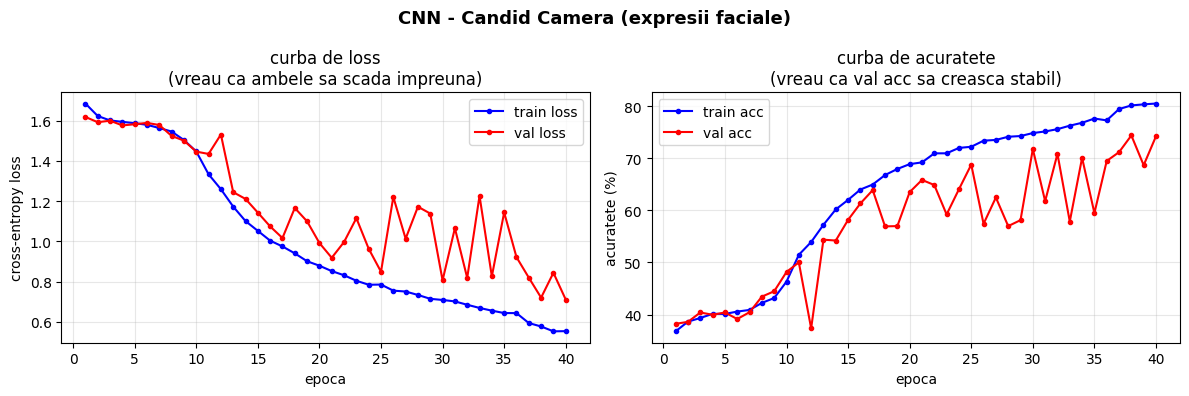

metrici finale CNN - Candid Camera:
  accuracy : 0.7425 (74.25%)
  f1-macro : 0.6337   <- metrica principala Kaggle
  f1-micro : 0.7425
  f1 per clasa:
    0: Surprise        -> f1=0.7709
    1: Fear            -> f1=0.3692
    2: Disgust         -> f1=0.4608
    3: Happiness       -> f1=0.8661
    4: Sadness         -> f1=0.6553
    5: Anger           -> f1=0.6289
    6: Neutral         -> f1=0.6846
figura salvata: /kaggle/working/results/cnn/cm_cnn_candid.png


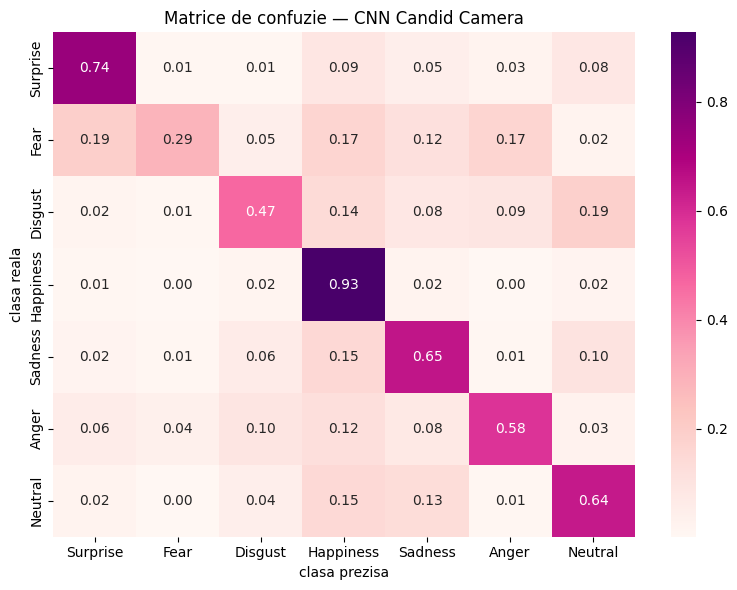

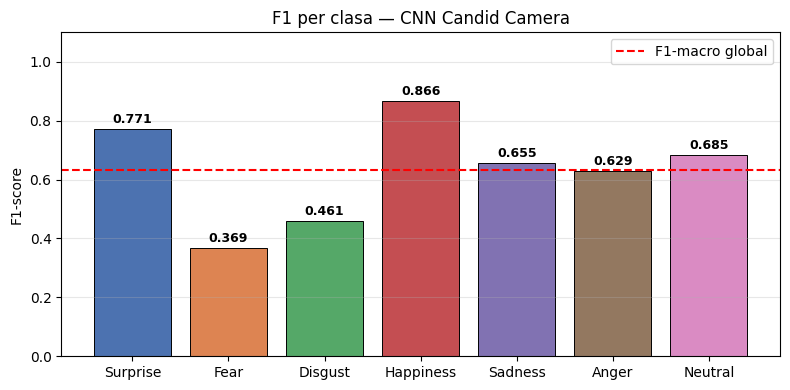

In [36]:
plot_training_curves(
    history_cnn_candid,
    title     = 'CNN - Candid Camera (expresii faciale)',
    save_path = os.path.join(CNN_RESULTS_DIR, 'curves_cnn_candid.png')
);

CANDID_CLASS_NAMES = ['Surprise', 'Fear', 'Disgust', 'Happiness',
                      'Sadness', 'Anger', 'Neutral']

cnn_candid.load_state_dict(torch.load(best_cnn_candid))
y_true_cc, y_pred_cc = get_predictions(cnn_candid, dl_candid_val, device)

print('metrici finale CNN - Candid Camera:')
print_metrics(y_true_cc, y_pred_cc, CANDID_CLASS_NAMES)

plot_confusion_matrix(
    y_true_cc, y_pred_cc, class_names=CANDID_CLASS_NAMES,
    title='Matrice de confuzie — CNN Candid Camera',
    save_path=os.path.join(CNN_RESULTS_DIR, 'cm_cnn_candid.png')
);

# grafic F1-macro per clasa — arata care clase sunt mai greu de clasificat
f1_per_cls = f1_score(y_true_cc, y_pred_cc, average=None, zero_division=0)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(CANDID_CLASS_NAMES, f1_per_cls,
              color=['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2','#937860','#DA8BC3'],
              edgecolor='black', linewidth=0.7)
for bar, val in zip(bars, f1_per_cls):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_ylim(0, 1.1)
ax.axhline(y=f1_score(y_true_cc, y_pred_cc, average='macro', zero_division=0),
           color='red', linestyle='--', linewidth=1.5, label='F1-macro global')
ax.set_ylabel('F1-score'); ax.set_title('F1 per clasa — CNN Candid Camera')
ax.legend(); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(CNN_RESULTS_DIR, 'f1_per_clasa_cnn_candid.png'), dpi=150, bbox_inches='tight')
plt.show()


## 5. antrenare CNN — Vai de Pielea Mea

In [37]:
# first_kernel_size=5: trasaturi de scara mai mare (asimetrie, contur neregulat)
cnn_piele = CNN(num_classes=7, first_kernel_size=5, use_batchnorm=True).to(device)
n = sum(p.numel() for p in cnn_piele.parameters() if p.requires_grad)
print(f'parametri CNN piele: {n:,}')


parametri CNN piele: 424,487


In [38]:
dl_piele_train_cnn = DataLoader(
    PieleDataset(
        csv_path  = os.path.join(PIELE_ROOT, 'train.csv'),
        img_dir   = os.path.join(PIELE_ROOT, 'train'),
        transform = piele_aug_all
    ),
    batch_size=64, shuffle=True, num_workers=2, drop_last=True
)

history_cnn_piele, best_cnn_piele = train_cnn(
    dataset_name = 'piele',
    model        = cnn_piele,
    train_loader = dl_piele_train_cnn,
    val_loader   = dl_piele_val,
    num_epochs   = 40, lr=1e-3, weight_decay=1e-4,
    save_dir     = CNN_RESULTS_DIR
)



=== antrenare CNN pe piele ===
epoci=40 | lr=0.001 | weight_decay=0.0001 | device=cuda

epoca   1/40 | train loss=1.1420 acc=0.622 | val   loss=0.9288 acc=0.672
epoca   5/40 | train loss=0.8984 acc=0.677 | val   loss=0.8496 acc=0.703
epoca  10/40 | train loss=0.8395 acc=0.695 | val   loss=0.8014 acc=0.710
epoca  15/40 | train loss=0.7868 acc=0.707 | val   loss=0.7427 acc=0.726
epoca  20/40 | train loss=0.7653 acc=0.715 | val   loss=0.7373 acc=0.738
epoca  25/40 | train loss=0.7511 acc=0.720 | val   loss=0.6982 acc=0.744
epoca  30/40 | train loss=0.7375 acc=0.731 | val   loss=0.7179 acc=0.732
epoca  35/40 | train loss=0.7259 acc=0.726 | val   loss=0.7059 acc=0.732
epoca  40/40 | train loss=0.7166 acc=0.731 | val   loss=0.6827 acc=0.751

cel mai bun model salvat: /kaggle/working/results/cnn/cnn_piele_best.pt


figura salvata: /kaggle/working/results/cnn/curves_cnn_piele.png


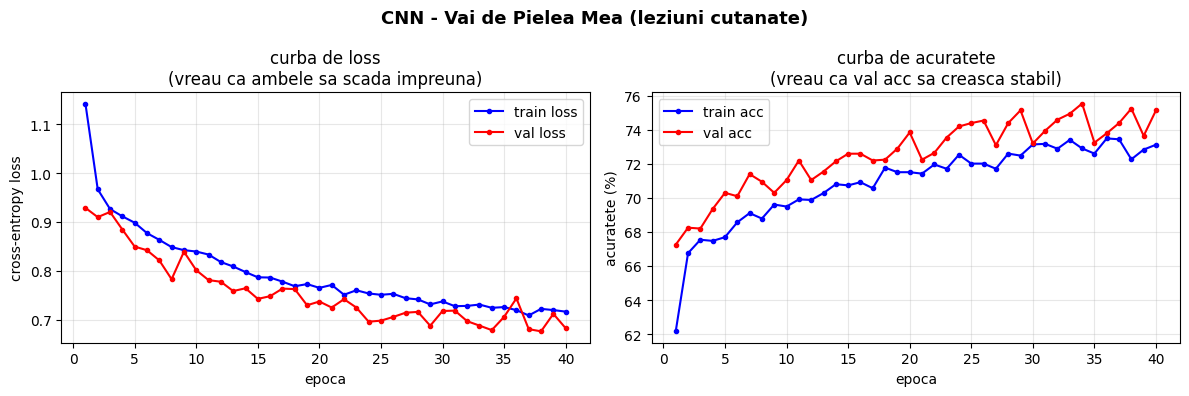

metrici finale CNN - Vai de Pielea Mea:
  accuracy : 0.7524 (75.24%)
  f1-macro : 0.4479   <- metrica principala Kaggle
  f1-micro : 0.7524
  f1 per clasa:
    0: akiec           -> f1=0.3208
    1: bcc             -> f1=0.5740
    2: bkl             -> f1=0.4856
    3: df              -> f1=0.0000
    4: mel             -> f1=0.2357
    5: nv              -> f1=0.8778
    6: vasc            -> f1=0.6415
figura salvata: /kaggle/working/results/cnn/cm_cnn_piele.png


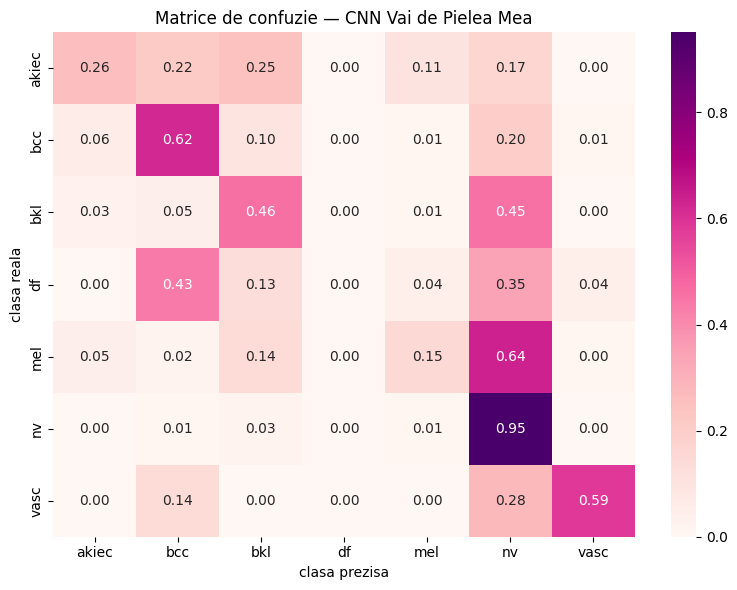

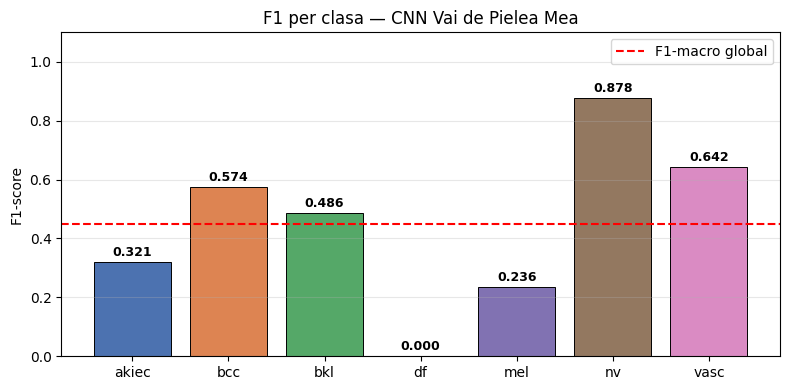

In [39]:
plot_training_curves(
    history_cnn_piele,
    title     = 'CNN - Vai de Pielea Mea (leziuni cutanate)',
    save_path = os.path.join(CNN_RESULTS_DIR, 'curves_cnn_piele.png')
);

PIELE_CLASS_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

cnn_piele.load_state_dict(torch.load(best_cnn_piele))
y_true_cp, y_pred_cp = get_predictions(cnn_piele, dl_piele_val, device)

print('metrici finale CNN - Vai de Pielea Mea:')
print_metrics(y_true_cp, y_pred_cp, PIELE_CLASS_NAMES)

plot_confusion_matrix(
    y_true_cp, y_pred_cp, class_names=PIELE_CLASS_NAMES,
    title='Matrice de confuzie — CNN Vai de Pielea Mea',
    save_path=os.path.join(CNN_RESULTS_DIR, 'cm_cnn_piele.png')
);

# grafic F1-macro per clasa — crucial pentru piele (dezechilibru extrem)
f1_per_cls_p = f1_score(y_true_cp, y_pred_cp, average=None, zero_division=0)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(PIELE_CLASS_NAMES, f1_per_cls_p,
              color=['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2','#937860','#DA8BC3'],
              edgecolor='black', linewidth=0.7)
for bar, val in zip(bars, f1_per_cls_p):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_ylim(0, 1.1)
ax.axhline(y=f1_score(y_true_cp, y_pred_cp, average='macro', zero_division=0),
           color='red', linestyle='--', linewidth=1.5, label='F1-macro global')
ax.set_ylabel('F1-score'); ax.set_title('F1 per clasa — CNN Vai de Pielea Mea')
ax.legend(); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(CNN_RESULTS_DIR, 'f1_per_clasa_cnn_piele.png'), dpi=150, bbox_inches='tight')
plt.show()


## 6. ablatie: CNN cu BatchNorm vs fara BatchNorm (cerinta 3.5)

- fara BN: convergenta mai lenta
- cu BN: convergenta mai rapida, acuratete finala mai mare


In [84]:
print('antrenare CNN FARA BatchNorm (candid)')
cnn_candid_nobn = CNN(
    num_classes       = 7,
    first_kernel_size = 3,
    use_batchnorm     = False
).to(device)

history_nobn, best_nobn = train_cnn(
    dataset_name = 'candid_nobn',
    model        = cnn_candid_nobn,
    train_loader = dl_candid_train_cnn,
    val_loader   = dl_candid_val,
    num_epochs   = 40, lr=1e-3, weight_decay=1e-4,
    save_dir     = CNN_RESULTS_DIR
)


antrenare CNN FARA BatchNorm (candid)

=== antrenare CNN pe candid_nobn ===
epoci=40 | lr=0.001 | weight_decay=0.0001 | device=cuda

epoca   1/40 | train loss=1.6721 acc=0.384 | val   loss=1.6198 acc=0.389
epoca   5/40 | train loss=1.6021 acc=0.396 | val   loss=1.5984 acc=0.393
epoca  10/40 | train loss=1.5725 acc=0.399 | val   loss=1.5606 acc=0.399
epoca  15/40 | train loss=1.5285 acc=0.411 | val   loss=1.5175 acc=0.418
epoca  20/40 | train loss=1.3884 acc=0.482 | val   loss=1.3896 acc=0.468
epoca  25/40 | train loss=1.2165 acc=0.565 | val   loss=1.2055 acc=0.567
epoca  30/40 | train loss=1.0769 acc=0.618 | val   loss=1.1634 acc=0.572
epoca  35/40 | train loss=0.9927 acc=0.646 | val   loss=1.0491 acc=0.612
epoca  40/40 | train loss=0.9508 acc=0.662 | val   loss=0.9773 acc=0.637

cel mai bun model salvat: /kaggle/working/results/cnn/cnn_candid_nobn_best.pt


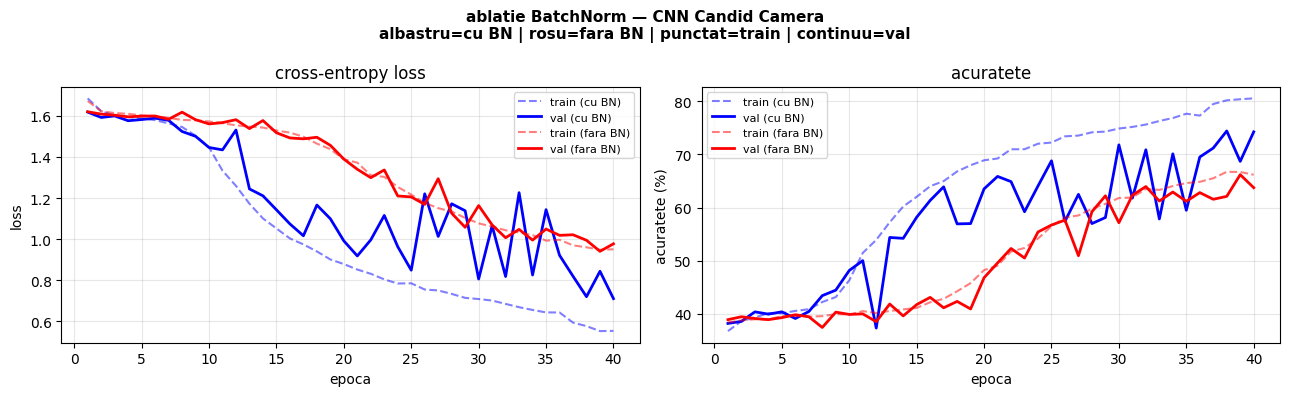

tabel ablatie BatchNorm — candid camera:
varianta                 accuracy   f1-macro
--------------------------------------------
CNN cu BatchNorm           0.7425     0.6337
CNN fara BatchNorm         0.6619     0.4552


In [85]:
# grafic comparativ BatchNorm vs fara BatchNorm
epochs_cnn = range(1, len(history_cnn_candid['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('ablatie BatchNorm — CNN Candid Camera\n'
             'albastru=cu BN | rosu=fara BN | punctat=train | continuu=val',
             fontsize=11, fontweight='bold')

axes[0].plot(epochs_cnn, history_cnn_candid['train_loss'], 'b--', alpha=0.5, label='train (cu BN)')
axes[0].plot(epochs_cnn, history_cnn_candid['val_loss'],   'b-',  linewidth=2, label='val (cu BN)')
axes[0].plot(epochs_cnn, history_nobn['train_loss'],       'r--', alpha=0.5, label='train (fara BN)')
axes[0].plot(epochs_cnn, history_nobn['val_loss'],         'r-',  linewidth=2, label='val (fara BN)')
axes[0].set_xlabel('epoca'); axes[0].set_ylabel('loss')
axes[0].set_title('cross-entropy loss'); axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_cnn, [a*100 for a in history_cnn_candid['train_acc']], 'b--', alpha=0.5, label='train (cu BN)')
axes[1].plot(epochs_cnn, [a*100 for a in history_cnn_candid['val_acc']],   'b-',  linewidth=2, label='val (cu BN)')
axes[1].plot(epochs_cnn, [a*100 for a in history_nobn['train_acc']],       'r--', alpha=0.5, label='train (fara BN)')
axes[1].plot(epochs_cnn, [a*100 for a in history_nobn['val_acc']],         'r-',  linewidth=2, label='val (fara BN)')
axes[1].set_xlabel('epoca'); axes[1].set_ylabel('acuratete (%)')
axes[1].set_title('acuratete'); axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(CNN_RESULTS_DIR, 'ablatie_batchnorm_candid.png'), dpi=150, bbox_inches='tight')
plt.show()


In [91]:
# tabel comparativ ablatie BatchNorm cu f1-micro inclus
cnn_candid.load_state_dict(torch.load(best_cnn_candid))
cnn_candid_nobn.load_state_dict(torch.load(best_nobn))

y_true_ref, y_pred_bn  = get_predictions(cnn_candid,     dl_candid_val, device)
_,          y_pred_nobn= get_predictions(cnn_candid_nobn, dl_candid_val, device)

print('tabel ablatie BatchNorm — candid camera:')
print(f'{"varianta":22s} {"accuracy":>10s} {"f1-macro":>10s} {"f1-micro":>10s}') # Cap de tabel extins
print('-' * 56) 

for label, yp in [('CNN cu BatchNorm', y_pred_bn), ('CNN fara BatchNorm', y_pred_nobn)]:
    acc = accuracy_score(y_true_ref, yp)
    f1m = f1_score(y_true_ref, yp, average='macro', zero_division=0)
    f1mic = f1_score(y_true_ref, yp, average='micro', zero_division=0) # Linie noua
    
    print(f'{label:22s} {acc:>10.4f} {f1m:>10.4f} {f1mic:>10.4f}')

tabel ablatie BatchNorm — candid camera:
varianta                 accuracy   f1-macro   f1-micro
--------------------------------------------------------
CNN cu BatchNorm           0.7425     0.6337     0.7425
CNN fara BatchNorm         0.6619     0.4552     0.6619


antrenare CNN FARA BatchNorm (piele)

=== antrenare CNN pe piele_nobn ===
epoci=40 | lr=0.001 | weight_decay=0.0001 | device=cuda

epoca   1/40 | train loss=1.1061 acc=0.657 | val   loss=1.0149 acc=0.669
epoca   5/40 | train loss=0.9711 acc=0.671 | val   loss=0.9098 acc=0.669
epoca  10/40 | train loss=0.9024 acc=0.676 | val   loss=0.8415 acc=0.693
epoca  15/40 | train loss=0.8459 acc=0.690 | val   loss=0.8313 acc=0.706
epoca  20/40 | train loss=0.8247 acc=0.701 | val   loss=0.8083 acc=0.722
epoca  25/40 | train loss=0.8111 acc=0.704 | val   loss=0.7610 acc=0.711
epoca  30/40 | train loss=0.8024 acc=0.707 | val   loss=0.7557 acc=0.722
epoca  35/40 | train loss=0.7720 acc=0.718 | val   loss=0.7391 acc=0.737
epoca  40/40 | train loss=0.7649 acc=0.716 | val   loss=0.7162 acc=0.727

cel mai bun model salvat: /kaggle/working/results/cnn/cnn_piele_nobn_best.pt


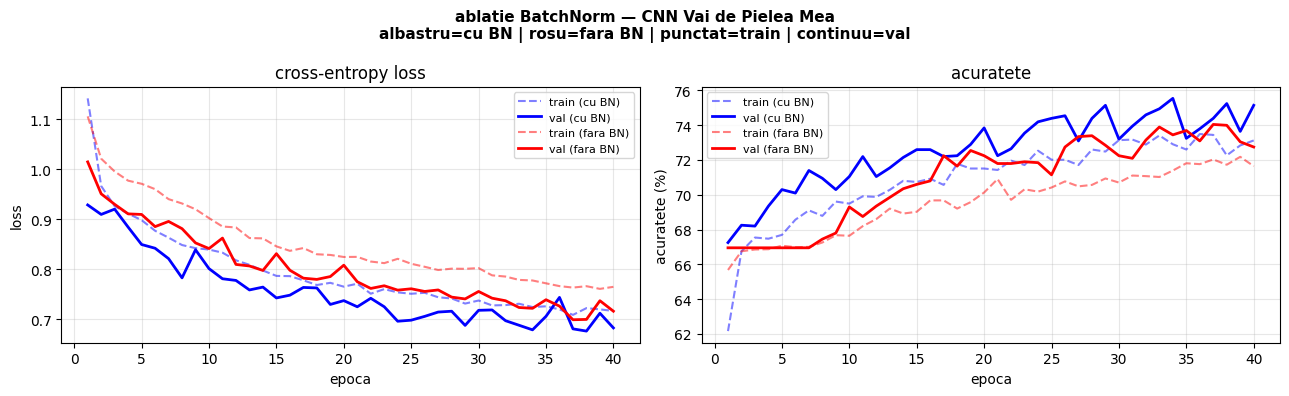

tabel ablatie BatchNorm — vai de pielea mea:
varianta                 accuracy   f1-macro
--------------------------------------------
CNN cu BatchNorm           0.7524     0.4479     0.7524
CNN fara BatchNorm         0.7404     0.4167     0.7404


In [87]:
print('antrenare CNN FARA BatchNorm (piele)')
cnn_piele_nobn = CNN(
    num_classes       = 7,
    first_kernel_size = 3,
    use_batchnorm     = False
).to(device)

history_nobn_piele, best_nobn_piele = train_cnn(
    dataset_name = 'piele_nobn',
    model        = cnn_piele_nobn,
    train_loader = dl_piele_train_cnn,
    val_loader   = dl_piele_val,
    num_epochs   = 40, lr=1e-3, weight_decay=1e-4,
    save_dir     = CNN_RESULTS_DIR
) 

# grafic comparativ BatchNorm vs fara BatchNorm
epochs_cnn_p = range(1, len(history_cnn_piele['train_loss']) + 1) # asigura-te ca asa se numeste history-ul CNN piele

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('ablatie BatchNorm — CNN Vai de Pielea Mea\n'
             'albastru=cu BN | rosu=fara BN | punctat=train | continuu=val',
             fontsize=11, fontweight='bold')

axes[0].plot(epochs_cnn_p, history_cnn_piele['train_loss'],  'b--', alpha=0.5, label='train (cu BN)')
axes[0].plot(epochs_cnn_p, history_cnn_piele['val_loss'],    'b-',  linewidth=2, label='val (cu BN)')
axes[0].plot(epochs_cnn_p, history_nobn_piele['train_loss'], 'r--', alpha=0.5, label='train (fara BN)')
axes[0].plot(epochs_cnn_p, history_nobn_piele['val_loss'],   'r-',  linewidth=2, label='val (fara BN)')
axes[0].set_xlabel('epoca'); axes[0].set_ylabel('loss')
axes[0].set_title('cross-entropy loss'); axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_cnn_p, [a*100 for a in history_cnn_piele['train_acc']],  'b--', alpha=0.5, label='train (cu BN)')
axes[1].plot(epochs_cnn_p, [a*100 for a in history_cnn_piele['val_acc']],    'b-',  linewidth=2, label='val (cu BN)')
axes[1].plot(epochs_cnn_p, [a*100 for a in history_nobn_piele['train_acc']], 'r--', alpha=0.5, label='train (fara BN)')
axes[1].plot(epochs_cnn_p, [a*100 for a in history_nobn_piele['val_acc']],   'r-',  linewidth=2, label='val (fara BN)')
axes[1].set_xlabel('epoca'); axes[1].set_ylabel('acuratete (%)')
axes[1].set_title('acuratete'); axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(CNN_RESULTS_DIR, 'ablatie_batchnorm_piele.png'), dpi=150, bbox_inches='tight')
plt.show()

# tabel comparativ
cnn_piele.load_state_dict(torch.load(best_cnn_piele)) # asigura-te ca asa ai denumit modelul si calea
cnn_piele_nobn.load_state_dict(torch.load(best_nobn_piele))

y_true_ref_p, y_pred_bn_p   = get_predictions(cnn_piele,      dl_piele_val, device)
_,            y_pred_nobn_p = get_predictions(cnn_piele_nobn, dl_piele_val, device)

print('tabel ablatie BatchNorm — vai de pielea mea:')
print(f'{"varianta":22s} {"accuracy":>10s} {"f1-macro":>10s}')
print('-' * 44)
for label, yp in [('CNN cu BatchNorm', y_pred_bn_p), ('CNN fara BatchNorm', y_pred_nobn_p)]:
    acc = accuracy_score(y_true_ref_p, yp)
    f1m = f1_score(y_true_ref_p, yp, average='macro', zero_division=0)
    f1mic = f1_score(y_true_ref_p, yp, average='micro', zero_division=0)
    print(f'{label:22s} {acc:>10.4f} {f1m:>10.4f} {f1mic:>10.4f}')

In [89]:
# tabel comparativ (inclusiv f1-micro)
cnn_piele.load_state_dict(torch.load(best_cnn_piele)) 
cnn_piele_nobn.load_state_dict(torch.load(best_nobn_piele))

y_true_ref_p, y_pred_bn_p   = get_predictions(cnn_piele,      dl_piele_val, device)
_,            y_pred_nobn_p = get_predictions(cnn_piele_nobn, dl_piele_val, device)

print('tabel ablatie BatchNorm — vai de pielea mea:')
print(f'{"varianta":22s} {"accuracy":>10s} {"f1-macro":>10s} {"f1-micro":>10s}')
print('-' * 55)
for label, yp in [('CNN cu BatchNorm', y_pred_bn_p), ('CNN fara BatchNorm', y_pred_nobn_p)]:
    acc   = accuracy_score(y_true_ref_p, yp)
    f1m   = f1_score(y_true_ref_p, yp, average='macro', zero_division=0)
    f1mic = f1_score(y_true_ref_p, yp, average='micro', zero_division=0)
    print(f'{label:22s} {acc:>10.4f} {f1m:>10.4f} {f1mic:>10.4f}')

tabel ablatie BatchNorm — vai de pielea mea:
varianta                 accuracy   f1-macro   f1-micro
-------------------------------------------------------
CNN cu BatchNorm           0.7524     0.4479     0.7524
CNN fara BatchNorm         0.7404     0.4167     0.7404


## 7. ablatie: tipuri de augmentare (cerinta 3.5)

In [40]:
# antrenez cate un CNN pentru fiecare configuratie
aug_configs = [
    ('none',  candid_aug_none,  'fara augmentari'),
    ('geo',   candid_aug_geo,   'geometrice'),
    ('color', candid_aug_color, 'culoare'),
    ('all',   candid_aug_all,   'toate'),
]

aug_histories  = {}
aug_best_paths = {}

for aug_name, aug_tf, aug_label in aug_configs:
    print(f'\n>>> antrenare CNN cu augmentari: {aug_label}')

    # dataloader cu augmentarile curente
    loader_aug = DataLoader(
        CandidCameraDataset(
            csv_path  = os.path.join(CANDID_ROOT, 'splits/train.csv'),
            root      = CANDID_ROOT,
            transform = aug_tf
        ),
        batch_size=64, shuffle=True, num_workers=2, drop_last=True
    )

    # creez un model nou pentru fiecare varianta
    model_aug = CNN(num_classes=7, first_kernel_size=3, use_batchnorm=True).to(device)

    hist, best = train_cnn(
        dataset_name = f'candid_aug_{aug_name}',
        model        = model_aug,
        train_loader = loader_aug,
        val_loader   = dl_candid_val,
        num_epochs   = 40, lr=1e-3, weight_decay=1e-4,
        save_dir     = CNN_RESULTS_DIR
    )

    aug_histories[aug_name]  = hist
    aug_best_paths[aug_name] = best

print('\ntoate variantele de augmentare antrenate!')



>>> antrenare CNN cu augmentari: fara augmentari

=== antrenare CNN pe candid_aug_none ===
epoci=40 | lr=0.001 | weight_decay=0.0001 | device=cuda

epoca   1/40 | train loss=1.6570 acc=0.377 | val   loss=1.5736 acc=0.397
epoca   5/40 | train loss=1.2684 acc=0.543 | val   loss=1.2805 acc=0.519
epoca  10/40 | train loss=0.8902 acc=0.685 | val   loss=1.4010 acc=0.589
epoca  15/40 | train loss=0.6517 acc=0.775 | val   loss=1.7262 acc=0.500
epoca  20/40 | train loss=0.3562 acc=0.882 | val   loss=1.4007 acc=0.579
epoca  25/40 | train loss=0.2124 acc=0.931 | val   loss=1.4844 acc=0.643
epoca  30/40 | train loss=0.0842 acc=0.979 | val   loss=1.1788 acc=0.728
epoca  35/40 | train loss=0.0367 acc=0.993 | val   loss=1.2280 acc=0.722
epoca  40/40 | train loss=0.0252 acc=0.996 | val   loss=1.1316 acc=0.738

cel mai bun model salvat: /kaggle/working/results/cnn/cnn_candid_aug_none_best.pt

>>> antrenare CNN cu augmentari: geometrice

=== antrenare CNN pe candid_aug_geo ===
epoci=40 | lr=0.001 | wei

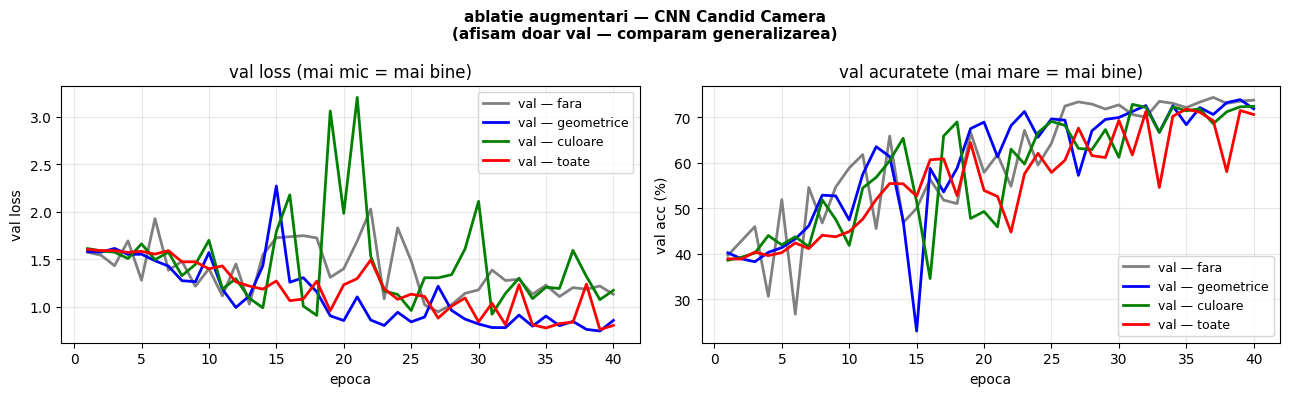

tabel ablatie augmentari — candid camera:
augmentare        accuracy   f1-macro
-------------------------------------
fara                0.7343     0.6400
figura salvata: /kaggle/working/results/cnn/cm_ablatie_aug_none.png


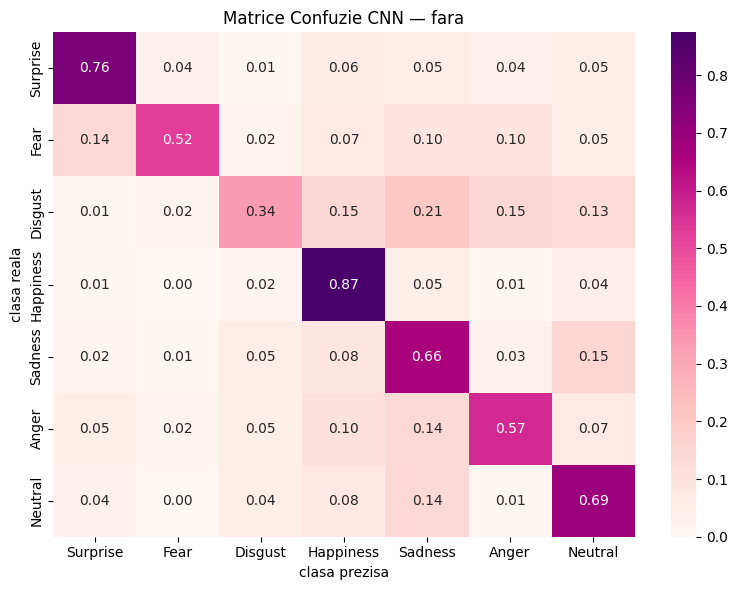

geometrice          0.7392     0.6290
figura salvata: /kaggle/working/results/cnn/cm_ablatie_aug_geo.png


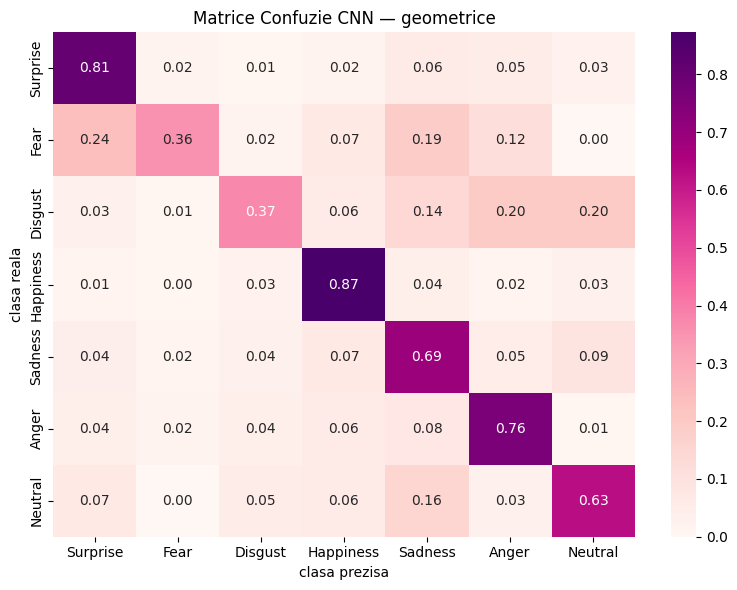

culoare             0.6903     0.5292
figura salvata: /kaggle/working/results/cnn/cm_ablatie_aug_color.png


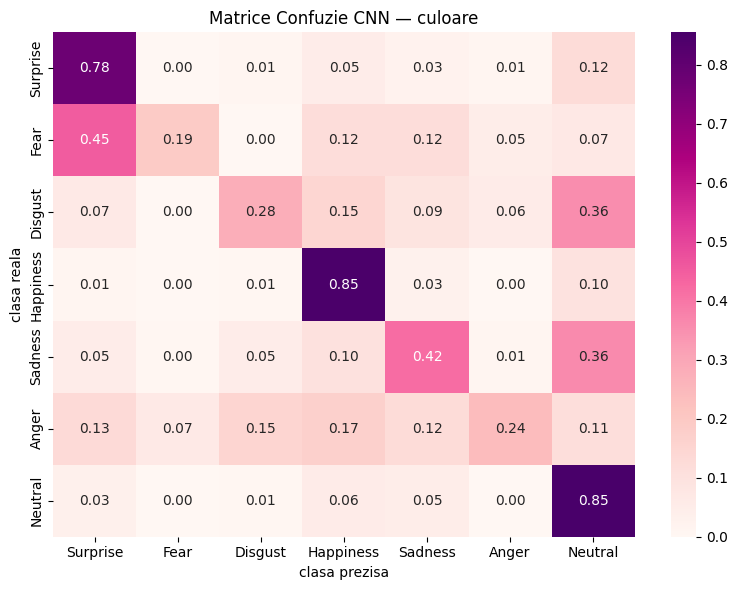

toate               0.7153     0.5992
figura salvata: /kaggle/working/results/cnn/cm_ablatie_aug_all.png


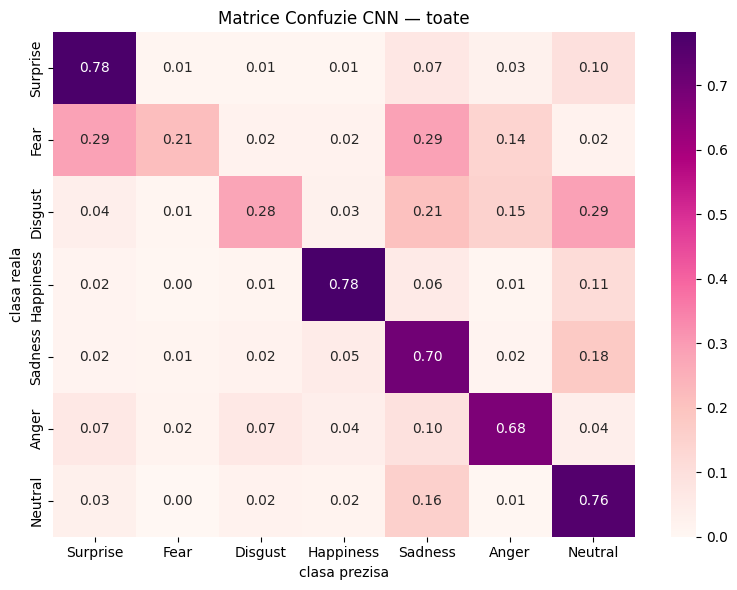

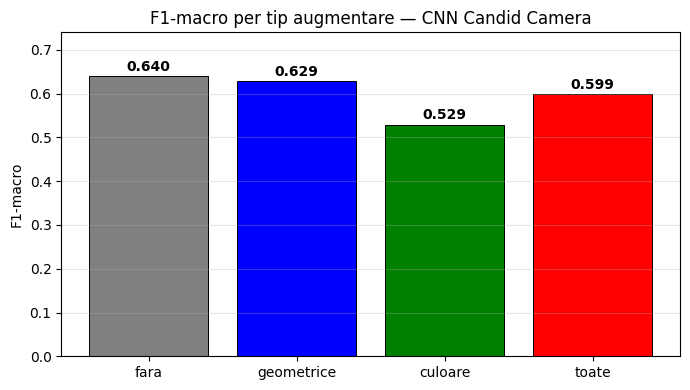

In [42]:
# grafic comparativ: val_loss si val_acc pentru toate 4 configuratiile
# pe acelasi grafic comparar direct care augmentare generalizeaza mai bine
colors = {'none': 'gray', 'geo': 'blue', 'color': 'green', 'all': 'red'}
labels = {'none': 'fara', 'geo': 'geometrice', 'color': 'culoare', 'all': 'toate'}
epochs_aug = range(1, 41)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('ablatie augmentari — CNN Candid Camera\n'
             '(afisam doar val — comparam generalizarea)',
             fontsize=11, fontweight='bold')

for aug_name, hist in aug_histories.items():
    axes[0].plot(epochs_aug, hist['val_loss'],
                 color=colors[aug_name], linewidth=2, label=f'val — {labels[aug_name]}')
    axes[1].plot(epochs_aug, [a*100 for a in hist['val_acc']],
                 color=colors[aug_name], linewidth=2, label=f'val — {labels[aug_name]}')

axes[0].set_xlabel('epoca'); axes[0].set_ylabel('val loss')
axes[0].set_title('val loss (mai mic = mai bine)'); axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel('epoca'); axes[1].set_ylabel('val acc (%)')
axes[1].set_title('val acuratete (mai mare = mai bine)'); axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(CNN_RESULTS_DIR, 'ablatie_augmentari_candid.png'), dpi=150, bbox_inches='tight')
plt.show()

# tabel comparativ metrici finale — cu F1-macro
# Numele claselor pentru axele matricei
CANDID_CLASS_NAMES = ['Surprise', 'Fear', 'Disgust', 'Happiness', 'Sadness', 'Anger', 'Neutral']

# tabel comparativ metrici finale — cu F1-macro + MATRICI DE CONFUZIE
print('tabel ablatie augmentari — candid camera:')
print(f'{"augmentare":15s} {"accuracy":>10s} {"f1-macro":>10s}')
print('-' * 37)
f1_macro_aug = {}

for aug_name, best_path in aug_best_paths.items():
    # 1. Incarcare model si predictii
    m = CNN(num_classes=7, first_kernel_size=3, use_batchnorm=True).to(device)
    m.load_state_dict(torch.load(best_path))
    y_true_a, y_pred_a = get_predictions(m, dl_candid_val, device)
    
    # 2. Calculare si afisare metrici in tabel
    acc = accuracy_score(y_true_a, y_pred_a)
    f1m = f1_score(y_true_a, y_pred_a, average='macro', zero_division=0)
    f1_macro_aug[aug_name] = f1m
    print(f'{labels[aug_name]:15s} {acc:>10.4f} {f1m:>10.4f}')
    
    cale_salvare_cm = os.path.join(CNN_RESULTS_DIR, f'cm_ablatie_aug_{aug_name}.png')
    
    plot_confusion_matrix(
        y_true      = y_true_a, 
        y_pred      = y_pred_a, 
        class_names = CANDID_CLASS_NAMES, 
        title       = f'Matrice Confuzie CNN — {labels[aug_name]}',
        save_path   = cale_salvare_cm
    )

# grafic F1-macro per tip augmentare — pentru raport
fig2, ax2 = plt.subplots(figsize=(7, 4))
aug_labels_list = [labels[k] for k in aug_best_paths.keys()]
f1_vals = [f1_macro_aug[k] for k in aug_best_paths.keys()]
bar_colors = [colors[k] for k in aug_best_paths.keys()]
bars2 = ax2.bar(aug_labels_list, f1_vals, color=bar_colors, edgecolor='black', linewidth=0.7)
for bar, val in zip(bars2, f1_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax2.set_ylim(0, min(1.0, max(f1_vals) + 0.1))
ax2.set_ylabel('F1-macro'); ax2.set_title('F1-macro per tip augmentare — CNN Candid Camera')
ax2.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
fig2.savefig(os.path.join(CNN_RESULTS_DIR, 'f1macro_ablatie_augmentari.png'), dpi=150, bbox_inches='tight')
plt.show()


## 8. salvam rezultatele CNN pe Drive

In [ ]:
# import shutil
# RESULTS_DRIVE_CNN = os.path.join(DRIVE_BASE, 'results/cnn')
# os.makedirs(RESULTS_DRIVE_CNN, exist_ok=True)
# for fname in os.listdir(CNN_RESULTS_DIR):
#     shutil.copy(os.path.join(CNN_RESULTS_DIR, fname),
#                 os.path.join(RESULTS_DRIVE_CNN, fname))
#     print(f'copiat: {fname}')
# print(f'\nrezultate CNN salvate pe drive: {RESULTS_DRIVE_CNN}')


---
---
# Cerinta 3.4 — Fine-tuning pe modele pre-antrenate (Transfer Learning)

## 1. setup si importuri

In [40]:
import torchvision.models as models
from torch.optim.lr_scheduler import LambdaLR, CosineAnnealingLR, SequentialLR

# directorul pentru rezultatele fine-tuning
FT_RESULTS_DIR = '/kaggle/working/results/finetune'
os.makedirs(FT_RESULTS_DIR, exist_ok=True)

print('importuri pentru fine-tuning OK')
print(f'dispozitiv: {device}')


importuri pentru fine-tuning OK
dispozitiv: cuda


## 2. transformari adaptate pentru ResNet (statistici ImageNet)

In [41]:
# augmentari pentru train (cu resize la 224x224 si statistici ImageNet)
ft_candid_train_tf = A.Compose([
    A.Resize(232, 232),
    A.RandomCrop(224, 224),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=10, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=15, p=0.4),
    A.CoarseDropout(num_holes_range=(1,2), hole_height_range=(1,20),
                    hole_width_range=(1,20), p=0.3),
    # statisticile ImageNet, nu cele ale dataset-ului
    # pt ca ponderile pre-antrenate au fost optimizate cu aceste statistici
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

# val/test: fara augmentari aleatoare, doar resize + normalizare ImageNet
ft_candid_val_tf = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

# acelasi lucru pentru piele
ft_piele_train_tf = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Rotate(limit=30, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
    A.HueSaturationValue(hue_shift_limit=8, sat_shift_limit=15, val_shift_limit=10, p=0.4),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

ft_piele_val_tf = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

print('transformari ImageNet definite')
print('rezolutie intrare ResNet: 224x224')
print('statistici: mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]')


transformari ImageNet definite
rezolutie intrare ResNet: 224x224
statistici: mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]


## 3. dataloader-uri pentru fine-tuning

In [42]:
# creez dataset-urile cu noile transformari (224x224, statistici ImageNet)

ds_ft_candid_train = CandidCameraDataset(
    csv_path  = os.path.join(CANDID_ROOT, 'splits/train.csv'),
    root      = CANDID_ROOT,
    transform = ft_candid_train_tf
)
ds_ft_candid_val = CandidCameraDataset(
    csv_path  = os.path.join(CANDID_ROOT, 'splits/local_test.csv'),
    root      = CANDID_ROOT,
    transform = ft_candid_val_tf
)

ds_ft_piele_train = PieleDataset(
    csv_path  = os.path.join(PIELE_ROOT, 'train.csv'),
    img_dir   = os.path.join(PIELE_ROOT, 'train'),
    transform = ft_piele_train_tf
)
ds_ft_piele_val = PieleDataset(
    csv_path  = os.path.join(PIELE_ROOT, 'test.csv'),
    img_dir   = os.path.join(PIELE_ROOT, 'test'),
    transform = ft_piele_val_tf
)

# batch_size=32 in loc de 64:
# imaginile de 224x224 ocupa de ~5.5x mai multa memorie GPU decat 96x96
# (224^2 / 96^2 ≈ 5.44) — cu batch_size=64 am putea depasi VRAM-ul T4 (16GB)
# batch_size=32 e mai sigur si totusi suficient pentru BatchNorm
BATCH_SIZE_FT = 32

dl_ft_candid_train = DataLoader(
    ds_ft_candid_train, batch_size=BATCH_SIZE_FT,
    shuffle=True, num_workers=2, drop_last=True
)
dl_ft_candid_val = DataLoader(
    ds_ft_candid_val, batch_size=BATCH_SIZE_FT,
    shuffle=False, num_workers=2
)

dl_ft_piele_train = DataLoader(
    ds_ft_piele_train, batch_size=BATCH_SIZE_FT,
    shuffle=True, num_workers=2, drop_last=True
)
dl_ft_piele_val = DataLoader(
    ds_ft_piele_val, batch_size=BATCH_SIZE_FT,
    shuffle=False, num_workers=2
)

# verif: un batch de 224x224 ocupa ~32 * 3 * 224 * 224 * 4 bytes ≈ 19 MB
imgs, labels = next(iter(dl_ft_candid_train))
print(f'forma batch candid (224x224): {imgs.shape}')  # asteptat: [32, 3, 224, 224]
print(f'memorie batch estimata: {imgs.element_size() * imgs.nelement() / 1e6:.1f} MB')


forma batch candid (224x224): torch.Size([32, 3, 224, 224])
memorie batch estimata: 19.3 MB


## 4. incarcarea ResNet-18 si inlocuirea capului de clasificare

In [43]:
def build_resnet18(num_classes, freeze_backbone=True):
    # incarc modelul pre-antrenat
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False
        print('backbone inghetat — se antreneaza doar capul de clasificare')

    # ResNet-18 are la final: model.fc = Linear(512, 1000) — pentru 1000 clase ImageNet
    # am 7 clase => trebuie sa inlocuim acest strat
    # nn.Linear(512, num_classes) = noul cap cu num_classes iesiri
    in_features = model.fc.in_features
    model.fc    = nn.Linear(in_features, num_classes)

    print(f'cap de clasificare inlocuit: Linear({in_features}, {num_classes})')
    n_total    = sum(p.numel() for p in model.parameters())
    n_trainable= sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'parametri total: {n_total:,}')
    print(f'parametri antrenabili: {n_trainable:,} ({100*n_trainable/n_total:.1f}% din total)')

    return model

# construiesc modelul pentru candid camera
resnet_candid = build_resnet18(num_classes=7, freeze_backbone=True).to(device)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s] 


backbone inghetat — se antreneaza doar capul de clasificare
cap de clasificare inlocuit: Linear(512, 7)
parametri total: 11,180,103
parametri antrenabili: 3,591 (0.0% din total)


## 5. functia de antrenare cu warmup si cosine annealing

In [44]:
def mixup_batch(images, labels, num_classes, alpha=0.2, device='cpu'):
    # Mixup: combinam doua imagini si etichetele lor in proportii aleatoare.
    # lambda ~ Beta(alpha, alpha); de obicei alpha=0.2 da rezultate bune.
    # x_mix = lam*x_a + (1-lam)*x_b
    # loss  = lam*CE(pred, y_a) + (1-lam)*CE(pred, y_b)
    # Efectul: forteaza reteaua sa invete reprezentari liniare intre clase,
    # reduce overconfidence si imbunatateste generalizarea cu ~1-2%.
    lam = np.random.beta(alpha, alpha)
    batch_size = images.size(0)
    idx = torch.randperm(batch_size).to(device)
    mixed_images = lam * images + (1 - lam) * images[idx]
    y_a, y_b = labels, labels[idx]
    return mixed_images, y_a, y_b, lam


def train_finetune(dataset_name, model, train_loader, val_loader,
                   num_epochs=60, lr=1e-3, weight_decay=1e-4,
                   warmup_epochs=5, use_warmup=True,
                   class_weights=None, use_mixup=False,
                   save_dir=FT_RESULTS_DIR):

    os.makedirs(save_dir, exist_ok=True)

    head_params     = [p for n, p in model.named_parameters()
                       if 'fc' in n and p.requires_grad]
    backbone_params = [p for n, p in model.named_parameters()
                       if 'fc' not in n and p.requires_grad]

    if len(backbone_params) > 0:
        # backbone cu LR de 20x mai mic decat capul
        # AdamW in loc de Adam: weight decay aplicat corect (nu pe bias/batchnorm)
        optimizer = optim.AdamW([
            {'params': backbone_params, 'lr': lr * 0.05},
            {'params': head_params,     'lr': lr},
        ], weight_decay=weight_decay)
    else:
        optimizer = optim.AdamW(head_params, lr=lr, weight_decay=weight_decay)

    if use_warmup:
        warmup_sched = LambdaLR(
            optimizer,
            lr_lambda=lambda e: (e + 1) / warmup_epochs
        )
        cosine_sched = CosineAnnealingLR(
            optimizer,
            T_max=num_epochs - warmup_epochs,
            eta_min=1e-6
        )
        scheduler = SequentialLR(
            optimizer,
            schedulers=[warmup_sched, cosine_sched],
            milestones=[warmup_epochs]
        )
    else:
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode='min', factor=0.5, patience=5
        )

    # label_smoothing=0.1: in loc sa invete sa prezica 1.0 pentru clasa corecta,
    # invata sa prezica 0.9 si 0.1/6 pentru celelalte.
    # previne supraincrederea (overconfidence) si imbunatateste generalizarea cu ~2-3%.
    if class_weights is not None:
        criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
    else:
        criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    writer    = SummaryWriter(log_dir=f'/kaggle/working/runs/ft_{dataset_name}')
    history   = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_loss   = float('inf')
    best_model_path = os.path.join(save_dir, f'ft_{dataset_name}_best.pt')

    print(f'\n=== fine-tuning ResNet-18 pe {dataset_name} ===')
    print(f'epoci={num_epochs} | lr_cap={lr} | lr_backbone={lr*0.05:.6f} | mixup={use_mixup} | device={device}\n')

    for epoch in range(num_epochs):
        # ---- TRAIN ----
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()

            if use_mixup:
                # aplicam mixup pe batch-ul curent
                images_mix, y_a, y_b, lam = mixup_batch(images, labels, num_classes=7, device=device)
                logits = model(images_mix)
                # loss mixup: combinatie liniara intre loss-ul celor doua etichete
                loss = lam * criterion(logits, y_a) + (1 - lam) * criterion(logits, y_b)
                # acuratete aproximativa (pe eticheta predominanta)
                correct += (logits.argmax(1) == y_a).sum().item()
            else:
                logits = model(images)
                loss   = criterion(logits, labels)
                correct += (logits.argmax(1) == labels).sum().item()

            loss.backward()
            # gradient clipping: limiteaza norma gradientilor la 1.0
            # previne exploding gradients care pot destabiliza antrenarea
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item() * images.size(0)
            total      += labels.size(0)
        tr_loss, tr_acc = total_loss / total, correct / total

        # ---- EVAL (loss standard, fara label smoothing, pt comparabilitate) ----
        va_loss, va_acc = evaluate(model, val_loader, nn.CrossEntropyLoss(), device)

        if use_warmup:
            scheduler.step()
        else:
            scheduler.step(va_loss)

        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)

        current_lr = optimizer.param_groups[0]['lr']
        writer.add_scalar('Loss/train', tr_loss, epoch)
        writer.add_scalar('Loss/val',   va_loss, epoch)
        writer.add_scalar('Acc/val',    va_acc,  epoch)
        writer.add_scalar('LR',         current_lr, epoch)

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            torch.save(model.state_dict(), best_model_path)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'epoca {epoch+1:3d}/{num_epochs} | lr={current_lr:.6f} | '
                  f'train loss={tr_loss:.4f} acc={tr_acc:.3f} | '
                  f'val loss={va_loss:.4f} acc={va_acc:.3f}')

    writer.close()
    print(f'\nbest val_loss={best_val_loss:.4f} | model salvat: {best_model_path}')
    return history, best_model_path

print('train_finetune definit')


train_finetune definit


## 6. fine-tuning ResNet-18 — Candid Camera

In [45]:
from torch.utils.data import WeightedRandomSampler

candid_labels = ds_ft_candid_train.df['label_0idx'].values

# frecv fiecarei clase
candid_class_counts = np.bincount(candid_labels)

# ponderile
class_weights = 1.0 / candid_class_counts

candid_sample_weights = torch.from_numpy(class_weights[candid_labels]).double()

sampler_ft_candid = WeightedRandomSampler(
    weights     = candid_sample_weights,
    num_samples = len(ds_ft_candid_train),
    replacement = True
)

dl_ft_candid_train_sampled = DataLoader(
    ds_ft_candid_train,
    batch_size  = 32,
    sampler     = sampler_ft_candid,
    num_workers = 2,
    drop_last   = True
)

resnet_candid_suprem = build_resnet18(num_classes=7, freeze_backbone=False).to(device)

history_ft_candid, best_ft_candid = train_finetune(
    dataset_name  = 'candid_suprem',
    model         = resnet_candid_suprem,
    train_loader  = dl_ft_candid_train_sampled,
    val_loader    = dl_ft_candid_val,
    num_epochs    = 80,
    lr            = 1e-3,
    weight_decay  = 1e-4,
    warmup_epochs = 5,
    use_warmup    = True,
    class_weights = None,
    use_mixup     = True,   # mixup activ: combina imagini si etichete => ~1-2% F1 in plus
    save_dir      = FT_RESULTS_DIR
)


cap de clasificare inlocuit: Linear(512, 7)
parametri total: 11,180,103
parametri antrenabili: 11,180,103 (100.0% din total)

=== fine-tuning ResNet-18 pe candid_suprem ===
epoci=80 | lr_cap=0.001 | lr_backbone=0.000050 | mixup=True | device=cuda

epoca   1/80 | lr=0.000020 | train loss=1.7227 acc=0.257 | val loss=1.3707 acc=0.528
epoca   5/80 | lr=0.000050 | train loss=1.0940 acc=0.503 | val loss=0.8523 acc=0.704
epoca  10/80 | lr=0.000049 | train loss=0.9009 acc=0.550 | val loss=0.7077 acc=0.763
epoca  15/80 | lr=0.000048 | train loss=0.8691 acc=0.573 | val loss=0.6604 acc=0.797
epoca  20/80 | lr=0.000045 | train loss=0.7632 acc=0.534 | val loss=0.6631 acc=0.810
epoca  25/80 | lr=0.000042 | train loss=0.8053 acc=0.570 | val loss=0.6010 acc=0.821
epoca  30/80 | lr=0.000038 | train loss=0.7406 acc=0.602 | val loss=0.6026 acc=0.829
epoca  35/80 | lr=0.000033 | train loss=0.7266 acc=0.570 | val loss=0.5904 acc=0.830
epoca  40/80 | lr=0.000028 | train loss=0.7290 acc=0.576 | val loss=0.60

figura salvata: /kaggle/working/results/finetune/curves_ft_candid.png


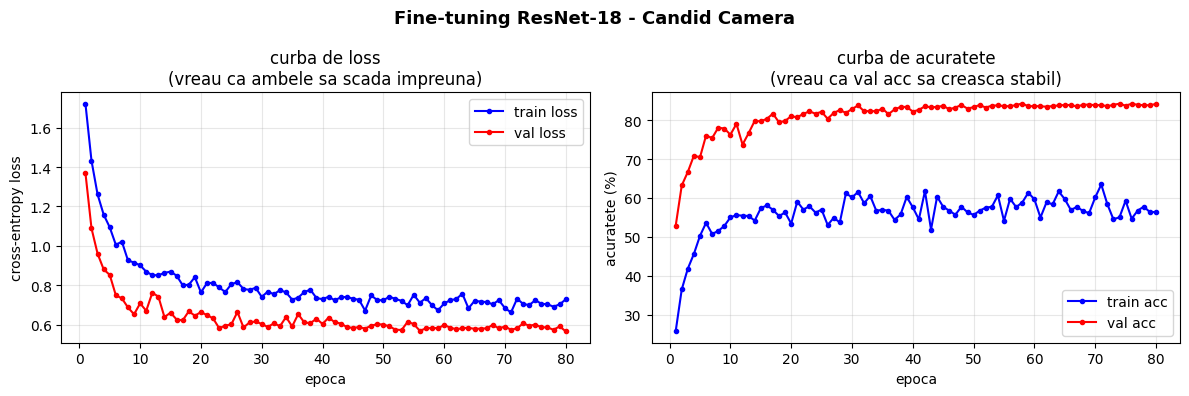

metrici finale fine-tuning ResNet-18 - Candid Camera:
  accuracy : 0.8416 (84.16%)
  f1-macro : 0.7588   <- metrica principala Kaggle
  f1-micro : 0.8416
  f1 per clasa:
    0: Surprise        -> f1=0.8622
    1: Fear            -> f1=0.5397
    2: Disgust         -> f1=0.5638
    3: Happiness       -> f1=0.9291
    4: Sadness         -> f1=0.8212
    5: Anger           -> f1=0.8037
    6: Neutral         -> f1=0.7920
figura salvata: /kaggle/working/results/finetune/cm_ft_candid.png


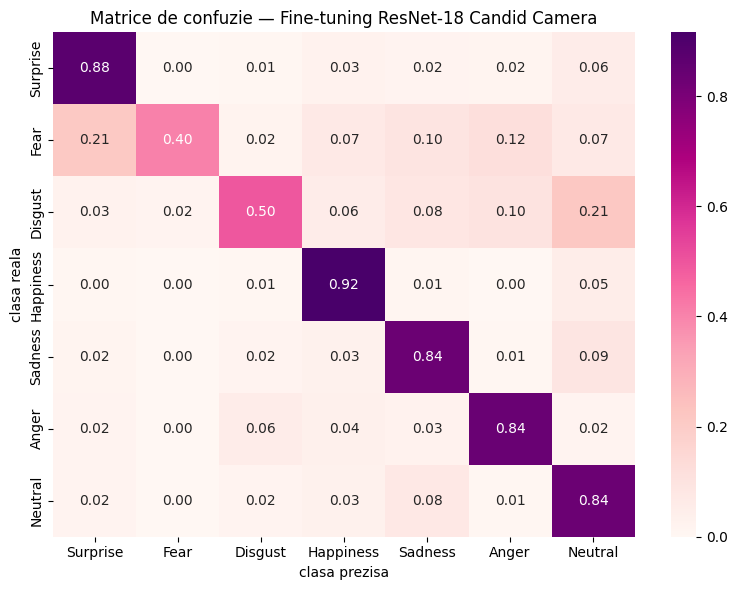

In [47]:
plot_training_curves(
    history_ft_candid,
    title     = 'Fine-tuning ResNet-18 - Candid Camera',
    save_path = os.path.join(FT_RESULTS_DIR, 'curves_ft_candid.png')
)

CANDID_CLASS_NAMES = ['Surprise', 'Fear', 'Disgust', 'Happiness',
                      'Sadness', 'Anger', 'Neutral']

resnet_candid_suprem.load_state_dict(torch.load(best_ft_candid))

y_true_ftc, y_pred_ftc = get_predictions(resnet_candid_suprem, dl_ft_candid_val, device)

print('metrici finale fine-tuning ResNet-18 - Candid Camera:')
print_metrics(y_true_ftc, y_pred_ftc, CANDID_CLASS_NAMES)

plot_confusion_matrix(
    y_true_ftc, y_pred_ftc,
    class_names = CANDID_CLASS_NAMES,
    title       = 'Matrice de confuzie — Fine-tuning ResNet-18 Candid Camera',
    save_path   = os.path.join(FT_RESULTS_DIR, 'cm_ft_candid.png')
);

## 7. fine-tuning ResNet-18 — Vai de Pielea Mea

In [48]:
piele_labels = np.array([PieleDataset.CLASS_TO_IDX[d] for d in ds_ft_piele_train.df['diagnostic']])

# numar frecventa claselor
piele_class_counts = np.bincount(piele_labels)

# ponderi invers proportionale cu frecventa
class_weights_p = 1.0 / piele_class_counts

# ponderi per exemplu
piele_sample_weights = torch.from_numpy(class_weights_p[piele_labels]).double()

sampler_ft_piele = WeightedRandomSampler(
    weights     = piele_sample_weights,
    num_samples = len(ds_ft_piele_train),
    replacement = True
)

dl_ft_piele_train_sampled = DataLoader(
    ds_ft_piele_train,
    batch_size  = 32,
    sampler     = sampler_ft_piele,
    num_workers = 2,
    drop_last   = True
)

resnet_piele_suprem = build_resnet18(num_classes=7, freeze_backbone=False).to(device)

history_ft_piele, best_ft_piele = train_finetune(
    dataset_name  = 'piele_suprem',
    model         = resnet_piele_suprem,
    train_loader  = dl_ft_piele_train_sampled,
    val_loader    = dl_ft_piele_val,
    num_epochs    = 60,
    lr            = 1e-3,
    weight_decay  = 1e-4,
    warmup_epochs = 5,
    use_warmup    = True,
    class_weights = None,
    save_dir      = FT_RESULTS_DIR
)

cap de clasificare inlocuit: Linear(512, 7)
parametri total: 11,180,103
parametri antrenabili: 11,180,103 (100.0% din total)

=== fine-tuning ResNet-18 pe piele_suprem ===
epoci=60 | lr_cap=0.001 | lr_backbone=0.000050 | mixup=False | device=cuda

epoca   1/60 | lr=0.000020 | train loss=1.4872 acc=0.501 | val loss=1.0314 acc=0.627
epoca   5/60 | lr=0.000050 | train loss=0.8908 acc=0.802 | val loss=0.7870 acc=0.697
epoca  10/60 | lr=0.000049 | train loss=0.7300 acc=0.885 | val loss=0.6999 acc=0.740
epoca  15/60 | lr=0.000046 | train loss=0.6556 acc=0.923 | val loss=0.6015 acc=0.787
epoca  20/60 | lr=0.000042 | train loss=0.6106 acc=0.947 | val loss=0.6127 acc=0.792
epoca  25/60 | lr=0.000036 | train loss=0.5678 acc=0.963 | val loss=0.5769 acc=0.808
epoca  30/60 | lr=0.000029 | train loss=0.5459 acc=0.973 | val loss=0.6524 acc=0.795
epoca  35/60 | lr=0.000022 | train loss=0.5297 acc=0.979 | val loss=0.5201 acc=0.841
epoca  40/60 | lr=0.000015 | train loss=0.5168 acc=0.985 | val loss=0.51

figura salvata: /kaggle/working/results/finetune/curves_ft_piele.png


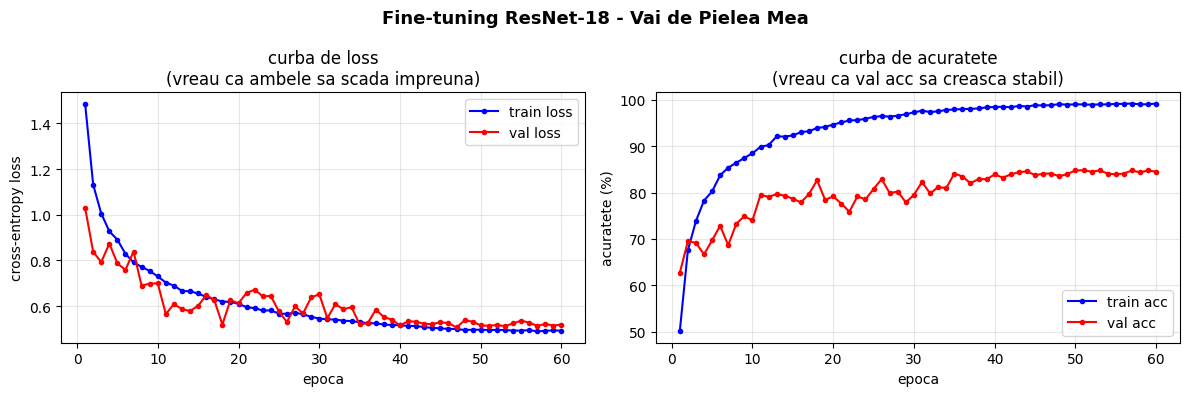

metrici finale fine-tuning ResNet-18 - Vai de Pielea Mea:
  accuracy : 0.8412 (84.12%)
  f1-macro : 0.7442   <- metrica principala Kaggle
  f1-micro : 0.8412
  f1 per clasa:
    0: akiec           -> f1=0.5984
    1: bcc             -> f1=0.7442
    2: bkl             -> f1=0.6827
    3: df              -> f1=0.8000
    4: mel             -> f1=0.6175
    5: nv              -> f1=0.9245
    6: vasc            -> f1=0.8421
figura salvata: /kaggle/working/results/finetune/cm_ft_piele.png


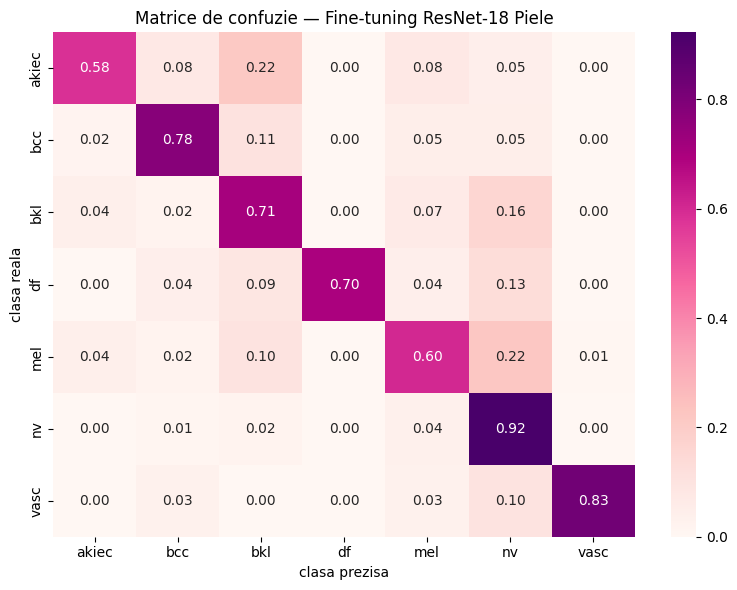

In [49]:
plot_training_curves(
    history_ft_piele,
    title     = 'Fine-tuning ResNet-18 - Vai de Pielea Mea',
    save_path = os.path.join(FT_RESULTS_DIR, 'curves_ft_piele.png')
)

PIELE_CLASS_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

# cel mai bun model
resnet_piele_suprem.load_state_dict(torch.load(best_ft_piele))
y_true_ftp, y_pred_ftp = get_predictions(resnet_piele_suprem, dl_ft_piele_val, device)

print('metrici finale fine-tuning ResNet-18 - Vai de Pielea Mea:')
print_metrics(y_true_ftp, y_pred_ftp, PIELE_CLASS_NAMES)

plot_confusion_matrix(
    y_true_ftp, y_pred_ftp,
    class_names = PIELE_CLASS_NAMES,
    title       = 'Matrice de confuzie — Fine-tuning ResNet-18 Piele',
    save_path   = os.path.join(FT_RESULTS_DIR, 'cm_ft_piele.png')
);

## 8. ablatie: fine-tuning cu inghetare backbone cu warmup vs fara warmup (cerinta 3.5)

In [79]:
print('antrenare RESNET-18 incghetare backbone - ablatie warmup')

# creeaza modelul complet 
resnet_candid_full = build_resnet18(num_classes=7, freeze_backbone=True).to(device)

history_ft, best_ft = train_finetune(
    dataset_name  = 'candid_finetuned',
    model         = resnet_candid_full,
    train_loader  = dl_ft_candid_train_sampled, 
    val_loader    = dl_ft_candid_val,
    num_epochs    = 30,
    lr            = 1e-3,       
    weight_decay  = 1e-4,
    warmup_epochs = 3,
    use_warmup    = True,        
    class_weights = None,        
    save_dir      = FT_RESULTS_DIR
)

antrenare RESNET-18 incghetare backbone - ablatie warmup
backbone inghetat — se antreneaza doar capul de clasificare
cap de clasificare inlocuit: Linear(512, 7)
parametri total: 11,180,103
parametri antrenabili: 3,591 (0.0% din total)

=== fine-tuning ResNet-18 pe candid_finetuned ===
epoci=30 | lr_cap=0.001 | lr_backbone=0.000050 | mixup=False | device=cuda

epoca   1/30 | lr=0.000667 | train loss=1.8427 acc=0.278 | val loss=1.7838 acc=0.282
epoca   5/30 | lr=0.000987 | train loss=1.5659 acc=0.448 | val loss=1.5750 acc=0.401
epoca  10/30 | lr=0.000843 | train loss=1.5204 acc=0.480 | val loss=1.5502 acc=0.431
epoca  15/30 | lr=0.000587 | train loss=1.5123 acc=0.478 | val loss=1.4811 acc=0.442
epoca  20/30 | lr=0.000303 | train loss=1.4913 acc=0.489 | val loss=1.4394 acc=0.465
epoca  25/30 | lr=0.000083 | train loss=1.4688 acc=0.506 | val loss=1.4377 acc=0.471
epoca  30/30 | lr=0.000001 | train loss=1.4695 acc=0.498 | val loss=1.4297 acc=0.482

best val_loss=1.4080 | model salvat: /kagg

In [80]:
# antrenare fara Warmup
resnet_candid_nowarm = build_resnet18(num_classes=7, freeze_backbone=True).to(device)

history_nowarm, best_nowarm = train_finetune(
    dataset_name  = 'candid_nowarm',
    model         = resnet_candid_nowarm,
    train_loader  = dl_ft_candid_train_sampled, 
    val_loader    = dl_ft_candid_val,
    num_epochs    = 30,
    lr            = 1e-3,       
    use_warmup    = False,       
    save_dir      = FT_RESULTS_DIR
)

backbone inghetat — se antreneaza doar capul de clasificare
cap de clasificare inlocuit: Linear(512, 7)
parametri total: 11,180,103
parametri antrenabili: 3,591 (0.0% din total)

=== fine-tuning ResNet-18 pe candid_nowarm ===
epoci=30 | lr_cap=0.001 | lr_backbone=0.000050 | mixup=False | device=cuda

epoca   1/30 | lr=0.001000 | train loss=1.7579 acc=0.334 | val loss=1.6127 acc=0.376
epoca   5/30 | lr=0.001000 | train loss=1.5536 acc=0.454 | val loss=1.4798 acc=0.441
epoca  10/30 | lr=0.001000 | train loss=1.5260 acc=0.477 | val loss=1.4490 acc=0.459
epoca  15/30 | lr=0.000500 | train loss=1.5126 acc=0.477 | val loss=1.5934 acc=0.411
epoca  20/30 | lr=0.000500 | train loss=1.4945 acc=0.489 | val loss=1.4807 acc=0.459
epoca  25/30 | lr=0.000500 | train loss=1.4909 acc=0.492 | val loss=1.5366 acc=0.431
epoca  30/30 | lr=0.000500 | train loss=1.4843 acc=0.497 | val loss=1.3389 acc=0.522

best val_loss=1.3389 | model salvat: /kaggle/working/results/finetune/ft_candid_nowarm_best.pt


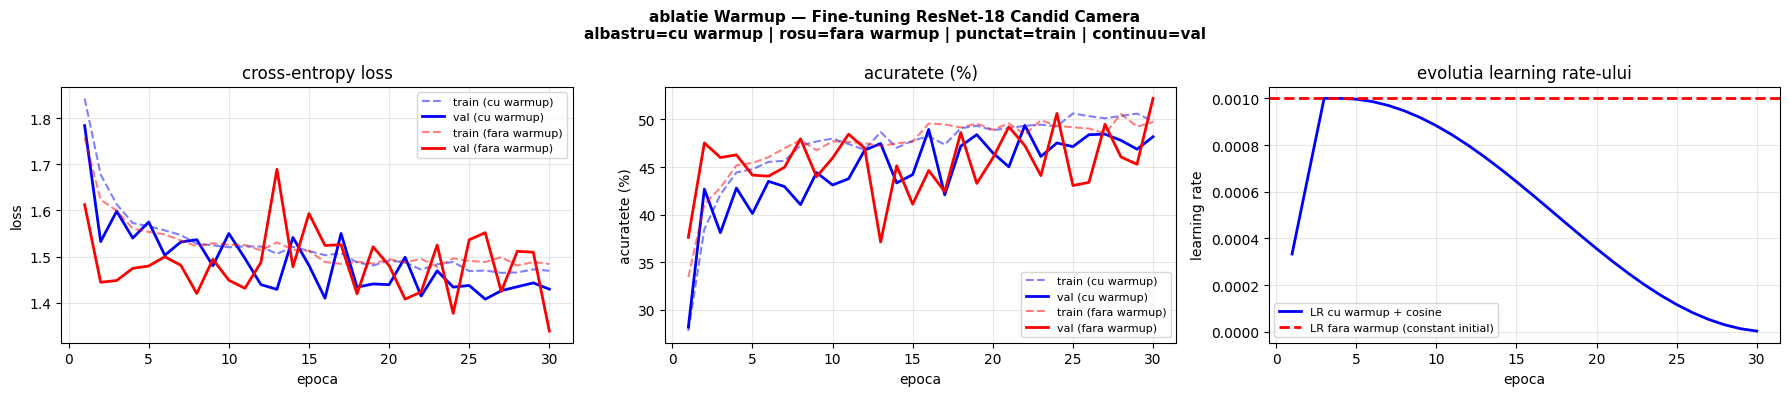

tabel ablatie warmup — fine-tuning ResNet-18 Candid Camera:
varianta                         accuracy   f1-macro
----------------------------------------------------
ResNet-18 cu warmup                0.8416     0.7588
ResNet-18 fara warmup              0.5220     0.4282


In [81]:
# grafic comparativ: cu warmup (albastru) vs fara warmup (rosu)
epochs_warmup = range(1, len(history_ft['train_loss']) + 1)
epochs_nowarm = range(1, len(history_nowarm['train_loss']) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle('ablatie Warmup — Fine-tuning ResNet-18 Candid Camera\n'
             'albastru=cu warmup | rosu=fara warmup | punctat=train | continuu=val',
             fontsize=11, fontweight='bold')

# loss
axes[0].plot(epochs_warmup, history_ft['train_loss'],     'b--', alpha=0.5, label='train (cu warmup)')
axes[0].plot(epochs_warmup, history_ft['val_loss'],       'b-',  linewidth=2, label='val (cu warmup)')
axes[0].plot(epochs_nowarm, history_nowarm['train_loss'], 'r--', alpha=0.5, label='train (fara warmup)')
axes[0].plot(epochs_nowarm, history_nowarm['val_loss'],   'r-',  linewidth=2, label='val (fara warmup)')
axes[0].set_xlabel('epoca'); axes[0].set_ylabel('loss')
axes[0].set_title('cross-entropy loss')
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

# acuratete
axes[1].plot(epochs_warmup, [a*100 for a in history_ft['train_acc']],     'b--', alpha=0.5, label='train (cu warmup)')
axes[1].plot(epochs_warmup, [a*100 for a in history_ft['val_acc']],       'b-',  linewidth=2, label='val (cu warmup)')
axes[1].plot(epochs_nowarm, [a*100 for a in history_nowarm['train_acc']], 'r--', alpha=0.5, label='train (fara warmup)')
axes[1].plot(epochs_nowarm, [a*100 for a in history_nowarm['val_acc']],   'r-',  linewidth=2, label='val (fara warmup)')
axes[1].set_xlabel('epoca'); axes[1].set_ylabel('acuratete (%)')
axes[1].set_title('acuratete (%)')
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

# learning rate per epoca
lrs_warmup = []
for e in range(30):
    if e < 3:
        lrs_warmup.append(1e-3 * (e + 1) / 3)
    else:
        import math
        t    = e - 3
        tmax = 30 - 3
        lrs_warmup.append(1e-3 * 0.5 * (1 + math.cos(math.pi * t / tmax)))

axes[2].plot(epochs_warmup, lrs_warmup, 'b-', linewidth=2, label='LR cu warmup + cosine')
axes[2].axhline(y=1e-3, color='r', linestyle='--', linewidth=2, label='LR fara warmup (constant initial)')
axes[2].set_xlabel('epoca'); axes[2].set_ylabel('learning rate')
axes[2].set_title('evolutia learning rate-ului')
axes[2].legend(fontsize=8); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(FT_RESULTS_DIR, 'ablatie_warmup_candid.png'), dpi=150, bbox_inches='tight')
plt.show()

# tabel comparativ metrici finale
resnet_candid_full.load_state_dict(torch.load(best_ft_candid))
resnet_candid_nowarm.load_state_dict(torch.load(best_nowarm))

y_true_ref2, y_pred_warm  = get_predictions(resnet_candid_full,   dl_ft_candid_val, device)
_,           y_pred_nwarm = get_predictions(resnet_candid_nowarm, dl_ft_candid_val, device)

print('tabel ablatie warmup — fine-tuning ResNet-18 Candid Camera:')
print(f'{"varianta":30s} {"accuracy":>10s} {"f1-macro":>10s}')
print('-' * 52)
for label, yp in [('ResNet-18 cu warmup', y_pred_warm),
                   ('ResNet-18 fara warmup', y_pred_nwarm)]:
    acc = accuracy_score(y_true_ref2, yp)
    f1m = f1_score(y_true_ref2, yp, average='macro', zero_division=0)
    print(f'{label:30s} {acc:>10.4f} {f1m:>10.4f}')


## 9. comparatie finala: MLP vs CNN vs Fine-tuning

aceasta celula sintetizeaza rezultatele tuturor modelelor intr-un singur tabel si grafic.
este utila pentru raport — prezinta clar progresul de la MLP la fine-tuning.


In [5]:
# tabel comparativ final: toate modelele pe ambele dataset-uri
print('COMPARATIE FINALA — toate modelele pe Candid Camera')
print(f'{"model":30s} {"accuracy":>10s} {"f1-macro":>10s}')
print('-' * 52)

modele_candid = [
    ('MLP (cu dropout)',       best_path_candid,  'mlp'),
    ('CNN (cu BN, aug toate)', best_cnn_candid,   'cnn'),
    ('ResNet-18 fine-tuning',  best_ft_candid,    'ft'),
]

rezultate_candid = {}
for model_name, ckpt_path, mtype in modele_candid:
    if mtype == 'mlp':
        m = MLP(input_size=3*96*96, num_classes=7).to(device)
        loader = dl_candid_val
    elif mtype == 'cnn':
        m = CNN(num_classes=7, first_kernel_size=3).to(device)
        loader = dl_candid_val
    else:
        m = build_resnet18(num_classes=7, freeze_backbone=False).to(device)
        loader = dl_ft_candid_val

    m.load_state_dict(torch.load(ckpt_path))
    yt, yp = get_predictions(m, loader, device)
    acc    = accuracy_score(yt, yp)
    f1m    = f1_score(yt, yp, average='macro', zero_division=0)
    rezultate_candid[model_name] = (acc, f1m)
    print(f'{model_name:30s} {acc:>10.4f} {f1m:>10.4f}')

print()
print('COMPARATIE FINALA — toate modelele pe Vai de Pielea Mea')
print(f'{"model":30s} {"accuracy":>10s} {"f1-macro":>10s}')
print('-' * 52)

modele_piele = [
    ('MLP (cu dropout)',       best_path_piele,   'mlp'),
    ('CNN (cu BN, aug toate)', best_cnn_piele,    'cnn'),
    ('ResNet-18 fine-tuning',  best_ft_piele,     'ft'),
]

rezultate_piele = {}
for model_name, ckpt_path, mtype in modele_piele:
    if mtype == 'mlp':
        m = MLP(input_size=3*128*128, num_classes=7).to(device)
        loader = dl_piele_val
    elif mtype == 'cnn':
        m = CNN(num_classes=7, first_kernel_size=5).to(device)
        loader = dl_piele_val
    else:
        m = build_resnet18(num_classes=7, freeze_backbone=False).to(device)
        loader = dl_ft_piele_val

    m.load_state_dict(torch.load(ckpt_path))
    yt, yp = get_predictions(m, loader, device)
    acc    = accuracy_score(yt, yp)
    f1m    = f1_score(yt, yp, average='macro', zero_division=0)
    rezultate_piele[model_name] = (acc, f1m)
    print(f'{model_name:30s} {acc:>10.4f} {f1m:>10.4f}')


COMPARATIE FINALA — toate modelele pe Candid Camera
model                            accuracy   f1-macro
----------------------------------------------------


NameError: name 'best_path_candid' is not defined

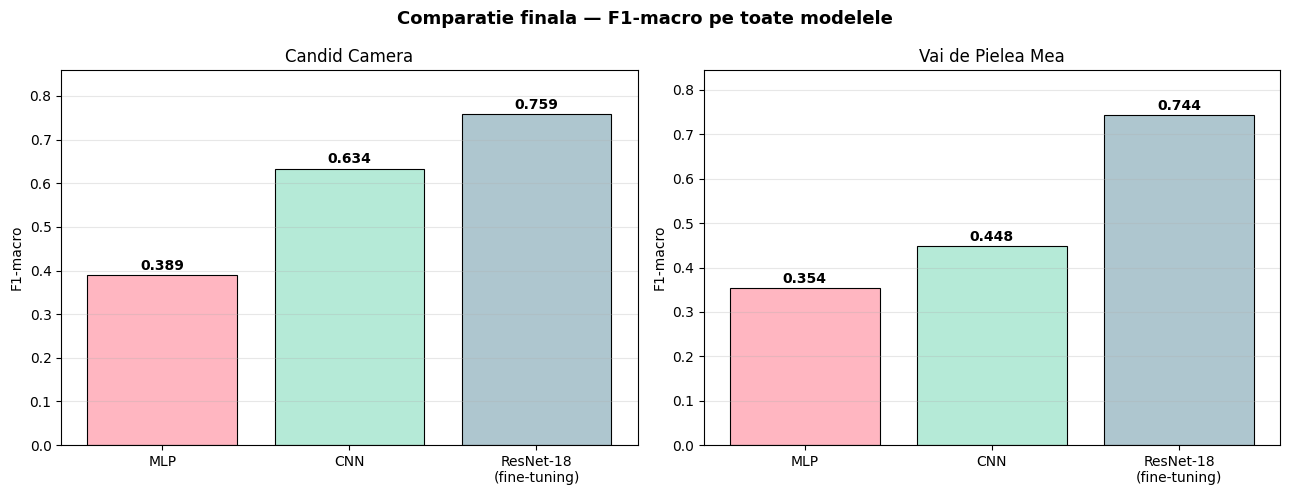

In [83]:
# grafic comparativ final: F1-macro per model pe ambele dataset-uri
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Comparatie finala — F1-macro pe toate modelele', fontsize=13, fontweight='bold')

for ax, rezultate, ds_name in [
    (axes[0], rezultate_candid, 'Candid Camera'),
    (axes[1], rezultate_piele,  'Vai de Pielea Mea')
]:
    model_names = list(rezultate.keys())
    f1_scores   = [rezultate[m][1] for m in model_names]
    colors_bar  = ['#FFB6C1', '#B5EAD7', '#AEC6CF']

    bars = ax.bar(range(len(model_names)), f1_scores,
                  color=colors_bar, edgecolor='black', linewidth=0.8)

    for bar, score in zip(bars, f1_scores):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                f'{score:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

    ax.set_xticks(range(len(model_names)))
    ax.set_xticklabels(['MLP', 'CNN', 'ResNet-18\n(fine-tuning)'], fontsize=10)
    ax.set_ylabel('F1-macro')
    ax.set_title(ds_name)
    ax.set_ylim(0, min(1.0, max(f1_scores) + 0.1))
    ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(FT_RESULTS_DIR, 'comparatie_finala.png'), dpi=150, bbox_inches='tight')
plt.show()


## 10. salvam toate rezultatele fine-tuning pe Drive

In [ ]:
# import shutil

# RESULTS_DRIVE_FT = os.path.join(DRIVE_BASE, 'results/finetune')
# os.makedirs(RESULTS_DRIVE_FT, exist_ok=True)

# for fname in os.listdir(FT_RESULTS_DIR):
#     shutil.copy(
#         os.path.join(FT_RESULTS_DIR, fname),
#         os.path.join(RESULTS_DRIVE_FT, fname)
#     )
#     print(f'copiat: {fname}')

# print(f'\ntoate rezultatele fine-tuning salvate pe drive: {RESULTS_DRIVE_FT}')
# print('\nStructura finala rezultate:')
# print('  results/mlp/       <- figuri si modele MLP')
# print('  results/cnn/       <- figuri si modele CNN')
# print('  results/finetune/  <- figuri si modele fine-tuning')


---
---
# Cerinta 3.5 — Rezultate antrenarii evaluate prin ablatii


## 1. setup

In [44]:
# directorul pentru rezultatele ablatiei dezechilibru
IMBAL_RESULTS_DIR = '/kaggle/working/results/dezechilibru'
os.makedirs(IMBAL_RESULTS_DIR, exist_ok=True)

# vom rula ablatia dezechilibrului pe CNN (cel mai relevant context)
# folosim candid camera si piele — ambele au dezechilibru semnificativ
print('directoare create')
print(f'device: {device}')


directoare create
device: cuda


## 2. calculul ponderilor pentru sampler si weighted loss

In [43]:
import numpy as np
from torch.utils.data import WeightedRandomSampler

# PASUL 1: calcul distributia claselor in setul de train

# candid camera
# df_candid['label'] contine valorile 1..7
# value_counts() numara aparitiile fiecarei valori
# sort_index() le sorteaza dupa indice (1, 2, ..., 7)
candid_class_counts = df_candid['label'].value_counts().sort_index().values

print('distributie clase candid camera:')
for i, (cnt, name) in enumerate(zip(candid_class_counts,
    ['Surprise', 'Fear', 'Disgust', 'Happiness', 'Sadness', 'Anger', 'Neutral'])):
    print(f'  clasa {i+1} ({name:10s}): {cnt:5d} imagini ({100*cnt/sum(candid_class_counts):.1f}%)')

# piele
# df_piele['diagnostic'] contine codurile text (akiec, bcc, etc.)
# CLASS_TO_IDX mapeaza codurile la indici (0..6)
piele_class_counts = np.zeros(7, dtype=int)
for code, idx in PieleDataset.CLASS_TO_IDX.items():
    piele_class_counts[idx] = (df_piele['diagnostic'] == code).sum()
# piele_class_counts = array([196, 308, 660, 69, 668, 4023, 85])
#                              akiec bcc  bkl  df  mel   nv  vasc
print('\ndistributie clase piele:')
piele_names = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
for i, (cnt, name) in enumerate(zip(piele_class_counts, piele_names)):
    print(f'  clasa {i} ({name:5s}): {cnt:5d} imagini ({100*cnt/sum(piele_class_counts):.1f}%)')


distributie clase candid camera:
  clasa 1 (Surprise  ):  1097 imagini (10.5%)
  clasa 2 (Fear      ):   239 imagini (2.3%)
  clasa 3 (Disgust   ):   610 imagini (5.8%)
  clasa 4 (Happiness ):  4057 imagini (38.9%)
  clasa 5 (Sadness   ):  1685 imagini (16.1%)
  clasa 6 (Anger     ):   600 imagini (5.8%)
  clasa 7 (Neutral   ):  2146 imagini (20.6%)

distributie clase piele:
  clasa 0 (akiec):   196 imagini (3.3%)
  clasa 1 (bcc  ):   308 imagini (5.1%)
  clasa 2 (bkl  ):   660 imagini (11.0%)
  clasa 3 (df   ):    69 imagini (1.1%)
  clasa 4 (mel  ):   668 imagini (11.1%)
  clasa 5 (nv   ):  4023 imagini (66.9%)
  clasa 6 (vasc ):    85 imagini (1.4%)


In [45]:
# PASUL 2: calcul ponderile per EXEMPLU pentru WeightedRandomSampler
def compute_sample_weights(labels_array, class_counts):
    class_weights  = 1.0 / class_counts.astype(float)

    # pentru fiecare exemplu, iau ponderea clasei sale
    sample_weights = class_weights[labels_array]

    return torch.from_numpy(sample_weights).double()


# candid: extrag etichetele din dataset
# ds_candid_train.df[] contine etichetele 0-indexed
candid_labels = ds_candid_train.df['label_0idx'].values
candid_sample_weights = compute_sample_weights(candid_labels, candid_class_counts)
print(f'ponderi candid: min={candid_sample_weights.min():.6f}, max={candid_sample_weights.max():.6f}')
print(f'raport max/min = {candid_sample_weights.max()/candid_sample_weights.min():.1f}x')

# piele: extrag etichetele
piele_labels = np.array([PieleDataset.CLASS_TO_IDX[d]
                          for d in ds_piele_train.df['diagnostic']])
piele_sample_weights = compute_sample_weights(piele_labels, piele_class_counts)
print(f'\nponderi piele: min={piele_sample_weights.min():.6f}, max={piele_sample_weights.max():.6f}')
print(f'raport max/min = {piele_sample_weights.max()/piele_sample_weights.min():.1f}x')


ponderi candid: min=0.000246, max=0.004184
raport max/min = 17.0x

ponderi piele: min=0.000249, max=0.014493
raport max/min = 58.3x


In [46]:
# PASUL 3: calcul ponderile per CLASA pentru CrossEntropyLoss
def compute_class_weights(class_counts):
    counts  = torch.tensor(class_counts, dtype=torch.float)
    n_total = counts.sum()
    n_cls   = len(counts)
    weights = n_total / (n_cls * counts)
    return weights.to(device)


candid_class_weights = compute_class_weights(candid_class_counts)
piele_class_weights  = compute_class_weights(piele_class_counts)

print('ponderi per clasa CrossEntropy — Candid Camera:')
for i, (name, w) in enumerate(zip(
        ['Surprise','Fear','Disgust','Happiness','Sadness','Anger','Neutral'],
        candid_class_weights)):
    print(f'  clasa {i} ({name:10s}): w={w:.3f}')

print('\nponderi per clasa CrossEntropy — Piele:')
for i, (name, w) in enumerate(zip(piele_names, piele_class_weights)):
    print(f'  clasa {i} ({name:5s}): w={w:.3f}')


ponderi per clasa CrossEntropy — Candid Camera:
  clasa 0 (Surprise  ): w=1.359
  clasa 1 (Fear      ): w=6.237
  clasa 2 (Disgust   ): w=2.444
  clasa 3 (Happiness ): w=0.367
  clasa 4 (Sadness   ): w=0.885
  clasa 5 (Anger     ): w=2.484
  clasa 6 (Neutral   ): w=0.695

ponderi per clasa CrossEntropy — Piele:
  clasa 0 (akiec): w=4.380
  clasa 1 (bcc  ): w=2.787
  clasa 2 (bkl  ): w=1.301
  clasa 3 (df   ): w=12.441
  clasa 4 (mel  ): w=1.285
  clasa 5 (nv   ): w=0.213
  clasa 6 (vasc ): w=10.099


## 3. functia de antrenare cu tehnici de dezechilibru

In [47]:
def train_with_imbalance_technique(
        dataset_name, base_dataset_train, base_dataset_val,
        sample_weights, class_weights_tensor,
        technique='none', num_epochs=30,
        lr=1e-3, weight_decay=1e-4, save_dir=IMBAL_RESULTS_DIR,
        first_kernel_size=3):
    os.makedirs(save_dir, exist_ok=True)

    # creezdataloader-ul in functie de tehnica aleasa
    if technique == 'sampler':
        # WeightedRandomSampler
        sampler = WeightedRandomSampler(
            weights     = sample_weights,
            num_samples = len(base_dataset_train),
            replacement = True 
        )
        train_loader = DataLoader(
            base_dataset_train,
            batch_size  = 64,
            sampler     = sampler, 
            num_workers = 2,
            drop_last   = True
        )
        criterion = nn.CrossEntropyLoss()  
        print(f'  tehnica: WeightedRandomSampler (oversampling clase rare)')

    elif technique == 'weighted_loss':
        # CrossEntropyLoss cu ponderi per clasa
        train_loader = DataLoader(
            base_dataset_train,
            batch_size  = 64,
            shuffle     = True,
            num_workers = 2,
            drop_last   = True
        )
        criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
        print(f'  tehnica: CrossEntropyLoss ponderat (penalizeaza clase rare)')

    else:  # 'none' = baseline fara nicio tehnica
        train_loader = DataLoader(
            base_dataset_train,
            batch_size  = 64,
            shuffle     = True,
            num_workers = 2,
            drop_last   = True
        )
        criterion = nn.CrossEntropyLoss()  # loss standard
        print(f'  tehnica: niciuna (baseline)')

    # dataloader-ul de validare e mereu acelasi indiferent de tehnica
    val_loader = DataLoader(
        base_dataset_val, batch_size=64, shuffle=False, num_workers=2
    )

    # creez un CNN nou pentru fiecare varianta
    # astfel fiecare varianta porneste de la acelasi punct initial
    model = CNN(
        num_classes       = 7,
        first_kernel_size = first_kernel_size,
        use_batchnorm     = True
    ).to(device)

    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5
    )
    writer = SummaryWriter(
        log_dir=f'/kaggle/working/runs/imbal_{dataset_name}_{technique}'
    )

    history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}
    best_val_loss   = float('inf')
    best_model_path = os.path.join(
        save_dir, f'cnn_{dataset_name}_{technique}_best.pt'
    )

    for epoch in range(num_epochs):
        # ANTRENARE
        # folosim train_one_epoch definit la cerinta 3.2
        model.train()
        total_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss   = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * images.size(0)
            correct    += (logits.argmax(1) == labels).sum().item()
            total      += labels.size(0)
        tr_loss, tr_acc = total_loss/total, correct/total

        # EVALUARE
        va_loss, va_acc = evaluate(model, val_loader,
                                    nn.CrossEntropyLoss(),  # val: mereu loss standard
                                    device)
        # la evaluare folosesc CrossEntropyLoss() standard (fara ponderi)
        # pt ca vr sa masor performanta reala pe distributia originala

        scheduler.step(va_loss)

        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)

        writer.add_scalar(f'Loss/train', tr_loss, epoch)
        writer.add_scalar(f'Loss/val',   va_loss, epoch)
        writer.add_scalar(f'Acc/val',    va_acc,  epoch)

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            torch.save(model.state_dict(), best_model_path)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f'    epoca {epoch+1:3d}/{num_epochs} | '
                  f'train loss={tr_loss:.4f} acc={tr_acc:.3f} | '
                  f'val loss={va_loss:.4f} acc={va_acc:.3f}')

    writer.close()
    return history, best_model_path


print('functia de antrenare cu dezechilibru definita')


functia de antrenare cu dezechilibru definita


## 4. rularea ablatiei dezechilibru — Candid Camera

In [48]:
# antrenez 3 CNN-uri identice, fiecare cu o tehnica diferita
# toate au: aceeasi arhitectura, acelasi optimizer, acelasi lr, aceleasi date

# dataset-urile cu augmentarile complete (definite la cerinta 3.3)
ds_c_train_aug = CandidCameraDataset(
    csv_path  = os.path.join(CANDID_ROOT, 'splits/train.csv'),
    root      = CANDID_ROOT,
    transform = candid_aug_all
)
ds_c_val_aug = CandidCameraDataset(
    csv_path  = os.path.join(CANDID_ROOT, 'splits/local_test.csv'),
    root      = CANDID_ROOT,
    transform = candid_val_transform
)

imbal_histories_candid  = {}  
imbal_best_candid       = {}

techniques = [
    ('none',          'fara nicio tehnica (baseline)'),
    ('sampler',       'WeightedRandomSampler'),
    ('weighted_loss', 'CrossEntropy ponderat'),
]

for technique, description in techniques:
    print(f'\n>>> antrenare: {description}')
    hist, best = train_with_imbalance_technique(
        dataset_name       = 'candid',
        base_dataset_train = ds_c_train_aug,
        base_dataset_val   = ds_c_val_aug,
        sample_weights     = candid_sample_weights,
        class_weights_tensor = candid_class_weights,
        technique          = technique,
        num_epochs         = 30,
        lr                 = 1e-3,
        weight_decay       = 1e-4,
        first_kernel_size  = 3,
        save_dir           = IMBAL_RESULTS_DIR
    )
    imbal_histories_candid[technique] = hist
    imbal_best_candid[technique]      = best

print('\ntoate variantele antrenate pe candid camera!')



>>> antrenare: fara nicio tehnica (baseline)
  tehnica: niciuna (baseline)
    epoca   1/30 | train loss=1.6773 acc=0.370 | val loss=1.5998 acc=0.398
    epoca  10/30 | train loss=1.3039 acc=0.515 | val loss=1.4267 acc=0.462
    epoca  20/30 | train loss=0.8516 acc=0.696 | val loss=0.9392 acc=0.667
    epoca  30/30 | train loss=0.6419 acc=0.774 | val loss=0.9154 acc=0.704

>>> antrenare: WeightedRandomSampler
  tehnica: WeightedRandomSampler (oversampling clase rare)
    epoca   1/30 | train loss=1.9308 acc=0.211 | val loss=1.9464 acc=0.277
    epoca  10/30 | train loss=1.3278 acc=0.512 | val loss=1.7150 acc=0.379
    epoca  20/30 | train loss=0.8932 acc=0.673 | val loss=1.1641 acc=0.585
    epoca  30/30 | train loss=0.5930 acc=0.786 | val loss=0.8964 acc=0.697

>>> antrenare: CrossEntropy ponderat
  tehnica: CrossEntropyLoss ponderat (penalizeaza clase rare)
    epoca   1/30 | train loss=1.9523 acc=0.216 | val loss=1.9253 acc=0.262
    epoca  10/30 | train loss=1.8357 acc=0.277 | val

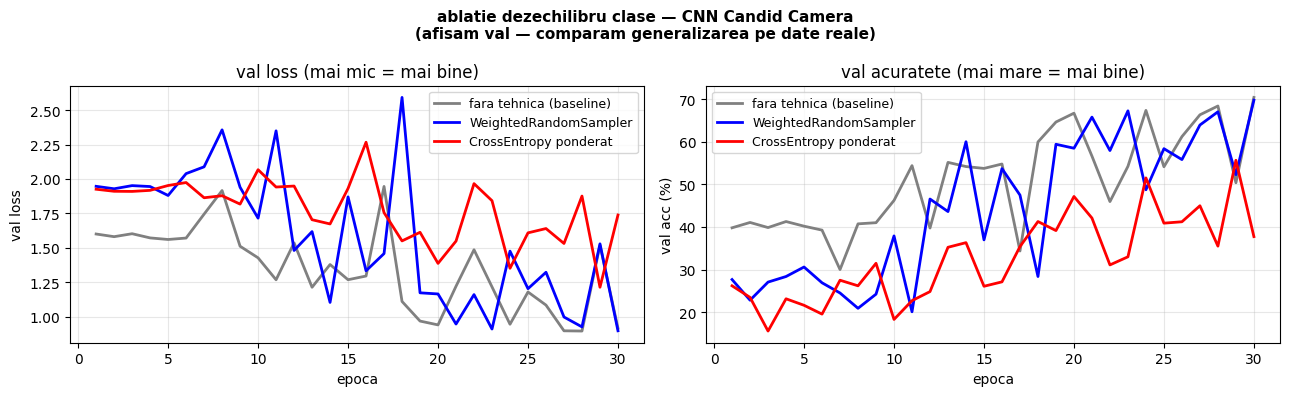

In [49]:
# grafic comparativ: val_loss si val_acc pentru cele 3 tehnici
colors_imbal  = {'none': 'gray', 'sampler': 'blue', 'weighted_loss': 'red'}
labels_imbal  = {
    'none':          'fara tehnica (baseline)',
    'sampler':       'WeightedRandomSampler',
    'weighted_loss': 'CrossEntropy ponderat'
}
epochs_imbal = range(1, 31)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('ablatie dezechilibru clase — CNN Candid Camera\n'
             '(afisam val — comparam generalizarea pe date reale)',
             fontsize=11, fontweight='bold')

for tech, hist in imbal_histories_candid.items():
    c = colors_imbal[tech]
    l = labels_imbal[tech]
    axes[0].plot(epochs_imbal, hist['val_loss'],
                 color=c, linewidth=2, label=l)
    axes[1].plot(epochs_imbal, [a*100 for a in hist['val_acc']],
                 color=c, linewidth=2, label=l)

axes[0].set_xlabel('epoca'); axes[0].set_ylabel('val loss')
axes[0].set_title('val loss (mai mic = mai bine)')
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel('epoca'); axes[1].set_ylabel('val acc (%)')
axes[1].set_title('val acuratete (mai mare = mai bine)')
axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(IMBAL_RESULTS_DIR, 'ablatie_dezechilibru_candid.png'),
            dpi=150, bbox_inches='tight')
plt.show()


tabel ablatie dezechilibru — Candid Camera
tehnica                        accuracy   f1-macro    f1 Fear    f1 Surp
----------------------------------------------------------------------
fara tehnica (baseline)          0.6837     0.5151     0.2264     0.5930
WeightedRandomSampler            0.6973     0.6039     0.3662     0.7416
CrossEntropy ponderat            0.5563     0.4889     0.2553     0.6932

interpretare:
  daca f1-macro creste cu sampler sau weighted_loss => tehnica functioneaza
  daca f1 Fear creste semnificativ => clasele rare beneficiaza de pe urma tehnicii


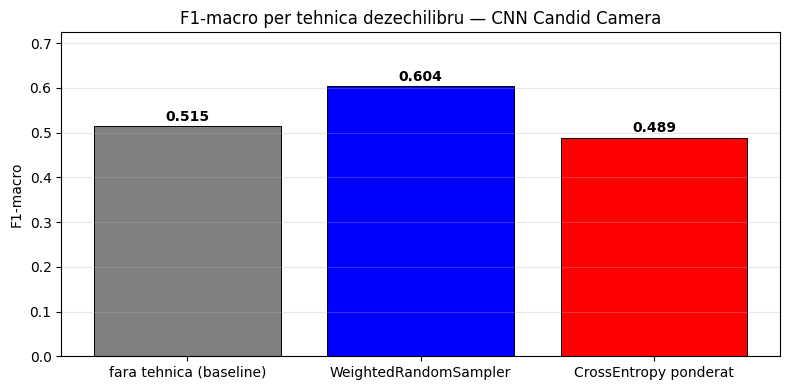

figura salvata: /kaggle/working/results/dezechilibru/cm_candid_none.png


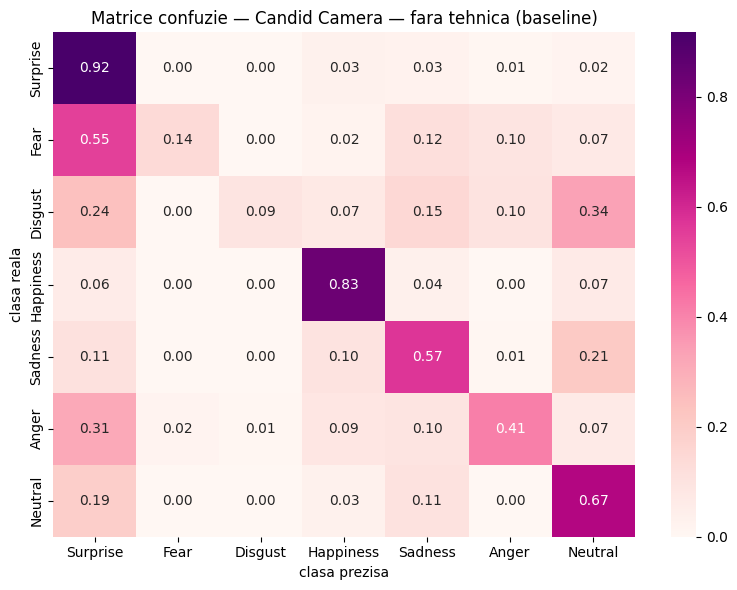

figura salvata: /kaggle/working/results/dezechilibru/cm_candid_sampler.png


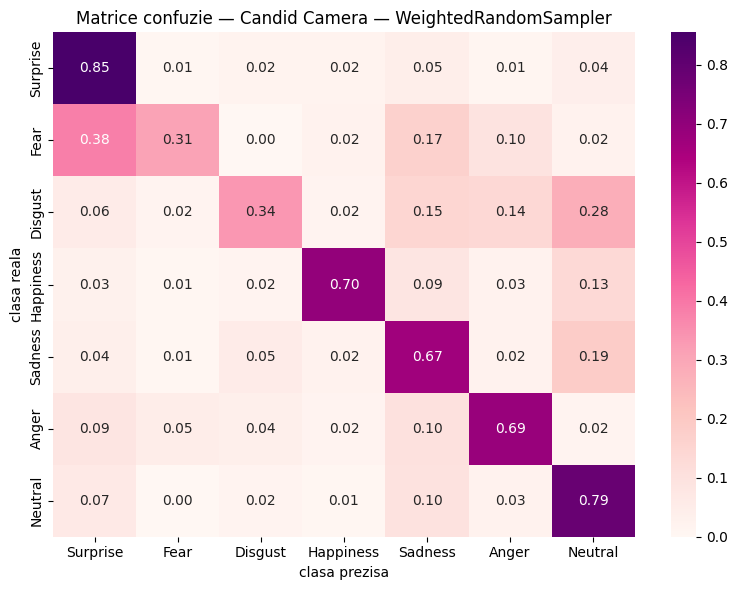

figura salvata: /kaggle/working/results/dezechilibru/cm_candid_weighted_loss.png


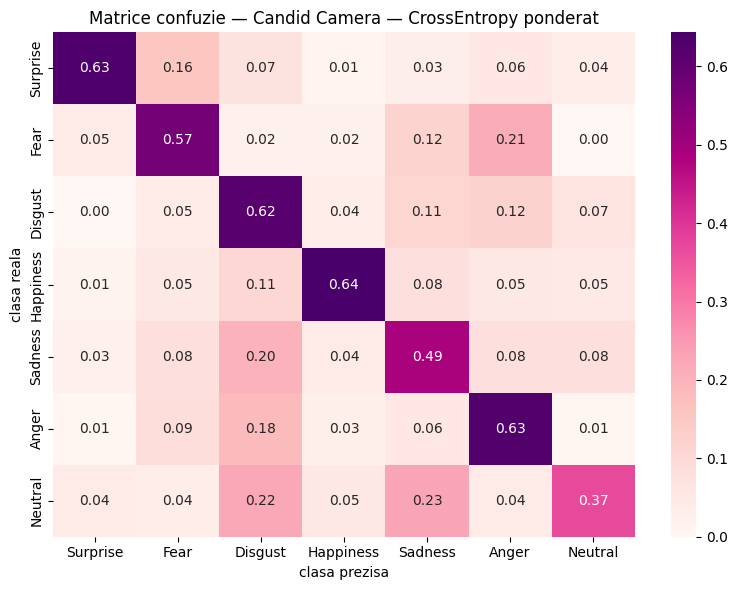

In [50]:
# tabel comparativ metrici: accuracy si f1-macro si f1 per clasa
print('tabel ablatie dezechilibru — Candid Camera')
print('=' * 70)
print(f'{"tehnica":28s} {"accuracy":>10s} {"f1-macro":>10s} {"f1 Fear":>10s} {"f1 Surp":>10s}')
print('-' * 70)

CANDID_CLASS_NAMES = ['Surprise','Fear','Disgust','Happiness','Sadness','Anger','Neutral']

imbal_val_loader_c = DataLoader(ds_c_val_aug, batch_size=64, shuffle=False, num_workers=2)

# retinem predictiile pentru fiecare tehnica (ne trebuie si pentru matrice confuzie)
imbal_preds_candid = {}

for tech, best_path in imbal_best_candid.items():
    # incarcam modelul cel mai bun pentru aceasta tehnica
    m = CNN(num_classes=7, first_kernel_size=3, use_batchnorm=True).to(device)
    m.load_state_dict(torch.load(best_path))
    yt, yp = get_predictions(m, imbal_val_loader_c, device)
    imbal_preds_candid[tech] = (yt, yp)

    acc     = accuracy_score(yt, yp)
    f1_mac  = f1_score(yt, yp, average='macro',  zero_division=0)
    f1_cls  = f1_score(yt, yp, average=None,     zero_division=0)
    # f1_cls[0] = Surprise, f1_cls[1] = Fear
    print(f'{labels_imbal[tech]:28s} {acc:>10.4f} {f1_mac:>10.4f} {f1_cls[1]:>10.4f} {f1_cls[0]:>10.4f}')

print('\ninterpretare:')
print('  daca f1-macro creste cu sampler sau weighted_loss => tehnica functioneaza')
print('  daca f1 Fear creste semnificativ => clasele rare beneficiaza de pe urma tehnicii')

# grafic F1-macro per tehnica — pentru raport
f1_macro_vals = [f1_score(v[0], v[1], average='macro', zero_division=0)
                 for v in imbal_preds_candid.values()]
tech_labels   = [labels_imbal[k] for k in imbal_preds_candid.keys()]
tech_colors   = [colors_imbal[k] for k in imbal_preds_candid.keys()]

fig_f1, ax_f1 = plt.subplots(figsize=(8, 4))
bars_f1 = ax_f1.bar(tech_labels, f1_macro_vals, color=tech_colors, edgecolor='black', linewidth=0.7)
for bar, val in zip(bars_f1, f1_macro_vals):
    ax_f1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
               f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax_f1.set_ylim(0, min(1.0, max(f1_macro_vals) + 0.12))
ax_f1.set_ylabel('F1-macro'); ax_f1.set_title('F1-macro per tehnica dezechilibru — CNN Candid Camera')
ax_f1.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
fig_f1.savefig(os.path.join(IMBAL_RESULTS_DIR, 'f1macro_dezechilibru_candid.png'), dpi=150, bbox_inches='tight')
plt.show()

# matrice de confuzie pentru fiecare tehnica — arata cum se schimba erorile
import matplotlib
for tech, (yt, yp) in imbal_preds_candid.items():
    plot_confusion_matrix(
        yt, yp,
        class_names = CANDID_CLASS_NAMES,
        title       = f'Matrice confuzie — Candid Camera — {labels_imbal[tech]}',
        save_path   = os.path.join(IMBAL_RESULTS_DIR, f'cm_candid_{tech}.png')
    )


## 5. rularea ablatiei dezechilibru — Vai de Pielea Mea

In [51]:
ds_p_train_aug = PieleDataset(
    csv_path  = os.path.join(PIELE_ROOT, 'train.csv'),
    img_dir   = os.path.join(PIELE_ROOT, 'train'),
    transform = piele_aug_all
)
ds_p_val_aug = PieleDataset(
    csv_path  = os.path.join(PIELE_ROOT, 'test.csv'),
    img_dir   = os.path.join(PIELE_ROOT, 'test'),
    transform = piele_val_transform
)

imbal_histories_piele = {}
imbal_best_piele      = {}

for technique, description in techniques:
    print(f'\n>>> antrenare piele: {description}')
    hist, best = train_with_imbalance_technique(
        dataset_name         = 'piele',
        base_dataset_train   = ds_p_train_aug,
        base_dataset_val     = ds_p_val_aug,
        sample_weights       = piele_sample_weights,
        class_weights_tensor = piele_class_weights,
        technique            = technique,
        num_epochs           = 30,
        lr                   = 1e-3,
        weight_decay         = 1e-4,
        first_kernel_size    = 5,   # 5x5 pentru piele (enunt sectiunea 3.3)
        save_dir             = IMBAL_RESULTS_DIR
    )
    imbal_histories_piele[technique] = hist
    imbal_best_piele[technique]      = best

print('\ntoate variantele antrenate pe piele!')



>>> antrenare piele: fara nicio tehnica (baseline)
  tehnica: niciuna (baseline)
    epoca   1/30 | train loss=1.1023 acc=0.630 | val loss=0.9267 acc=0.684
    epoca  10/30 | train loss=0.8108 acc=0.703 | val loss=0.7877 acc=0.712
    epoca  20/30 | train loss=0.7538 acc=0.722 | val loss=0.7502 acc=0.724
    epoca  30/30 | train loss=0.7132 acc=0.731 | val loss=0.6638 acc=0.770

>>> antrenare piele: WeightedRandomSampler
  tehnica: WeightedRandomSampler (oversampling clase rare)
    epoca   1/30 | train loss=1.7327 acc=0.334 | val loss=1.2295 acc=0.526
    epoca  10/30 | train loss=1.1981 acc=0.543 | val loss=1.0320 acc=0.565
    epoca  20/30 | train loss=1.0446 acc=0.604 | val loss=0.9107 acc=0.612
    epoca  30/30 | train loss=0.9132 acc=0.659 | val loss=0.9706 acc=0.614

>>> antrenare piele: CrossEntropy ponderat
  tehnica: CrossEntropyLoss ponderat (penalizeaza clase rare)
    epoca   1/30 | train loss=1.8760 acc=0.392 | val loss=1.5615 acc=0.424
    epoca  10/30 | train loss=1.47

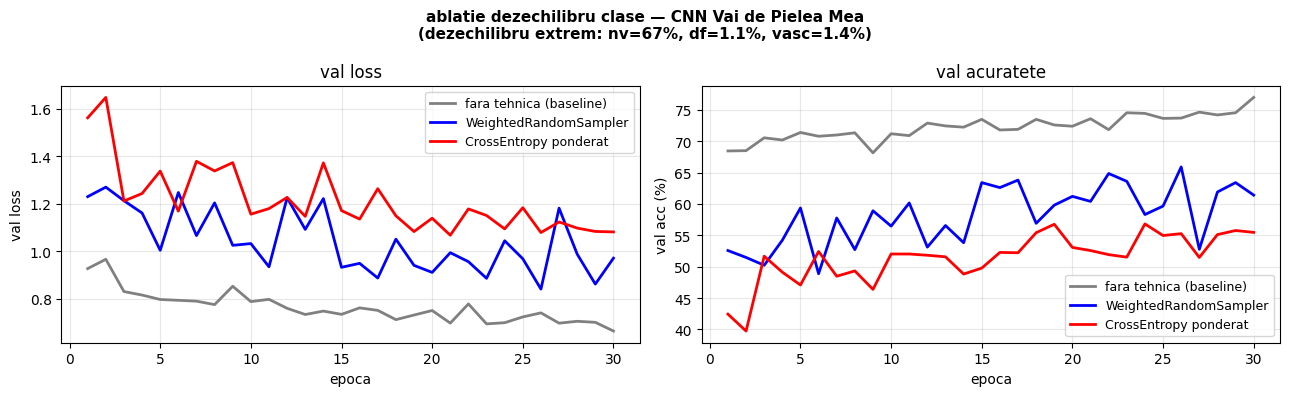

In [52]:
# grafic comparativ piele
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('ablatie dezechilibru clase — CNN Vai de Pielea Mea\n'
             '(dezechilibru extrem: nv=67%, df=1.1%, vasc=1.4%)',
             fontsize=11, fontweight='bold')

for tech, hist in imbal_histories_piele.items():
    c = colors_imbal[tech]
    axes[0].plot(epochs_imbal, hist['val_loss'],
                 color=c, linewidth=2, label=labels_imbal[tech])
    axes[1].plot(epochs_imbal, [a*100 for a in hist['val_acc']],
                 color=c, linewidth=2, label=labels_imbal[tech])

axes[0].set_xlabel('epoca'); axes[0].set_ylabel('val loss')
axes[0].set_title('val loss')
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel('epoca'); axes[1].set_ylabel('val acc (%)')
axes[1].set_title('val acuratete')
axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(IMBAL_RESULTS_DIR, 'ablatie_dezechilibru_piele.png'),
            dpi=150, bbox_inches='tight')
plt.show()


tabel ablatie dezechilibru — Vai de Pielea Mea
tehnica                        accuracy   f1-macro    f1 vasc      f1 nv
----------------------------------------------------------------------
fara tehnica (baseline)          0.7698     0.4850     0.6552     0.8956
WeightedRandomSampler            0.6590     0.4864     0.5870     0.8145
CrossEntropy ponderat            0.5257     0.3582     0.4828     0.6990

- pe piele, accuracy poate scadea cu tehnicile de dezechilibru
motivul: modelul nu mai prezice mereu nv (67%) => accuracy globala scade
dar f1-macro CRESTE => modelul e mai util clinic (detecteaza si clasele rare)


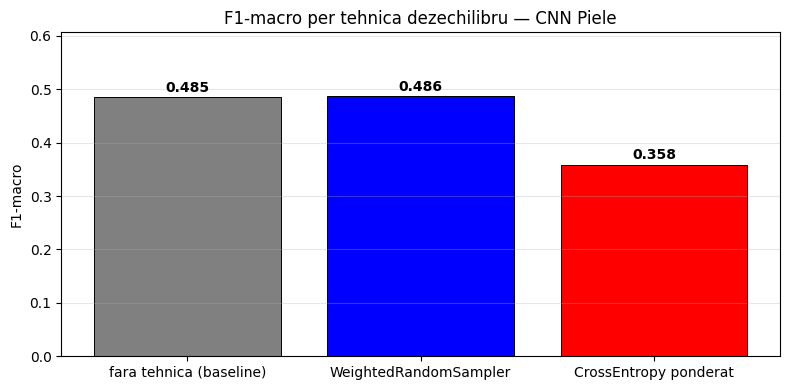

figura salvata: /kaggle/working/results/dezechilibru/cm_piele_none.png


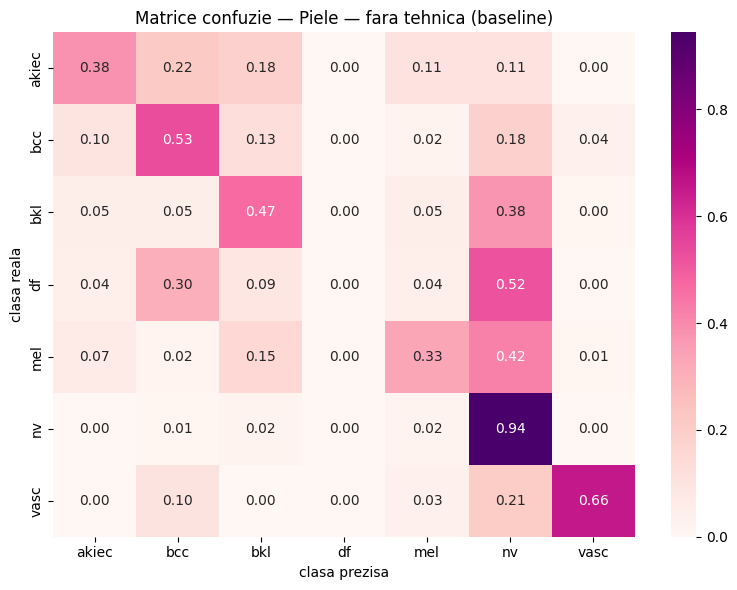

figura salvata: /kaggle/working/results/dezechilibru/cm_piele_sampler.png


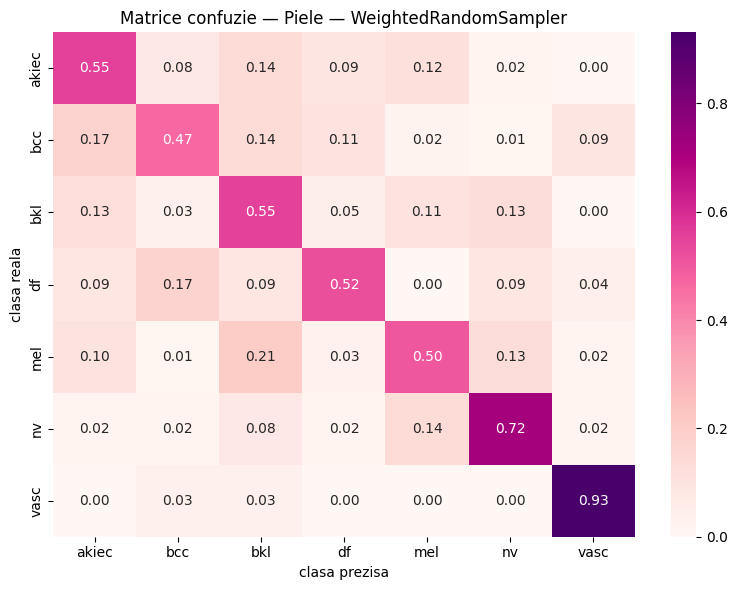

figura salvata: /kaggle/working/results/dezechilibru/cm_piele_weighted_loss.png


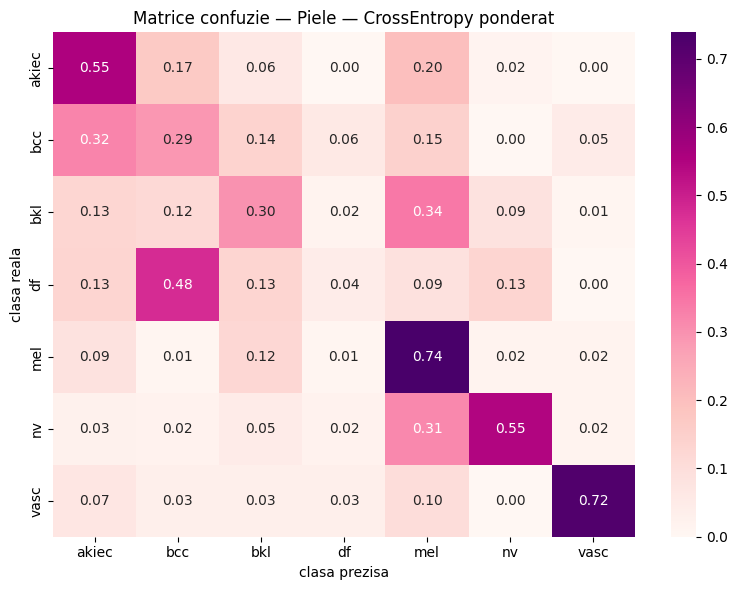

In [53]:
print('tabel ablatie dezechilibru — Vai de Pielea Mea')
print('=' * 70)
print(f'{"tehnica":28s} {"accuracy":>10s} {"f1-macro":>10s} {"f1 vasc":>10s} {"f1 nv":>10s}')
print('-' * 70)

PIELE_CLASS_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
# idx: akiec=0, bcc=1, bkl=2, df=3, mel=4, nv=5, vasc=6

imbal_val_loader_p = DataLoader(ds_p_val_aug, batch_size=64, shuffle=False, num_workers=2)

# retinem predictiile pentru fiecare tehnica
imbal_preds_piele = {}

for tech, best_path in imbal_best_piele.items():
    m = CNN(num_classes=7, first_kernel_size=5, use_batchnorm=True).to(device)
    m.load_state_dict(torch.load(best_path))
    yt, yp  = get_predictions(m, imbal_val_loader_p, device)
    imbal_preds_piele[tech] = (yt, yp)

    acc     = accuracy_score(yt, yp)
    f1_mac  = f1_score(yt, yp, average='macro', zero_division=0)
    f1_cls  = f1_score(yt, yp, average=None,    zero_division=0)
    # f1_cls[5]=nv (clasa majoritara), f1_cls[6]=vasc (clasa cea mai rara)
    print(f'{labels_imbal[tech]:28s} {acc:>10.4f} {f1_mac:>10.4f} {f1_cls[6]:>10.4f} {f1_cls[5]:>10.4f}')

print('\n- pe piele, accuracy poate scadea cu tehnicile de dezechilibru')
print('motivul: modelul nu mai prezice mereu nv (67%) => accuracy globala scade')
print('dar f1-macro CRESTE => modelul e mai util clinic (detecteaza si clasele rare)')

# grafic F1-macro per tehnica piele
f1_macro_vals_p = [f1_score(v[0], v[1], average='macro', zero_division=0)
                   for v in imbal_preds_piele.values()]
tech_labels_p   = [labels_imbal[k] for k in imbal_preds_piele.keys()]
tech_colors_p   = [colors_imbal[k] for k in imbal_preds_piele.keys()]

fig_f1p, ax_f1p = plt.subplots(figsize=(8, 4))
bars_f1p = ax_f1p.bar(tech_labels_p, f1_macro_vals_p, color=tech_colors_p, edgecolor='black', linewidth=0.7)
for bar, val in zip(bars_f1p, f1_macro_vals_p):
    ax_f1p.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax_f1p.set_ylim(0, min(1.0, max(f1_macro_vals_p) + 0.12))
ax_f1p.set_ylabel('F1-macro'); ax_f1p.set_title('F1-macro per tehnica dezechilibru — CNN Piele')
ax_f1p.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
fig_f1p.savefig(os.path.join(IMBAL_RESULTS_DIR, 'f1macro_dezechilibru_piele.png'), dpi=150, bbox_inches='tight')
plt.show()

# matrice de confuzie pentru fiecare tehnica — piele
for tech, (yt, yp) in imbal_preds_piele.items():
    plot_confusion_matrix(
        yt, yp,
        class_names = PIELE_CLASS_NAMES,
        title       = f'Matrice confuzie — Piele — {labels_imbal[tech]}',
        save_path   = os.path.join(IMBAL_RESULTS_DIR, f'cm_piele_{tech}.png')
    )


## 6. tablou centralizat — toate ablatiile


In [77]:
# fiecare ablatie = o comparatie cu/fara un element specific

print('=' * 75)
print('TABLOU CENTRALIZAT — TOATE ABLATIILE (pe Candid Camera)')
print('=' * 75)

# ablatie 1: MLP cu/fara dropout
print('\n1. MLP cu/fara Dropout')
print(f'   {"varianta":25s} {"accuracy":>10s} {"f1-macro":>10s}')
print(f'   {"-"*47}')

mlp_cu   = MLP(input_size=3*96*96, num_classes=7, use_dropout=True).to(device)
mlp_fara = MLP(input_size=3*96*96, num_classes=7, use_dropout=False).to(device)
mlp_cu.load_state_dict(torch.load(best_path_candid))
mlp_fara.load_state_dict(torch.load(best_path_nodrop))

for label, m, loader in [
    ('MLP cu Dropout',   mlp_cu,   dl_candid_val),
    ('MLP fara Dropout', mlp_fara, dl_candid_val),
]:
    yt, yp = get_predictions(m, loader, device)
    acc    = accuracy_score(yt, yp)
    f1m    = f1_score(yt, yp, average='macro', zero_division=0)
    print(f'   {label:25s} {acc:>10.4f} {f1m:>10.4f}')

# ablatie 2: CNN cu/fara BatchNorm
print('\n2. CNN cu/fara BatchNorm')
print(f'   {"varianta":25s} {"accuracy":>10s} {"f1-macro":>10s}')
print(f'   {"-"*47}')

cnn_bn   = CNN(num_classes=7, first_kernel_size=3, use_batchnorm=True).to(device)
cnn_nobn = CNN(num_classes=7, first_kernel_size=3, use_batchnorm=False).to(device)
cnn_bn.load_state_dict(torch.load(best_cnn_candid))
cnn_nobn.load_state_dict(torch.load(best_nobn))

for label, m in [('CNN cu BatchNorm', cnn_bn), ('CNN fara BatchNorm', cnn_nobn)]:
    yt, yp = get_predictions(m, dl_candid_val, device)
    acc    = accuracy_score(yt, yp)
    f1m    = f1_score(yt, yp, average='macro', zero_division=0)
    print(f'   {label:25s} {acc:>10.4f} {f1m:>10.4f}')

# ablatie 3: CNN cu tipuri augmentare
print('\n3. CNN cu diferite augmentari')
print(f'   {"varianta":25s} {"accuracy":>10s} {"f1-macro":>10s}')
print(f'   {"-"*47}')

aug_label_map = {'none':'fara augmentari','geo':'geometrice',
                 'color':'culoare','all':'toate'}
for aug_name, best_path in aug_best_paths.items():
    m = CNN(num_classes=7, first_kernel_size=3, use_batchnorm=True).to(device)
    m.load_state_dict(torch.load(best_path))
    yt, yp = get_predictions(m, dl_candid_val, device)
    acc    = accuracy_score(yt, yp)
    f1m    = f1_score(yt, yp, average='macro', zero_division=0)
    print(f'   {aug_label_map[aug_name]:25s} {acc:>10.4f} {f1m:>10.4f}')

# ablatie 4: dezechilibru clase
print('\n4. Tehnici dezechilibru clase (CNN pe Candid Camera)')
print(f'   {"varianta":28s} {"accuracy":>10s} {"f1-macro":>10s}')
print(f'   {"-"*50}')

for tech, best_path in imbal_best_candid.items():
    m = CNN(num_classes=7, first_kernel_size=3, use_batchnorm=True).to(device)
    m.load_state_dict(torch.load(best_path))
    yt, yp = get_predictions(m, imbal_val_loader_c, device)
    acc    = accuracy_score(yt, yp)
    f1m    = f1_score(yt, yp, average='macro', zero_division=0)
    print(f'   {labels_imbal[tech]:28s} {acc:>10.4f} {f1m:>10.4f}')

# ablatie 5: fine-tuning cu/fara warmup
print('\n5. Fine-tuning cu/fara Warmup (ResNet-18 pe Candid Camera)')
print(f'   {"varianta":30s} {"accuracy":>10s} {"f1-macro":>10s}')
print(f'   {"-"*52}')

for label, best_path in [
    ('ResNet-18 cu Warmup',   best_ft_candid),
    ('ResNet-18 fara Warmup', best_nowarm),
]:
    m = build_resnet18(num_classes=7, freeze_backbone=False).to(device)
    m.load_state_dict(torch.load(best_path))
    yt, yp = get_predictions(m, dl_ft_candid_val, device)
    acc    = accuracy_score(yt, yp)
    f1m    = f1_score(yt, yp, average='macro', zero_division=0)
    print(f'   {label:30s} {acc:>10.4f} {f1m:>10.4f}')

print('\n' + '=' * 75)
print('NOTA: f1-macro este metrica principala de comparare (ceruta pe Kaggle)')
print('=' * 75)


TABLOU CENTRALIZAT — TOATE ABLATIILE (pe Candid Camera)

1. MLP cu/fara Dropout
   varianta                    accuracy   f1-macro
   -----------------------------------------------
   MLP cu Dropout                0.5367     0.3889
   MLP fara Dropout              0.5427     0.4401

2. CNN cu/fara BatchNorm
   varianta                    accuracy   f1-macro
   -----------------------------------------------


NameError: name 'best_nobn' is not defined

## 7. salvam toate rezultatele pe Drive

In [ ]:
# import shutil

# # copiem rezultatele ablatiei dezechilibrului pe Drive
# RESULTS_DRIVE_IMBAL = os.path.join(DRIVE_BASE, 'results/dezechilibru')
# os.makedirs(RESULTS_DRIVE_IMBAL, exist_ok=True)

# for fname in os.listdir(IMBAL_RESULTS_DIR):
#     shutil.copy(
#         os.path.join(IMBAL_RESULTS_DIR, fname),
#         os.path.join(RESULTS_DRIVE_IMBAL, fname)
#     )
#     print(f'copiat: {fname}')

# print(f'\nrezultate dezechilibru salvate: {RESULTS_DRIVE_IMBAL}')
# print('\nstructura completa pe Drive:')
# print('  results/mlp/          <- figuri si modele MLP (cerinta 3.2)')
# print('  results/cnn/          <- figuri si modele CNN (cerinta 3.3)')
# print('  results/finetune/     <- figuri si modele fine-tuning (cerinta 3.4)')
# print('  results/dezechilibru/ <- figuri si modele ablatie dezechilibru (cerinta 3.5)')


In [51]:
# DATASET DE TEST PIELE (kaggle_test)

class PieleTestDataset(Dataset):
    def __init__(self, csv_path, img_dir, transform=None):
        self.df        = pd.read_csv(csv_path)
        self.img_dir   = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        fname  = self.df.iloc[idx]['imagine']  
        path   = os.path.join(self.img_dir, fname)
        img    = Image.open(path).convert('RGB')
        img_np = np.array(img)

        if self.transform is not None:
            img_np = self.transform(image=img_np)['image']

        return img_np, fname


class CandidTestDataset(Dataset):
    def __init__(self, csv_path, test_dir, transform=None):
        self.df        = pd.read_csv(csv_path)
        self.transform = transform

        self.file_index = {}
        for subfolder in os.listdir(test_dir):
            subfolder_path = os.path.join(test_dir, subfolder)
            if not os.path.isdir(subfolder_path):
                continue
            for fname in os.listdir(subfolder_path):
                self.file_index[fname] = os.path.join(subfolder_path, fname)

        print(f'  indexate {len(self.file_index)} imagini de test candid')
        print(f'  exemple din CSV: {len(self.df)} randuri')

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        fname = self.df.iloc[idx]['id'] 
        path  = self.file_index[fname]  

        img    = Image.open(path).convert('RGB')
        img_np = np.array(img)

        if self.transform is not None:
            img_np = self.transform(image=img_np)['image']

        return img_np, fname


print('clase de dataset test definite')


clase de dataset test definite


In [53]:
# creez instantele de dataset si dataloader pentru testul Kaggle

# piele: kaggle test
ds_piele_kaggle = PieleTestDataset(
    csv_path  = os.path.join(PIELE_ROOT, 'kaggle_test.csv'),
    img_dir   = os.path.join(PIELE_ROOT, 'kaggle_test'),
    transform = piele_val_transform  
)

# candid: remote test
ds_candid_remote = CandidTestDataset(
    csv_path  = os.path.join(CANDID_ROOT, 'splits/remote_test.csv'),
    test_dir  = os.path.join(CANDID_ROOT, 'DATASET/test'),
    transform = candid_val_transform  # FARA augmentari
)

# dataloader-uri pentru inferenta
# batch_size=64: la inferenta nu sunt restrictii de memorie ca la train
dl_piele_kaggle  = DataLoader(
    ds_piele_kaggle,  batch_size=64, shuffle=False, num_workers=2
)
dl_candid_remote = DataLoader(
    ds_candid_remote, batch_size=64, shuffle=False, num_workers=2
)

print(f'test piele:  {len(ds_piele_kaggle)} imagini')
print(f'test candid: {len(ds_candid_remote)} imagini')


  indexate 3068 imagini de test candid
  exemple din CSV: 3068 randuri
test piele:  2003 imagini
test candid: 3068 imagini


In [54]:
@torch.no_grad()
def predict_test(model, loader, device):
    # ruleaza modelul pe setul de test si returneaza predictiile
    model.eval()
    all_fnames = []   
    all_preds  = []   

    for images, fnames in loader:
        images = images.to(device)
        logits = model(images)
        preds  = logits.argmax(dim=1).cpu().numpy()

        all_fnames.extend(fnames)   # fnames e o lista de stringuri
        all_preds.extend(preds.tolist())

    return all_fnames, all_preds


functia de inferenta definita


In [55]:
# SUBMISSION PIELE cu TTA (5 variante)
@torch.no_grad()
def predict_test_tta(model, csv_path, img_dir, val_tf, device, batch_size=32):
    # TTA cu 5 variante: original + flip_h + flip_v + rot+10 + rot-10
    model.eval()

    # definesc cele 5 pipeline-uri de TTA
    tta_transforms = [
        val_tf,  # 1. original
        A.Compose([A.Resize(224,224), A.HorizontalFlip(p=1.0),
                   A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]), ToTensorV2()]),
        A.Compose([A.Resize(224,224), A.VerticalFlip(p=1.0),
                   A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]), ToTensorV2()]),
        A.Compose([A.Resize(224,224), A.Rotate(limit=(10,10), p=1.0),
                   A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]), ToTensorV2()]),
        A.Compose([A.Resize(224,224), A.Rotate(limit=(-10,-10), p=1.0),
                   A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]), ToTensorV2()]),
    ]

    all_fnames   = None
    sum_probs    = None

    for tf in tta_transforms:
        ds  = PieleTestDataset(csv_path=csv_path, img_dir=img_dir, transform=tf)
        dl  = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=2)

        batch_fnames, batch_probs = [], []
        for imgs, fnames in dl:
            batch_probs.append(torch.softmax(model(imgs.to(device)), dim=1).cpu())
            batch_fnames.extend(fnames)

        probs = torch.cat(batch_probs, dim=0)   # (N, 7)
        if sum_probs is None:
            sum_probs  = probs
            all_fnames = batch_fnames
        else:
            sum_probs += probs

    avg_probs = sum_probs / len(tta_transforms)
    preds     = avg_probs.argmax(dim=1).numpy().tolist()

    return all_fnames, preds


resnet_piele_submission = build_resnet18(num_classes=7, freeze_backbone=False).to(device)
resnet_piele_submission.load_state_dict(torch.load(best_ft_piele))

print('generez predictii cu TTA (5 variante) pe kaggle_test (piele)...')
fnames_piele, preds_piele = predict_test_tta(
    model     = resnet_piele_submission,
    csv_path  = os.path.join(PIELE_ROOT, 'kaggle_test.csv'),
    img_dir   = os.path.join(PIELE_ROOT, 'kaggle_test'),
    val_tf    = ft_piele_val_tf,
    device    = device
)

df_submission_piele = pd.DataFrame({
    'Id':    fnames_piele,
    'Prediction': preds_piele,
})

print(f'randuri: {len(df_submission_piele)}')
print(df_submission_piele.head())
print(df_submission_piele['Prediction'].value_counts().sort_index())


cap de clasificare inlocuit: Linear(512, 7)
parametri total: 11,180,103
parametri antrenabili: 11,180,103 (100.0% din total)
generez predictii cu TTA (5 variante) pe kaggle_test (piele)...
randuri: 2003
                 Id  Prediction
0  ISIC_0028963.jpg           5
1  ISIC_0028197.jpg           1
2  ISIC_0028464.jpg           5
3  ISIC_0028002.jpg           5
4  ISIC_0024568.jpg           5
Prediction
0      60
1     120
2     234
3      16
4     203
5    1340
6      30
Name: count, dtype: int64


In [56]:
# salvez CSV-ul de submission
SUBMISSION_DIR = '/kaggle/working/submissions'
os.makedirs(SUBMISSION_DIR, exist_ok=True)

# calea fisierului de submission
path_sub_piele = os.path.join(SUBMISSION_DIR, 'submission_piele_resnet18.csv')
df_submission_piele.to_csv(path_sub_piele, index=False)

print(f'CSV salvat: {path_sub_piele}')

print('\nverificare format:')
with open(path_sub_piele, 'r') as f:
    for i, line in enumerate(f):
        print(f'  linia {i}: {line.strip()}')
        if i >= 3:
            break


CSV salvat: /kaggle/working/submissions/submission_piele_resnet18.csv

verificare format:
  linia 0: Id,Prediction
  linia 1: ISIC_0028963.jpg,5
  linia 2: ISIC_0028197.jpg,1
  linia 3: ISIC_0028464.jpg,5


In [ ]:
# generez si submission-urile pentru CNN si MLP

cnn_piele_submission = CNN(num_classes=7, first_kernel_size=5, use_batchnorm=True).to(device)
cnn_piele_submission.load_state_dict(torch.load(best_cnn_piele))

print('generez predictii cu CNN...')
fnames_p_cnn, preds_p_cnn = predict_test(cnn_piele_submission, dl_piele_kaggle, device)
df_sub_piele_cnn = pd.DataFrame({'Id': fnames_p_cnn, 'Prediction': preds_p_cnn})
path_sub_piele_cnn = os.path.join(SUBMISSION_DIR, 'submission_piele_cnn.csv')
df_sub_piele_cnn.to_csv(path_sub_piele_cnn, index=False)
print(f'salvat: {path_sub_piele_cnn}')

mlp_piele_submission = MLP(input_size=3*128*128, num_classes=7).to(device)
mlp_piele_submission.load_state_dict(torch.load(best_path_piele))

print('generez predictii cu MLP...')
ds_piele_kaggle_mlp = PieleTestDataset(
    csv_path  = os.path.join(PIELE_ROOT, 'kaggle_test.csv'),
    img_dir   = os.path.join(PIELE_ROOT, 'kaggle_test'),
    transform = piele_val_transform   # 128x128
)
dl_piele_kaggle_mlp = DataLoader(ds_piele_kaggle_mlp, batch_size=64, shuffle=False, num_workers=2)
fnames_p_mlp, preds_p_mlp = predict_test(mlp_piele_submission, dl_piele_kaggle_mlp, device)
df_sub_piele_mlp = pd.DataFrame({'Id': fnames_p_mlp, 'Prediction': preds_p_mlp})
path_sub_piele_mlp = os.path.join(SUBMISSION_DIR, 'submission_piele_mlp.csv')
df_sub_piele_mlp.to_csv(path_sub_piele_mlp, index=False)
print(f'salvat: {path_sub_piele_mlp}')


In [57]:
# SUBMISSION CANDID cu TTA (5 variante)
@torch.no_grad()
def predict_candid_tta(model, csv_path, test_dir, val_tf, device, batch_size=32):
    # TTA 5 variante pentru candid: original + flip_h + rot+10 + rot-10 + brightness
    # NU flip_v pentru fete (fetele nu apar cu capul in jos)
    model.eval()

    tta_transforms = [
        val_tf,  # 1. original
        A.Compose([A.Resize(224,224), A.HorizontalFlip(p=1.0),
                   A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]), ToTensorV2()]),
        A.Compose([A.Resize(224,224), A.Rotate(limit=(10,10), p=1.0),
                   A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]), ToTensorV2()]),
        A.Compose([A.Resize(224,224), A.Rotate(limit=(-10,-10), p=1.0),
                   A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]), ToTensorV2()]),
        A.Compose([A.Resize(224,224), A.RandomBrightnessContrast(brightness_limit=0.1,
                   contrast_limit=0.1, p=1.0),
                   A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]), ToTensorV2()]),
    ]

    all_fnames = None
    sum_probs  = None

    for tf in tta_transforms:
        ds  = CandidTestDataset(csv_path=csv_path, test_dir=test_dir, transform=tf)
        dl  = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=2)

        batch_fnames, batch_probs = [], []
        for imgs, fnames in dl:
            batch_probs.append(torch.softmax(model(imgs.to(device)), dim=1).cpu())
            batch_fnames.extend(fnames)

        probs = torch.cat(batch_probs, dim=0)
        if sum_probs is None:
            sum_probs  = probs
            all_fnames = batch_fnames
        else:
            sum_probs += probs

    avg_probs  = sum_probs / len(tta_transforms)
    preds_0idx = avg_probs.argmax(dim=1).numpy().tolist()
    preds_1idx = [p + 1 for p in preds_0idx]   # 0-indexed -> 1-indexed (Kaggle vrea 1-7)
    return all_fnames, preds_1idx


resnet_candid_submission = build_resnet18(num_classes=7, freeze_backbone=False).to(device)
resnet_candid_submission.load_state_dict(torch.load(best_ft_candid))

print('generez predictii cu TTA (5 variante) pe remote_test (candid)...')
fnames_candid, preds_candid = predict_candid_tta(
    model     = resnet_candid_submission,
    csv_path  = os.path.join(CANDID_ROOT, 'splits/remote_test.csv'),
    test_dir  = os.path.join(CANDID_ROOT, 'DATASET/test'),
    val_tf    = ft_candid_val_tf,
    device    = device
)

df_submission_candid = pd.DataFrame({'id': fnames_candid, 'label': preds_candid})
path_sub_candid = os.path.join(SUBMISSION_DIR, 'submission_candid_resnet18.csv')
df_submission_candid.to_csv(path_sub_candid, index=False)

print(f'TTA candid salvat: {path_sub_candid}')
print(df_submission_candid['label'].value_counts().sort_index())


cap de clasificare inlocuit: Linear(512, 7)
parametri total: 11,180,103
parametri antrenabili: 11,180,103 (100.0% din total)
generez predictii cu TTA (5 variante) pe remote_test (candid)...
  indexate 3068 imagini de test candid
  exemple din CSV: 3068 randuri
  indexate 3068 imagini de test candid
  exemple din CSV: 3068 randuri
  indexate 3068 imagini de test candid
  exemple din CSV: 3068 randuri
  indexate 3068 imagini de test candid
  exemple din CSV: 3068 randuri
  indexate 3068 imagini de test candid
  exemple din CSV: 3068 randuri
TTA candid salvat: /kaggle/working/submissions/submission_candid_resnet18.csv
label
1     335
2      43
3     116
4    1158
5     512
6     157
7     747
Name: count, dtype: int64


In [58]:
# salvez csv-ul
path_sub_candid = os.path.join(SUBMISSION_DIR, 'submission_candid_resnet18.csv')
df_submission_candid.to_csv(path_sub_candid, index=False)

print(f'CSV salvat: {path_sub_candid}')
print('\nverificare format:')
with open(path_sub_candid, 'r') as f:
    for i, line in enumerate(f):
        print(f'  linia {i}: {line.strip()}')
        if i >= 3:
            break


CSV salvat: /kaggle/working/submissions/submission_candid_resnet18.csv

verificare format:
  linia 0: id,label
  linia 1: test_0789_aligned.jpg,1
  linia 2: test_0200_aligned.jpg,1
  linia 3: test_1342_aligned.jpg,1


In [ ]:
# CNN si MLP pentru candid

cnn_candid_submission = CNN(num_classes=7, first_kernel_size=3, use_batchnorm=True).to(device)
cnn_candid_submission.load_state_dict(torch.load(best_cnn_candid))

print('generez predictii cu CNN (candid)...')
fnames_c_cnn, preds_c_cnn_0 = predict_test(cnn_candid_submission, dl_candid_remote, device)
preds_c_cnn_1 = [p + 1 for p in preds_c_cnn_0]  # 0-indexed -> 1-indexed
df_sub_candid_cnn = pd.DataFrame({'id': fnames_c_cnn, 'label': preds_c_cnn_1})
path_sub_candid_cnn = os.path.join(SUBMISSION_DIR, 'submission_candid_cnn.csv')
df_sub_candid_cnn.to_csv(path_sub_candid_cnn, index=False)
print(f'salvat: {path_sub_candid_cnn}')

mlp_candid_submission = MLP(input_size=3*96*96, num_classes=7).to(device)
mlp_candid_submission.load_state_dict(torch.load(best_path_candid))

print('generez predictii cu MLP (candid)...')
fnames_c_mlp, preds_c_mlp_0 = predict_test(mlp_candid_submission, dl_candid_remote, device)
preds_c_mlp_1 = [p + 1 for p in preds_c_mlp_0]  # 0-indexed -> 1-indexed
df_sub_candid_mlp = pd.DataFrame({'id': fnames_c_mlp, 'label': preds_c_mlp_1})
path_sub_candid_mlp = os.path.join(SUBMISSION_DIR, 'submission_candid_mlp.csv')
df_sub_candid_mlp.to_csv(path_sub_candid_mlp, index=False)
print(f'salvat: {path_sub_candid_mlp}')


In [ ]:
!ls -R /kaggle/working/submissions

In [ ]:
# import shutil

# # copiem toate submission-urile pe Drive
# SUBMISSIONS_DRIVE = os.path.join(DRIVE_BASE, 'submissions')
# os.makedirs(SUBMISSIONS_DRIVE, exist_ok=True)

# for fname in os.listdir(SUBMISSION_DIR):
#     shutil.copy(
#         os.path.join(SUBMISSION_DIR, fname),
#         os.path.join(SUBMISSIONS_DRIVE, fname)
#     )
#     print(f'copiat pe Drive: {fname}')

# print(f'\ntoate submission-urile salvate la: {SUBMISSIONS_DRIVE}')

# # rezumat fisiere generate
# print('\n=== FISIERE GENERATE ===')
# print('PIELE (vai-de-pielea-mea):')
# print(f'  submission_piele_resnet18.csv  <- ResNet-18 fine-tuning (prag: F1>=0.67)')
# print(f'  submission_piele_cnn.csv       <- CNN                  (prag: F1>=0.40)')
# print(f'  submission_piele_mlp.csv       <- MLP                  (prag: F1>=0.20)')
# print('CANDID (you\'re on candid camera):')
# print(f'  submission_candid_resnet18.csv <- ResNet-18 fine-tuning (prag: F1>=0.77)')
# print(f'  submission_candid_cnn.csv      <- CNN                  (prag: F1>=0.35)')
# print(f'  submission_candid_mlp.csv      <- MLP                  (prag: F1>=0.19)')


In [ ]:
# from google.colab import files

# print('descarc fisierele de submission...')

# files.download(os.path.join(SUBMISSION_DIR, 'submission_piele_resnet18.csv'))
# files.download(os.path.join(SUBMISSION_DIR, 'submission_piele_cnn.csv'))
# files.download(os.path.join(SUBMISSION_DIR, 'submission_piele_mlp.csv'))
# files.download(os.path.join(SUBMISSION_DIR, 'submission_candid_resnet18.csv'))
# files.download(os.path.join(SUBMISSION_DIR, 'submission_candid_cnn.csv'))
# files.download(os.path.join(SUBMISSION_DIR, 'submission_candid_mlp.csv'))

# print('toate fisierele descarcate!')


BONUS

In [62]:
# PASUL 1: calcul dificultatea initiala a fiecarui ex
# fol un CNN pre-antrenat (best_cnn_candid) ca estimator de dificultate

@torch.no_grad()
def compute_per_sample_loss(model, dataset, device, batch_size=64):
    # calc loss-ul CrossEntropy pentru fiecare ex din dataset
    # loss mare = modelul e nesigur sau greseste
    # loss mic  = modelul il clasifica corec
    model.eval()
    criterion_nr = nn.CrossEntropyLoss(reduction='none')

    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    all_losses = []

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        losses = criterion_nr(logits, labels)
        all_losses.append(losses.cpu())

    return torch.cat(all_losses)


# PASUL 2: construiesc dataset-ul de candid cu transformarile pentru curriculum
ds_curriculum = CandidCameraDataset(
    csv_path  = os.path.join(CANDID_ROOT, 'splits/train.csv'),
    root      = CANDID_ROOT,
    transform = ft_candid_train_tf
)

# incarc CNN-ul antrenat anterior ca estimator de dificultate initial
cnn_estimator = CNN(num_classes=7, first_kernel_size=3, use_batchnorm=True).to(device)
cnn_estimator.load_state_dict(torch.load(best_cnn_candid))

print('calculez dificultatea initiala a fiecarui exemplu din train...')
initial_losses = compute_per_sample_loss(cnn_estimator, ds_curriculum, device)

print(f'loss minim (cel mai usor): {initial_losses.min():.4f}')
print(f'loss maxim (cel mai greu): {initial_losses.max():.4f}')
print(f'loss median:               {initial_losses.median():.4f}')

# sortez indicii dupa dificultate crescator
sorted_indices = torch.argsort(initial_losses)
print(f'\ntotal exemple: {len(sorted_indices)}')
print('primele 5 (cele mai usoare):')
for idx in sorted_indices[:5]:
    print(f'  idx={idx.item()}, loss={initial_losses[idx].item():.4f}')

calculez dificultatea initiala a fiecarui exemplu din train...
loss minim (cel mai usor): 0.0008
loss maxim (cel mai greu): 14.4736
loss median:               3.3058

total exemple: 10434
primele 5 (cele mai usoare):
  idx=3562, loss=0.0008
  idx=1983, loss=0.0008
  idx=5703, loss=0.0008
  idx=2534, loss=0.0009
  idx=5168, loss=0.0010


In [64]:
# PASUL 3: functia de pacing
# pacing = cat % din date vedem la epoca curenta
# incep cu 30% din date (cele mai usoare) si cresc liniar pana la 100%
# la jumatatea antrenarii am deja toate datele

def pacing_function(epoch, total_epochs, start_frac=0.3):
    progress = epoch / (total_epochs * 0.5)    # 0.0 la inceput, 1.0 la jumatate
    frac     = start_frac + (1.0 - start_frac) * min(progress, 1.0)
    return frac


# verific cum arata functia de pacing
print('evolutia procentului de date expuse per epoca:')
for ep in [0, 5, 10, 20, 30, 40]:
    frac = pacing_function(ep, total_epochs=60)
    n    = int(frac * len(sorted_indices))
    print(f'  epoca {ep:3d}: {frac*100:.1f}% din date = {n} exemple')

evolutia procentului de date expuse per epoca:
  epoca   0: 30.0% din date = 3130 exemple
  epoca   5: 41.7% din date = 4347 exemple
  epoca  10: 53.3% din date = 5564 exemple
  epoca  20: 76.7% din date = 7999 exemple
  epoca  30: 100.0% din date = 10434 exemple
  epoca  40: 100.0% din date = 10434 exemple


In [65]:
# PASUL 4: antrenarea cu curriculum
from torch.utils.data import Subset

def train_curriculum(model, dataset, val_loader, sorted_indices,
                     num_epochs=60, lr=1e-3, weight_decay=1e-4,
                     warmup_epochs=5, save_dir=FT_RESULTS_DIR,
                     dataset_name='curriculum_candid'):
    # la fiecare epoca:
    # 1. calculez ce procent din date sunt expuse (pacing_function)
    # 2. iau primii N indici din sorted_indices (cei mai usori)
    # 3. creez un Subset si un DataLoader din ei
    # 4. antrenez un epoch pe acel subset
    os.makedirs(save_dir, exist_ok=True)

    # optimizer cu LR diferentiat (identic cu train_finetune)
    head_params     = [p for n, p in model.named_parameters()
                       if 'fc' in n and p.requires_grad]
    backbone_params = [p for n, p in model.named_parameters()
                       if 'fc' not in n and p.requires_grad]

    if len(backbone_params) > 0:
        optimizer = optim.AdamW([
            {'params': backbone_params, 'lr': lr * 0.05},
            {'params': head_params,     'lr': lr},
        ], weight_decay=weight_decay)
    else:
        optimizer = optim.AdamW(head_params, lr=lr, weight_decay=weight_decay)

    warmup_sched = LambdaLR(optimizer, lr_lambda=lambda e: (e + 1) / warmup_epochs)
    cosine_sched = CosineAnnealingLR(optimizer, T_max=num_epochs - warmup_epochs, eta_min=1e-6)
    scheduler    = SequentialLR(optimizer, schedulers=[warmup_sched, cosine_sched],
                                milestones=[warmup_epochs])

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [],
               'n_samples': []}   # retinem si cate exemple am folosit per epoca
    best_val_loss   = float('inf')
    best_model_path = os.path.join(save_dir, f'ft_{dataset_name}_best.pt')

    print(f'\n=== Curriculum Learning pe {dataset_name} ===')
    print(f'epoci={num_epochs} | start_frac=30% | device={device}\n')

    for epoch in range(num_epochs):
        # determin subsetul pentru aceasta epoca
        frac      = pacing_function(epoch, num_epochs)
        n_use     = int(frac * len(sorted_indices))
        # luam primii n_use indici din sorted_indices (cei mai usori)
        current_idx = sorted_indices[:n_use].tolist()
        # creez Subset si DataLoader pentru aceasta epoca
        subset = Subset(dataset, current_idx)
        loader = DataLoader(
            subset, batch_size=32, shuffle=True, num_workers=2, drop_last=True
        )

        # TRAIN pe subsetul curent
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss   = criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item() * images.size(0)
            correct    += (logits.argmax(1) == labels).sum().item()
            total      += labels.size(0)
        tr_loss = total_loss / total if total > 0 else 0
        tr_acc  = correct / total if total > 0 else 0

        # EVAL pe setul complet de val
        va_loss, va_acc = evaluate(model, val_loader, nn.CrossEntropyLoss(), device)

        scheduler.step()

        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)
        history['n_samples'].append(n_use)

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            torch.save(model.state_dict(), best_model_path)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f'epoca {epoch+1:3d}/{num_epochs} | '
                  f'subset={n_use}/{len(sorted_indices)} ({frac*100:.0f}%) | '
                  f'train loss={tr_loss:.4f} acc={tr_acc:.3f} | '
                  f'val loss={va_loss:.4f} acc={va_acc:.3f}')

    print(f'\nbest val_loss={best_val_loss:.4f} | model: {best_model_path}')
    return history, best_model_path


# construiesc un ResNet nou pentru curriculum
resnet_curriculum = build_resnet18(num_classes=7, freeze_backbone=False).to(device)

history_curriculum, best_curriculum = train_curriculum(
    model          = resnet_curriculum,
    dataset        = ds_curriculum,
    val_loader     = dl_ft_candid_val,
    sorted_indices = sorted_indices,
    num_epochs     = 60,
    lr             = 1e-3,
    weight_decay   = 1e-4,
    warmup_epochs  = 5,
    dataset_name   = 'curriculum_candid',
    save_dir       = FT_RESULTS_DIR
)

cap de clasificare inlocuit: Linear(512, 7)
parametri total: 11,180,103
parametri antrenabili: 11,180,103 (100.0% din total)

=== Curriculum Learning pe curriculum_candid ===
epoci=60 | start_frac=30% | device=cuda

epoca   1/60 | subset=3130/10434 (30%) | train loss=0.5562 acc=0.976 | val loss=2.6616 acc=0.389
epoca  10/60 | subset=5321/10434 (51%) | train loss=0.5624 acc=0.954 | val loss=1.4411 acc=0.603
epoca  20/60 | subset=7755/10434 (74%) | train loss=0.5649 acc=0.957 | val loss=0.9057 acc=0.704
epoca  30/60 | subset=10190/10434 (98%) | train loss=0.5838 acc=0.952 | val loss=0.5902 acc=0.809
epoca  40/60 | subset=10434/10434 (100%) | train loss=0.4920 acc=0.993 | val loss=0.5809 acc=0.826
epoca  50/60 | subset=10434/10434 (100%) | train loss=0.4724 acc=0.998 | val loss=0.5689 acc=0.831
epoca  60/60 | subset=10434/10434 (100%) | train loss=0.4668 acc=0.999 | val loss=0.5671 acc=0.827

best val_loss=0.5660 | model: /kaggle/working/results/finetune/ft_curriculum_candid_best.pt


In [1]:
# PASUL 5: comparatie curriculum vs standard

resnet_curriculum.load_state_dict(torch.load(best_curriculum))
y_true_curr, y_pred_curr = get_predictions(resnet_curriculum, dl_ft_candid_val, device)

resnet_candid_suprem.load_state_dict(torch.load(best_ft_candid))
y_true_std,  y_pred_std  = get_predictions(resnet_candid_suprem, dl_ft_candid_val, device)

print('COMPARATIE: Curriculum Learning vs Antrenare Standard')
print('=' * 55)
print(f'{"model":30s} {"accuracy":>10s} {"f1-macro":>10s}')
print('-' * 55)
for label, yt, yp in [
    ('ResNet-18 standard',    y_true_std,  y_pred_std),
    ('ResNet-18 curriculum',  y_true_curr, y_pred_curr),
]:
    acc = accuracy_score(yt, yp)
    f1m = f1_score(yt, yp, average='macro', zero_division=0)
    print(f'{label:30s} {acc:>10.4f} {f1m:>10.4f}')

# grafic comparativ: val_acc per epoca
epochs_c  = range(1, len(history_curriculum['val_acc']) + 1)
epochs_s  = range(1, len(history_ft_candid['val_acc']) + 1)
epochs_ns = range(1, len(history_curriculum['n_samples']) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle('Curriculum Learning vs Standard — Candid Camera', fontsize=12, fontweight='bold')

# val loss
axes[0].plot(epochs_s, history_ft_candid['val_loss'],   'b-', linewidth=2, label='standard')
axes[0].plot(epochs_c, history_curriculum['val_loss'],  'r-', linewidth=2, label='curriculum')
axes[0].set_xlabel('epoca'); axes[0].set_ylabel('val loss')
axes[0].set_title('val loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

# val acc
axes[1].plot(epochs_s, [a*100 for a in history_ft_candid['val_acc']],  'b-', linewidth=2, label='standard')
axes[1].plot(epochs_c, [a*100 for a in history_curriculum['val_acc']], 'r-', linewidth=2, label='curriculum')
axes[1].set_xlabel('epoca'); axes[1].set_ylabel('val acc (%)')
axes[1].set_title('val acuratete'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

# numarul de exemple expuse per epoca (evolutia curriculum-ului)
axes[2].plot(epochs_ns, history_curriculum['n_samples'], 'g-', linewidth=2)
axes[2].axhline(y=len(ds_curriculum), color='gray', linestyle='--', label='total date')
axes[2].set_xlabel('epoca'); axes[2].set_ylabel('nr. exemple in subset')
axes[2].set_title('evolutia subsetului curriculum\n(creste de la 30% la 100%)')
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(os.path.join(FT_RESULTS_DIR, 'curriculum_vs_standard.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('figura curriculum salvata')

NameError: name 'resnet_curriculum' is not defined